In [1]:
import pandas as pd
import numpy as np
import sys
import xarray as xr
import seaborn as sns
from scipy import stats
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LogNorm
from IPython.display import Image, display
import glob
# set warning to ignore
import warnings
warnings.filterwarnings("ignore", category=UserWarning, append=True)
sns.set_context("talk", font_scale=0.7)

In [2]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import ecplot as ecplt

stratus_regions = {
    'SEA': {'lat': (-22.5, -5), 'lon': (-5, 15)}, # 'lat': (-20, -10), 'lon': (0, 10) original SEA from Klein and Hartmann
    'NEA': {'lat': (10, 30), 'lon': (-40, -20)},
    'SEP': {'lat': (-22.5, -5), 'lon': (-95, -75)},
    'NEP': {'lat': (15, 35), 'lon': (-135, -115)},
}
stratus_region_names = {
    0: 'SEA',
    1: 'NEA',
    2: 'SEP',
    3: 'NEP',
}

In [3]:
sys.path.append('./../')
sys.path.append('./../src')
import functions as fct
import utils_analysis as uana

In [4]:
from importlib import reload
reload(fct)

<module 'functions' from '/home/jmayer/ACI_research/Code/causal_aci/analysis_stcu/../src/functions.py'>

# Combine judge results with ACMCAP and XMET

## Load the judge dataset

In [13]:
judge_results = '/home/jmayer/ACI_research/Code/resources/judge_results_May-Aug.csv'
df_judge = pd.read_csv(judge_results)
df_judge['time_mid'] = pd.to_datetime(df_judge['time_mid'])

In [14]:
df_judge

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,cats,cert,orbit
0,7318.5,2025-05-01 13:59:51.142630016,-1.150177,-5.623680,-6.094501,-5.054396,0.000000,7.448386,1.856930,0.470947,4,0.989202,05253E
1,7446.5,2025-05-01 13:59:59.206693952,-1.248062,-6.145793,-6.616564,-5.572412,0.000000,7.851930,1.875757,0.284058,5,0.965969,05253E
2,7574.5,2025-05-01 14:00:07.270757568,-1.345993,-6.667884,-7.138586,-6.094501,0.000000,8.201241,1.794974,0.339050,5,0.889194,05253E
3,7702.5,2025-05-01 14:00:15.334820992,-1.444077,-7.189934,-7.660549,-6.616564,0.000000,5.532326,1.345069,0.331726,5,0.576552,05253E
4,7830.5,2025-05-01 14:00:23.398884992,-1.542374,-7.711924,-8.182475,-7.138586,0.000000,3.792587,1.512479,0.276733,4,0.821535,05253E
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10598,1475.5,2025-08-31 22:38:10.006144512,-127.961777,18.226054,17.756157,18.799555,0.333679,0.888200,0.481534,0.777954,1,0.800424,07157E
10599,1603.5,2025-08-31 22:38:18.070211008,-128.066536,17.704388,17.234412,18.277876,0.419067,1.294588,0.472084,0.836731,1,0.654192,07157E
10600,1731.5,2025-08-31 22:38:26.134275008,-128.170982,17.182693,16.712599,17.756157,0.121033,3.670024,0.724053,0.663940,1,0.603443,07157E
10601,1859.5,2025-08-31 22:38:34.198338944,-128.274925,16.660927,16.190693,17.234412,0.020996,3.259478,1.064355,0.452393,0,0.263678,07157E


In [15]:
df_judge.time_mid.min(), df_judge.time_mid.max()

(Timestamp('2025-05-01 13:59:51.142630016'),
 Timestamp('2025-08-31 22:38:42.262401984'))

<Axes: >

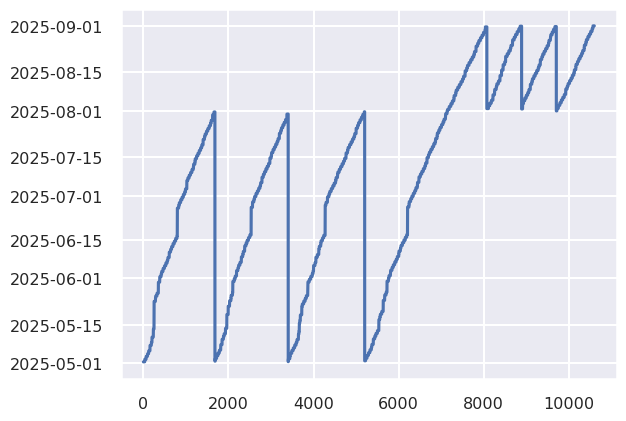

In [27]:
pd.to_datetime(df_judge.time_mid).plot()

In [28]:
df_judge

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,cats,cert,orbit
0,7318.5,2025-05-01 13:59:51.142630016,-1.150177,-5.623680,-6.094501,-5.054396,0.000000,7.448386,1.856930,0.470947,4,0.989202,05253E
1,7446.5,2025-05-01 13:59:59.206693952,-1.248062,-6.145793,-6.616564,-5.572412,0.000000,7.851930,1.875757,0.284058,5,0.965969,05253E
2,7574.5,2025-05-01 14:00:07.270757568,-1.345993,-6.667884,-7.138586,-6.094501,0.000000,8.201241,1.794974,0.339050,5,0.889194,05253E
3,7702.5,2025-05-01 14:00:15.334820992,-1.444077,-7.189934,-7.660549,-6.616564,0.000000,5.532326,1.345069,0.331726,5,0.576552,05253E
4,7830.5,2025-05-01 14:00:23.398884992,-1.542374,-7.711924,-8.182475,-7.138586,0.000000,3.792587,1.512479,0.276733,4,0.821535,05253E
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10598,1475.5,2025-08-31 22:38:10.006144512,-127.961777,18.226054,17.756157,18.799555,0.333679,0.888200,0.481534,0.777954,1,0.800424,07157E
10599,1603.5,2025-08-31 22:38:18.070211008,-128.066536,17.704388,17.234412,18.277876,0.419067,1.294588,0.472084,0.836731,1,0.654192,07157E
10600,1731.5,2025-08-31 22:38:26.134275008,-128.170982,17.182693,16.712599,17.756157,0.121033,3.670024,0.724053,0.663940,1,0.603443,07157E
10601,1859.5,2025-08-31 22:38:34.198338944,-128.274925,16.660927,16.190693,17.234412,0.020996,3.259478,1.064355,0.452393,0,0.263678,07157E


#### tmp: create dataset for Pavlos

In [29]:
# dataset for Pavlos
df_judge_pavlos = df_judge[pd.to_datetime(df_judge.time_mid) >= pd.to_datetime('2025-07-01')].sort_values('time_mid').reset_index(drop=True)
#.to_xarray()

<Axes: >

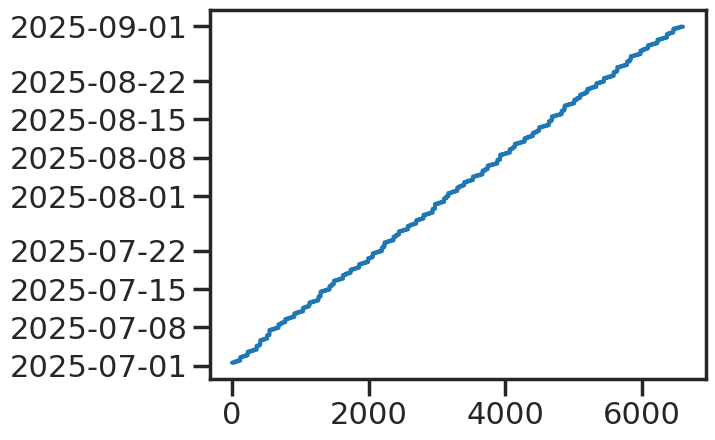

In [30]:
pd.to_datetime(df_judge_pavlos.time_mid).plot()

In [126]:
df_judge_pavlos[['along_track_mid', 'time_mid', 'lon_mid', 'lat_mid', 'lat_min',
       'lat_max', 'ice_flag', 'cats', 'cert', 'orbit']].to_xarray()

<xarray.Dataset> Size: 581kB
Dimensions:          (index: 6603)
Coordinates:
  * index            (index) int64 53kB 0 1 2 3 4 5 ... 6598 6599 6600 6601 6602
Data variables:
    along_track_mid  (index) float64 53kB 7.328e+03 7.456e+03 ... 1.988e+03
    time_mid         (index) datetime64[ns] 53kB 2025-07-01T13:44:26.78708806...
    lon_mid          (index) float64 53kB 2.556 2.458 2.36 ... -128.3 -128.4
    lat_mid          (index) float64 53kB -5.623 -6.146 -6.668 ... 16.66 16.14
    lat_min          (index) float64 53kB -6.094 -6.616 -7.138 ... 16.19 15.67
    lat_max          (index) float64 53kB -5.054 -5.572 -6.094 ... 17.23 16.71
    ice_flag         (index) float64 53kB 0.0 0.0 0.0 0.0 ... 0.121 0.021 0.0285
    cats             (index) int64 53kB 4 0 0 0 0 0 0 0 0 ... 5 5 5 0 1 1 1 0 5
    cert             (index) float64 53kB 0.6233 0.8922 0.7567 ... 0.2637 0.6888
    orbit            (index) object 53kB '06202E' '06202E' ... '07157E' '07157E'

In [34]:
df_judge_pavlos[['along_track_mid', 'time_mid', 'lon_mid', 'lat_mid', 'lat_min',
       'lat_max', 'ice_flag', 'cats', 'cert', 'orbit']].to_xarray().to_netcdf('/home/jmayer/ACI_research/Code/resources/judge_results_Jul-Aug_pavlos.nc')

## Load the dataset for vertical structure

In [22]:
dataset_filename = '/home/jmayer/ACI_research/Code/resources/ACMCAP_XMET_StCu_Jun-Aug.h5'
df0 = pd.read_hdf(dataset_filename, key='StCu')

In [23]:
df0.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1122460 entries, 0 to 1122459
Data columns (total 75 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   along_track                      1122460 non-null  int64         
 1   time                             1122460 non-null  datetime64[ns]
 2   latitude                         1122460 non-null  float64       
 3   longitude                        1122460 non-null  float64       
 4   stratus_region_index             1122460 non-null  int64         
 5   lwp                              1122460 non-null  float32       
 6   ER                               782485 non-null   float32       
 7   ER_passive_perspective           823047 non-null   float32       
 8   Nd                               782485 non-null   float32       
 9   lwp_error                        776364 non-null   float32       
 10  Nd_error                         77

## Combine the information of both datasets

In [29]:
orbits = df_judge.orbit.unique()

In [30]:
print('missing orbits in judge results:')
for orb in df0.orbit.unique():
    if orb not in orbits and orb[-1] in ['D','E']:
        print(orb, '; at ', df0[df0.orbit == orb].time.iloc[0])

missing orbits in judge results:
05859E ; at  2025-06-09 12:45:51.653489920
05860E ; at  2025-06-09 14:14:10.294660864
06248E ; at  2025-07-04 12:45:35.687205120
06249E ; at  2025-07-04 14:13:52.643114624
06497E ; at  2025-07-20 12:47:53.699026944
06637E ; at  2025-07-29 12:45:10.650576512
06638E ; at  2025-07-29 14:13:20.880204928
05895E ; at  2025-06-11 20:13:14.260404224
06143E ; at  2025-06-27 18:47:36.456587648
06284E ; at  2025-07-06 20:12:49.283435520
06673E ; at  2025-07-31 20:12:30.662240256
05752D ; at  2025-06-02 15:31:02.711238400
05783E ; at  2025-06-04 15:23:24.284435072
05784D ; at  2025-06-04 16:51:34.653826176
05892D ; at  2025-06-11 15:28:30.087864448
06141D ; at  2025-06-27 15:30:57.509406208
06172E ; at  2025-06-29 15:23:19.799025920
06173D ; at  2025-06-29 16:51:33.712374272
06530D ; at  2025-07-22 15:30:31.561864832
06561E ; at  2025-07-24 15:22:58.544452608
06562D ; at  2025-07-24 16:51:07.643695616
05865D ; at  2025-06-09 21:49:24.058819328
06254D ; at  2025-07-

In [31]:
df = df0[df0.orbit.isin(orbits)]

In [32]:
df

,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,lwp_error,...,xmet_cbh,xmet_cth_m,xmet_cbh_m,xmet_low_cloud_cover_binary,xmet_low_cloud_cover_original,xmet_lwp,xmet_rwp,xmet_rwp_subcloud,xmet_rwc_cbh,ocean_mask
0,2981,2025-06-01 13:26:02.599795968,-5.001905,7.111185,0,0.000051,8.760879e-07,8.760849e-07,54752600.00,0.478148,...,NaN,NaN,NaN,0.0,0.003203,0.0,0.0,0.0,NaN,True
1,2982,2025-06-01 13:26:02.736145920,-5.010733,7.109528,0,0.007185,4.358948e-06,4.684363e-06,55660160.00,0.330290,...,NaN,NaN,NaN,0.0,0.003203,0.0,0.0,0.0,NaN,True
2,2983,2025-06-01 13:26:02.872495872,-5.019562,7.107870,0,0.000300,1.552164e-06,1.558314e-06,57090188.00,0.479258,...,NaN,NaN,NaN,0.0,0.003203,0.0,0.0,0.0,NaN,True
3,2984,2025-06-01 13:26:03.008845952,-5.028391,7.106212,0,0.011196,4.916011e-06,5.970363e-06,62343752.00,0.341860,...,NaN,NaN,NaN,0.0,0.003203,0.0,0.0,0.0,NaN,True
4,2985,2025-06-01 13:26:03.190764032,-5.040170,7.104001,0,0.025249,6.399618e-06,6.650821e-06,65047464.00,0.376912,...,NaN,NaN,NaN,0.0,0.003203,0.0,0.0,0.0,NaN,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1122455,815,2025-08-31 22:38:59.105735936,15.043125,-128.786007,3,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.0,0.046493,0.0,0.0,0.0,NaN,True
1122456,816,2025-08-31 22:38:59.240677504,15.034392,-128.787718,3,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.0,0.073524,0.0,0.0,0.0,NaN,True
1122457,817,2025-08-31 22:38:59.375615872,15.025658,-128.789429,3,0.009169,1.312405e-05,1.326506e-05,2855815.25,0.088560,...,NaN,NaN,NaN,0.0,0.073524,0.0,0.0,0.0,NaN,True
1122458,818,2025-08-31 22:38:59.510556032,15.016924,-128.791140,3,0.027764,1.224727e-05,1.237362e-05,8873747.00,0.370534,...,NaN,NaN,NaN,0.0,0.073524,0.0,0.0,0.0,NaN,True


In [33]:
# the scenes are oversampled: each scene is classified twice, once in the box towards the left and once to the right
# we add columns to store the two classifications and other info
df['cats_0'] = 6
df['cats_1'] = 6
df['cert_0'] = -1
df['cert_1'] = -1
df['ice_flag_0'] = -1
df['ice_flag_1'] = -1
df['scene_id_0'] = -1
df['scene_id_1'] = -1
df['MCOP_cloud_cover_judge_0'] = -1
df['MCOP_cloud_cover_judge_1'] = -1
df['MCOP_cwp_skew_judge_0'] = -1
df['MCOP_cwp_skew_judge_1'] = -1
df['MCOP_cwp_inhomogeneity_judge_0'] = -1
df['MCOP_cwp_inhomogeneity_judge_1'] = -1

i = 0
j = 0
unique_orbits = df_judge.orbit.unique()
print(f'Number of unique orbits in judge results: {len(unique_orbits)}')
for orbit in unique_orbits:
    j += 1
    print(j, '/',len(unique_orbits), '; ', orbit)
    df_judge_orbit = df_judge[df_judge['orbit']==orbit]
    if df[(df.orbit == orbit)].empty:
        print(f'No matching orbit {orbit} in dataset')
    else:
        for idx, row in df_judge_orbit.iterrows():
            lat_min = row['lat_min']
            lat_max = row['lat_max']
            if len(df[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max)]) > 0:
                if df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'scene_id_0'].iloc[0] == -1:
                    suffix = '0'
                else:
                    suffix = '1'
                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'cats_{}'.format(suffix)] = row['cats']
                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'cert_{}'.format(suffix)] = row['cert']
                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'ice_flag_{}'.format(suffix)] = row['ice_flag']
                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'scene_id_{}'.format(suffix)] = i
                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'MCOP_cloud_cover_judge_{}'.format(suffix)] = row['cloud_cover']
                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'MCOP_cwp_skew_judge_{}'.format(suffix)] = row['cwp_skew']
                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'MCOP_cwp_inhomogeneity_judge_{}'.format(suffix)] = row['cwp_inhomogeneity']
                i += 1
            else:
                print(f'No matching latitudes for orbit {orbit} between {lat_min} and {lat_max}')


Number of unique orbits in judge results: 526
1 / 526 ;  05253E
No matching orbit 05253E in dataset
2 / 526 ;  05268E
No matching orbit 05268E in dataset
3 / 526 ;  05284E
No matching orbit 05284E in dataset
4 / 526 ;  05299E
No matching orbit 05299E in dataset
5 / 526 ;  05315E
No matching orbit 05315E in dataset
6 / 526 ;  05346E
No matching orbit 05346E in dataset
7 / 526 ;  05362E
No matching orbit 05362E in dataset
8 / 526 ;  05393E
No matching orbit 05393E in dataset
9 / 526 ;  05439E
No matching orbit 05439E in dataset
10 / 526 ;  05595E
No matching orbit 05595E in dataset
11 / 526 ;  05611E
No matching orbit 05611E in dataset
12 / 526 ;  05626E
No matching orbit 05626E in dataset
13 / 526 ;  05642E
No matching orbit 05642E in dataset
14 / 526 ;  05704E
No matching orbit 05704E in dataset
15 / 526 ;  05735E
16 / 526 ;  05751E
17 / 526 ;  05766E
18 / 526 ;  05782E
19 / 526 ;  05797E
20 / 526 ;  05813E
21 / 526 ;  05828E
22 / 526 ;  05844E
23 / 526 ;  05875E
24 / 526 ;  05891E
25 

In [34]:
df

,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,lwp_error,...,ice_flag_0,ice_flag_1,scene_id_0,scene_id_1,MCOP_cloud_cover_judge_0,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1
0,2981,2025-06-01 13:26:02.599795968,-5.001905,7.111185,0,0.000051,8.760879e-07,8.760849e-07,54752600.00,0.478148,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1,2982,2025-06-01 13:26:02.736145920,-5.010733,7.109528,0,0.007185,4.358948e-06,4.684363e-06,55660160.00,0.330290,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
2,2983,2025-06-01 13:26:02.872495872,-5.019562,7.107870,0,0.000300,1.552164e-06,1.558314e-06,57090188.00,0.479258,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
3,2984,2025-06-01 13:26:03.008845952,-5.028391,7.106212,0,0.011196,4.916011e-06,5.970363e-06,62343752.00,0.341860,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
4,2985,2025-06-01 13:26:03.190764032,-5.040170,7.104001,0,0.025249,6.399618e-06,6.650821e-06,65047464.00,0.376912,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1122455,815,2025-08-31 22:38:59.105735936,15.043125,-128.786007,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1122456,816,2025-08-31 22:38:59.240677504,15.034392,-128.787718,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1122457,817,2025-08-31 22:38:59.375615872,15.025658,-128.789429,3,0.009169,1.312405e-05,1.326506e-05,2855815.25,0.088560,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1122458,818,2025-08-31 22:38:59.510556032,15.016924,-128.791140,3,0.027764,1.224727e-05,1.237362e-05,8873747.00,0.370534,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0


In [35]:
df[['latitude','longitude','orbit','cats_0','cert_0','scene_id_0','cats_1','cert_1','scene_id_1']].iloc[50:100]

,latitude,longitude,orbit,cats_0,cert_0,scene_id_0,cats_1,cert_1,scene_id_1
50,-5.464009,7.024341,05735E,5,0.996926,0,6,-1.00000,-1
51,-5.472840,7.022679,05735E,5,0.996926,0,6,-1.00000,-1
52,-5.481671,7.021017,05735E,5,0.996926,0,6,-1.00000,-1
53,-5.493437,7.018804,05735E,5,0.996926,0,6,-1.00000,-1
54,-5.502268,7.017143,05735E,5,0.996926,0,6,-1.00000,-1
55,-5.511099,7.015482,05735E,5,0.996926,0,6,-1.00000,-1
56,-5.519930,7.013820,05735E,5,0.996926,0,6,-1.00000,-1
57,-5.528761,7.012159,05735E,5,0.996926,0,6,-1.00000,-1
58,-5.537592,7.010497,05735E,5,0.996926,0,6,-1.00000,-1
59,-5.546422,7.008836,05735E,5,0.996926,0,6,-1.00000,-1


In [ ]:
# for judge results that are not overlapping

#df['cats'] = 6
#df['cert'] = -1
#df['ice_flag'] = -1
#df['scene_id'] = -1
#df['MCOP_cloud_cover_judge'] = -1
#df['MCOP_cwp_skew_judge'] = -1
#df['MCOP_cwp_inhomogeneity_judge'] = -1
#
#i = 0
#j = 0
#unique_orbits = df_judge.orbit.unique()
#print(f'Number of unique orbits in judge results: {len(unique_orbits)}')
#for orbit in unique_orbits:
#    j += 1
#    print(j, '/',len(unique_orbits), '; ', orbit)
#    df_judge_orbit = df_judge[df_judge['orbit']==orbit]
#    if df[(df.orbit == orbit)].empty:
#        print(f'No matching orbit {orbit} in dataset')
#    else:
#        for idx, row in df_judge_orbit.iterrows():
#            lat_min = row['lat_min']
#            lat_max = row['lat_max']
#            if len(df[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max)]) > 0:
#                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'cats'] = row['cats']
#                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'cert'] = row['cert']
#                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'ice_flag'] = row['ice_flag']
#                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'scene_id'] = i
#                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'MCOP_cloud_cover_judge'] = row['cloud_cover']
#                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'MCOP_cwp_skew_judge'] = row['cwp_skew']
#                df.loc[(df.orbit == orbit) & (df.latitude >= lat_min) & (df.latitude <= lat_max), 'MCOP_cwp_inhomogeneity_judge'] = row['cwp_inhomogeneity']
#                i += 1
#            else:
#                print(f'No matching latitudes for orbit {orbit} between {lat_min} and {lat_max}')

### create ocean mask

In [17]:

def create_ocean_mask_optimized(df0, lat_col='latitude', lon_col='longitude'):
    """
    Create a mask for ocean points using Natural Earth coastlines with optimized filtering
    """
    import cartopy.io.shapereader as shpreader
    import numpy as np
    from shapely.geometry import Point
    
    lats = df0[lat_col].values
    lons = df0[lon_col].values
    scregion = df0['stratus_region_index'].values
    
    # Step 1: Create rough ocean masks for points that are definitely over ocean
    # These are conservative estimates based on your stratus regions
    definite_ocean_masks = [
        # SEA region - exclude obvious land areas (Africa, Madagascar)
        (scregion == 0) & (lons < 10),
        
        # NEA region - exclude obvious land areas (Africa, Europe)  
        (scregion == 1),
        
        # SEP region - exclude obvious land areas (South America)
        ((scregion == 2) & (lons < -82)) | (scregion == 2) & (lats < -16),
        
        # NEP region - exclude obvious land areas (North America) 
        ((scregion == 3) & (lons < -122)) | (scregion == 3) & (lats < 27),
    ]
    
    # Combine all definite ocean points
    definite_ocean = np.zeros(len(df0), dtype=bool)
    for mask in definite_ocean_masks:
        definite_ocean |= mask
    
    print(f"Quick filter: {np.sum(definite_ocean)} points definitely over ocean")
    
    # Step 2: For remaining points, do precise land geometry check
    uncertain_points = ~definite_ocean
    n_uncertain = np.sum(uncertain_points)
    print(f"Need detailed check for {n_uncertain} uncertain points")
    
    if n_uncertain == 0:
        return definite_ocean
    
    # Load land geometries only if needed
    land_shp = shpreader.natural_earth(resolution='50m', category='physical', name='land')
    land_geoms = [record.geometry for record in shpreader.Reader(land_shp).records()]
    
    # Create points only for uncertain locations
    uncertain_lats = lats[uncertain_points]
    uncertain_lons = lons[uncertain_points]
    uncertain_ocean = np.zeros(n_uncertain, dtype=bool)
    
    # Batch process uncertain points for efficiency
    print("Processing uncertain points in batches...")
    batch_size = 1000
    for i in range(0, n_uncertain, batch_size):
        end_idx = min(i + batch_size, n_uncertain)
        batch_lats = uncertain_lats[i:end_idx]
        batch_lons = uncertain_lons[i:end_idx]
        
        for j, (lat, lon) in enumerate(zip(batch_lats, batch_lons)):
            point = Point(lon, lat)
            is_over_land = False
            
            # Check against land geometries
            for land_geom in land_geoms:
                if land_geom.contains(point):
                    is_over_land = True
                    break
            
            uncertain_ocean[i + j] = not is_over_land
        
        if (i // batch_size) % 10 == 0:
            print(f"  Processed {min(end_idx, n_uncertain)}/{n_uncertain} uncertain points")
    
    # Combine results
    final_ocean_mask = definite_ocean.copy()
    final_ocean_mask[uncertain_points] = uncertain_ocean
    
    print(f"Final result: {np.sum(final_ocean_mask)} total ocean points")
    return final_ocean_mask

In [ ]:
ocean_mask = create_ocean_mask_optimized(df, lat_col='latitude', lon_col='longitude')

Quick filter: 397152 points definitely over ocean
Need detailed check for 60444 uncertain points
Processing uncertain points in batches...
  Processed 1000/60444 uncertain points
  Processed 11000/60444 uncertain points
  Processed 21000/60444 uncertain points
  Processed 31000/60444 uncertain points
  Processed 41000/60444 uncertain points
  Processed 51000/60444 uncertain points
  Processed 60444/60444 uncertain points
Final result: 435772 total ocean points


In [ ]:
df['ocean_mask'] = ocean_mask

<Axes: xlabel='longitude', ylabel='latitude'>

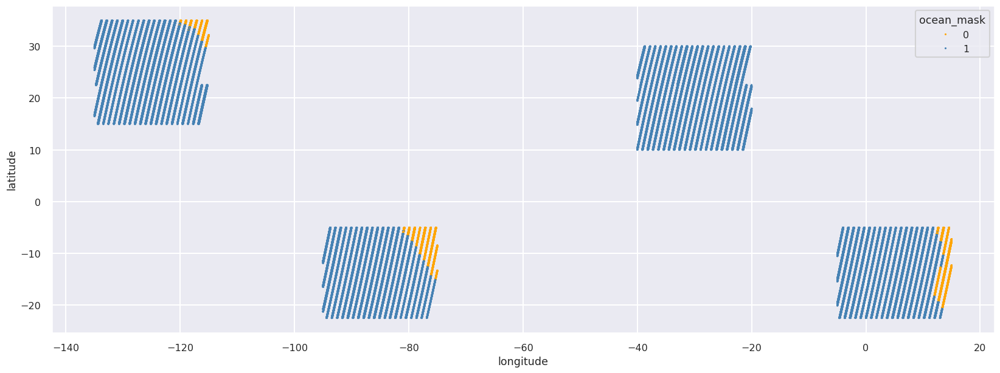

In [ ]:
sns.set_theme('talk', font_scale=0.7)
plt.figure(figsize=(20,7))
sns.scatterplot(data=df, x='longitude', y='latitude', hue=df['ocean_mask'].fillna(2).astype(int), lw=0, s=5, palette=['orange', 'steelblue', 'red'])

In [ ]:
df[['latitude','longitude','time','ocean_mask']].to_csv('/home/jmayer/ACI_research/Code/resources/ocean_mask_with_judge.csv', index=False)

## Save the combined dataset

In [36]:
df.to_hdf('/home/jmayer/ACI_research/Code/resources/ACMCAP_XMET_judge_StCu_Jun-Aug.h5', key='StCu', mode='w')

In [266]:
df

,Unnamed: 0.1,time,N_high_cc,Unnamed: 0,along_track,latitude,longitude,daytime,lwp,ER,...,ice_flag_1,scene_id_0,scene_id_1,MCOP_cloud_cover_judge_0,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1,ocean_mask
1414,1414,2025-05-01 13:59:41.424672128,10,1414,2980,-5.000860,-1.220043,True,0.001366,0.000001,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1415,1415,2025-05-01 13:59:41.561167744,11,1415,2981,-5.009697,-1.221703,True,0.001494,0.000001,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1416,1416,2025-05-01 13:59:41.697661696,11,1416,2982,-5.018534,-1.223362,True,0.005736,0.000004,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1417,1417,2025-05-01 13:59:41.834155776,11,1417,2983,-5.027372,-1.225021,True,0.009257,0.000013,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1418,1418,2025-05-01 13:59:42.015209856,11,1418,2984,-5.039095,-1.227221,True,0.010426,0.000018,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1013340,1013340,2025-07-31 23:09:46.311145728,0,1013340,4638,25.419477,-134.991371,True,0.000000,NaN,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1013341,1013341,2025-07-31 23:09:46.446427520,0,1013341,4639,25.410741,-134.993248,True,0.000000,NaN,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1013342,1013342,2025-07-31 23:09:46.581705600,0,1013342,4640,25.402005,-134.995125,True,0.000000,NaN,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1013343,1013343,2025-07-31 23:09:46.716985856,0,1013343,4641,25.393270,-134.997002,True,0.000000,NaN,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True


# Read in combined dataset

In [5]:
dataset_filename = '/home/jmayer/ACI_research/Code/resources/ACMCAP_XMET_judge_StCu_Jun-Aug.h5'
df = pd.read_hdf(dataset_filename, key='StCu')

In [6]:
df.time.min(), df.time.max()

(Timestamp('2025-06-01 13:26:02.599795968'),
 Timestamp('2025-08-31 22:38:59.645495808'))

In [7]:
# filter to only July and August 2025 (BA period)
BA_start = pd.to_datetime('2025-07-09')
df = df[pd.to_datetime(df.time) >= BA_start]

## Sanity checks

In [210]:
np.any(df[(df.cert_0 > 0.75)].lwp == 0)

np.True_

In [211]:
np.any(df[(df.cats_0 == 6)].lwp == 0)

np.True_

<Axes: ylabel='Frequency'>

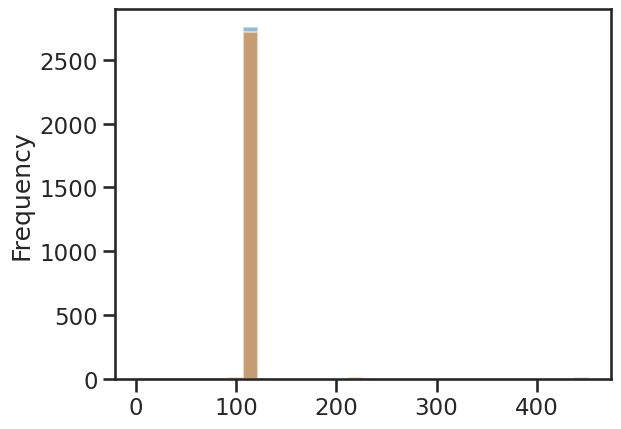

In [212]:
scene_sizes_ACMCAP = df[df.scene_id_0 != -1].groupby('scene_id_0').size()
scene_sizes_ACMCAP.plot.hist(bins=30, alpha=0.5)

scene_sizes_ACMCAP = df[df.scene_id_1 != -1].groupby('scene_id_1').size()
scene_sizes_ACMCAP.plot.hist(bins=30, alpha=0.5)

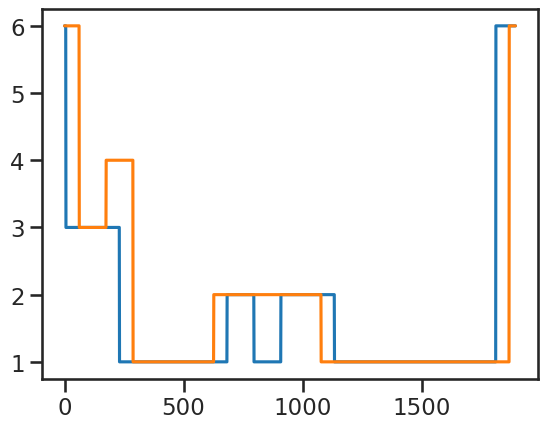

In [213]:
dfex = df[df.orbit == '06486E']
dfex = dfex.reset_index()
dfex.cats_0.plot()
dfex.cats_1.plot()
plt.show()

# Filters

## in case ocean_mask is not in dataset

In [18]:
# add ocean mask
ocean_mask = pd.read_csv('/home/jmayer/ACI_research/Code/resources/ocean_mask_with_judge.csv')
#df = pd.merge(df, ocean_mask, on=['latitude', 'longitude'], how='left')

In [19]:
df['lat_coarse'] = df['latitude'].round()
df['lon_coarse'] = df['longitude'].round()

In [20]:
ocean_mask['lat_coarse'] = ocean_mask['latitude'].round()
ocean_mask['lon_coarse'] = ocean_mask['longitude'].round()
ocean_mask = ocean_mask[['lat_coarse', 'lon_coarse', 'ocean_mask']].drop_duplicates()

In [21]:
ocean_mask

,lat_coarse,lon_coarse,ocean_mask
0,-5.0,-1.0,True
54,-6.0,-1.0,True
162,-6.0,-2.0,True
163,-7.0,-2.0,True
271,-8.0,-2.0,True
...,...,...,...
315434,29.0,-134.0,True
315632,28.0,-135.0,True
315651,27.0,-135.0,True
315759,26.0,-135.0,True


In [22]:
df = pd.merge(df, ocean_mask[['lat_coarse', 'lon_coarse', 'ocean_mask']], on=['lat_coarse', 'lon_coarse'], how='left')

In [23]:
df

,Unnamed: 0.1,time,N_high_cc,Unnamed: 0,along_track,latitude,longitude,daytime,lwp,ER,...,cats,cert,ice_flag,scene_id,MCOP_cloud_cover_judge,MCOP_cwp_skew_judge,MCOP_cwp_inhomogeneity_judge,lat_coarse,lon_coarse,ocean_mask
0,1414,2025-05-01 13:59:41.424672128,10,1414,2980,-5.000860,-1.220043,True,0.001366,0.000001,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,-5.0,-1.0,True
1,1415,2025-05-01 13:59:41.561167744,11,1415,2981,-5.009697,-1.221703,True,0.001494,0.000001,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,-5.0,-1.0,True
2,1416,2025-05-01 13:59:41.697661696,11,1416,2982,-5.018534,-1.223362,True,0.005736,0.000004,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,-5.0,-1.0,True
3,1417,2025-05-01 13:59:41.834155776,11,1417,2983,-5.027372,-1.225021,True,0.009257,0.000013,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,-5.0,-1.0,True
4,1418,2025-05-01 13:59:42.015209856,11,1418,2984,-5.039095,-1.227221,True,0.010426,0.000018,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,-5.0,-1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307920,669724,2025-07-16 16:04:56.185195776,5,669724,4950,22.544381,-29.177438,True,0.000000,NaN,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,23.0,-29.0,True
307921,669725,2025-07-16 16:04:56.373892608,5,669725,4951,22.532187,-29.179974,True,0.000114,0.000001,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,23.0,-29.0,True
307922,669726,2025-07-16 16:04:56.509112832,5,669726,4952,22.523450,-29.181792,True,0.000175,0.000001,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,23.0,-29.0,True
307923,669727,2025-07-16 16:04:56.644332800,5,669727,4953,22.514711,-29.183608,True,0.001221,0.000003,...,6,-1.0,-1.0,-1,-1.0,-1.0,-1.0,23.0,-29.0,True


<Axes: xlabel='longitude', ylabel='latitude'>

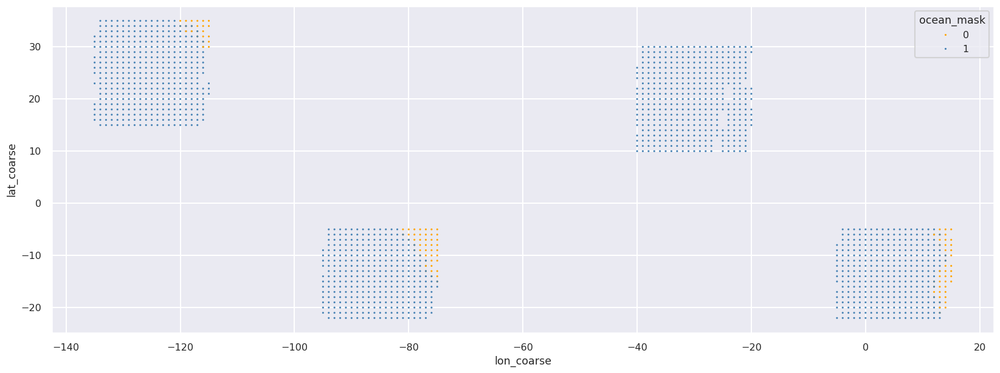

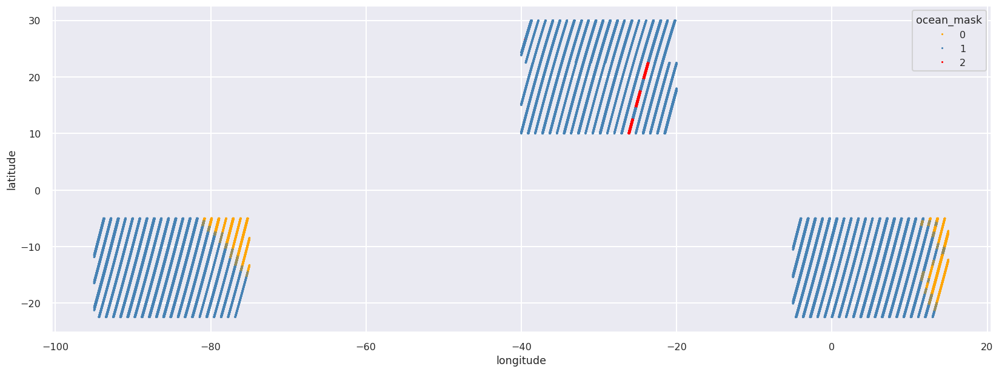

In [24]:
sns.set_theme('talk', font_scale=0.7)
plt.figure(figsize=(20,7))
sns.scatterplot(data=ocean_mask, x='lon_coarse', y='lat_coarse', hue=ocean_mask['ocean_mask'].fillna(2).astype(int), lw=0, s=5, palette=['orange', 'steelblue', 'red'])
plt.figure(figsize=(20,7))
sns.scatterplot(data=df, x='longitude', y='latitude', hue=df['ocean_mask'].fillna(2).astype(int), lw=0, s=5, palette=['orange', 'steelblue', 'red'])

## Filter dataset

<Axes: ylabel='Frequency'>

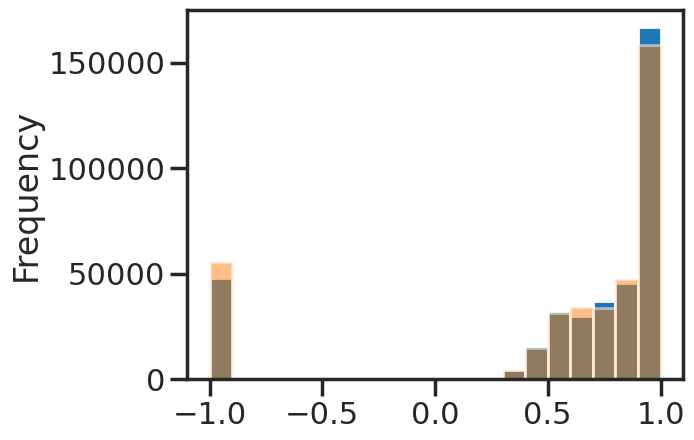

In [8]:
df.cert_0.plot.hist(bins=20)
df.cert_1.plot.hist(bins=20, alpha=0.5)

<Axes: ylabel='Frequency'>

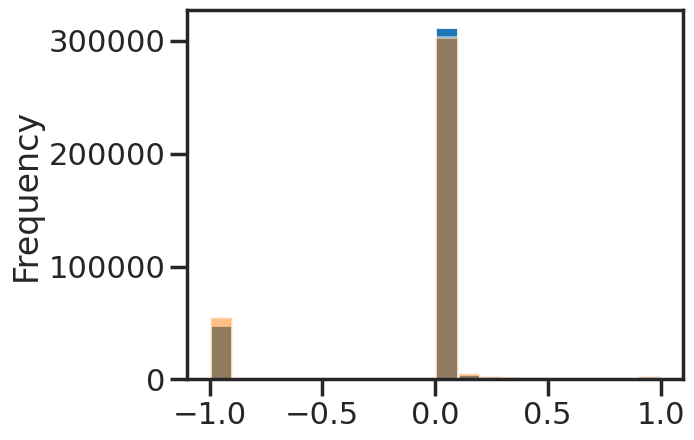

In [9]:
df['ice_flag_0'].astype(float).plot.hist(bins=20)
df['ice_flag_1'].astype(float).plot.hist(bins=20, alpha=0.5)

In [10]:
df

,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,lwp_error,...,ice_flag_0,ice_flag_1,scene_id_0,scene_id_1,MCOP_cloud_cover_judge_0,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1
80379,2983,2025-07-09 12:59:33.204668288,-5.005631,13.653607,0,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
80380,2984,2025-07-09 12:59:33.340387840,-5.014420,13.651957,0,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
80381,2985,2025-07-09 12:59:33.476107648,-5.023208,13.650307,0,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
80382,2986,2025-07-09 12:59:33.611828096,-5.031996,13.648657,0,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
80383,2987,2025-07-09 12:59:33.747547648,-5.040784,13.647007,0,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1122455,815,2025-08-31 22:38:59.105735936,15.043125,-128.786007,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1122456,816,2025-08-31 22:38:59.240677504,15.034392,-128.787718,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1122457,817,2025-08-31 22:38:59.375615872,15.025658,-128.789429,3,0.009169,0.000013,0.000013,2855815.25,0.088560,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1122458,818,2025-08-31 22:38:59.510556032,15.016924,-128.791140,3,0.027764,0.000012,0.000012,8873747.00,0.370534,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0


In [11]:
# we always filter out ocean pixels
df = df[(df.ocean_mask == 1)]

In [12]:
df.columns

Index(['along_track', 'time', 'latitude', 'longitude', 'stratus_region_index',
       'lwp', 'ER', 'ER_passive_perspective', 'Nd', 'lwp_error', 'Nd_error',
       'liquid_classification_mean', 'liquid_optical_depth', 'cth', 'cbh',
       'cth_m', 'cbh_m', 'cth_all_clouds', 'multilayer', 'N_cloudy_pixels',
       'N_high_cc', 'rain_rate_surface', 'rain_rate_cbh', 'rain_rate_max',
       'rain_rate_subcloud', 'doppler_velocity_mean', 'cbh_min_max_128km',
       'cbh_minus_lcl', 'CPR_path_integrated_attenuation', 'MSI_BT_108',
       'boundary_layer_height', 'lcl', 'sea_surface_temperature',
       'total_column_water_vapour', 'lower_tropospheric_stability',
       'inversion_strength', 'relative_humidity_below_bl',
       'relative_humidity_above_bl', 'relative_humidity_below_cth',
       'relative_humidity_above_cth', 'relative_humidity_at_3km',
       'upward_air_velocity_at_3km', 'MCOP_effective_radius',
       'MCOP_optical_thickness', 'MCOP_cloud_water_path', 'MCOP_cwp_skew_256',
  

In [35]:
dffil = df.copy()

variables = ['time', 'N_high_cc', 'along_track',
       'latitude', 'longitude', 'daytime', 'lwp', 'ER', 'Nd', 'lwp_error',
       'Nd_error', 'liquid_classification_mean', 'liquid_optical_depth', 'cth',
       'cbh', 'cth_m', 'cbh_m', 'cth_all_clouds', 'multilayer',
       'N_cloudy_pixels', 'rain_rate_surface', 'rain_rate_cbh',
       'rain_rate_max', 'rain_rate_subcloud', 'doppler_velocity_mean', 'cbh_minus_lcl', 'coupled_fraction',
       'boundary_layer_height', 'sea_surface_temperature', 'lower_tropospheric_stability',
       'inversion_strength', 
       'MCOP_cwp_skew_200', 'MCOP_cwp_inhomogeneity_200', 'MCOP_cloud_cover_200',
       'orbit', 'stratus_region_index', 'ocean_mask',
       'lwc_profile', 'rain_rate_profile', 'rain_rate_below_cloud_profile'
       ]

variables = ['time', 'N_high_cc', 'along_track',
       'latitude', 'longitude', 'daytime', 'lwp', 'ER', 'Nd', 'lwp_error',
       'Nd_error', 'liquid_classification_mean', 'liquid_optical_depth', 'cth',
       'cbh', 'cth_m', 'cbh_m', 'cth_all_clouds', 'multilayer',
       'N_cloudy_pixels', 'rain_rate_surface', 'rain_rate_cbh',
       'rain_rate_max', 'rain_rate_subcloud', 'rwp', 'rwp_subcloud',
       'doppler_velocity_mean', 'cbh_minus_lcl', 'lcl',
       'boundary_layer_height', 'sea_surface_temperature', 'lower_tropospheric_stability',
       'inversion_strength', 
       'MCOP_cloud_water_path', 'MCOP_effective_radius',
       'MCOP_cwp_skew_256', 'MCOP_cwp_inhomogeneity_256', 'MCOP_cloud_cover_256',
       'orbit', 'stratus_region_index', 'ocean_mask',
       'lwc_profile', 'rain_rate_profile', 'rain_rate_below_cloud_profile'
       ]
# filters:
# 1) matching judge scene exists; 2) ice-free; 3) high confidence; 4) at least 10% cloud cover in MCOP
dffil_0 = dffil[
    (dffil.scene_id_0 != -1) &
    (dffil.ice_flag_0 == 0) &
    (dffil.cert_0 > 0.75) & 
    (dffil.MCOP_cloud_cover_judge_0 >= 0.1)
              ][variables + ['cats_0', 'cert_0', 'ice_flag_0', 'scene_id_0',
                            'MCOP_cloud_cover_judge_0', 'MCOP_cwp_skew_judge_0',
                            'MCOP_cwp_inhomogeneity_judge_0']]

dffil_1 = dffil[
    (dffil.scene_id_1 != -1) &
    (dffil.ice_flag_1 == 0) &
    (dffil.cert_1 > 0.75) & 
    (dffil.MCOP_cloud_cover_judge_1 >= 0.1)
              ][variables + ['cats_1', 'cert_1', 'ice_flag_1', 'scene_id_1',
                            'MCOP_cloud_cover_judge_1', 'MCOP_cwp_skew_judge_1',
                            'MCOP_cwp_inhomogeneity_judge_1']]

In [36]:
dffil_0.rename(columns={col: col.replace('_0','') for col in dffil_0.columns if col.endswith('_0') and col != 'scene_id_0'}, inplace=True)
dffil_1.rename(columns={col: col.replace('_1','') for col in dffil_1.columns if col.endswith('_1') and col != 'scene_id_1'}, inplace=True)

In [37]:
dffil = pd.concat([dffil_0, dffil_1], axis=0, ignore_index=True)
dffil['scene_id'] = np.where(~np.isnan(dffil.scene_id_0), dffil.scene_id_0, dffil.scene_id_1 + dffil.scene_id_0.max() + dffil.scene_id_1.min())

In [38]:
dffil.scene_id.unique()

array([  735.,   741.,   743., ..., 17935., 17937., 17939.], shape=(3009,))

In [39]:
(((dffil.scene_id_0 != -1)).sum()/len(df), 
 ((dffil.ice_flag == 0)).sum()/len(df), 
 ((dffil.cert > 0.75)).sum()/len(df), 
 ((dffil.MCOP_cloud_cover_judge >= 0.1)).sum()/len(df), 
 len(dffil)/len(df))

(np.float64(0.952973905302398),
 np.float64(0.952973905302398),
 np.float64(0.952973905302398),
 np.float64(0.952973905302398),
 0.952973905302398)

In [40]:
df

,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,lwp_error,...,ice_flag_0,ice_flag_1,scene_id_0,scene_id_1,MCOP_cloud_cover_judge_0,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1
80686,3290,2025-07-09 13:00:17.021079552,-7.842092,13.118979,0,0.000000,NaN,NaN,NaN,NaN,...,0.0,0.049255,729,730,0.021606,0.227295,1.771858,1.391784,0.479826,0.603339
80687,3291,2025-07-09 13:00:17.205575424,-7.854033,13.116721,0,0.000000,NaN,NaN,NaN,NaN,...,0.0,0.049255,729,730,0.021606,0.227295,1.771858,1.391784,0.479826,0.603339
80688,3292,2025-07-09 13:00:17.341497472,-7.862829,13.115057,0,0.000000,NaN,NaN,NaN,NaN,...,0.0,0.049255,729,730,0.021606,0.227295,1.771858,1.391784,0.479826,0.603339
80689,3293,2025-07-09 13:00:17.477415552,-7.871626,13.113392,0,0.000000,NaN,NaN,NaN,NaN,...,0.0,0.049255,729,730,0.021606,0.227295,1.771858,1.391784,0.479826,0.603339
80690,3294,2025-07-09 13:00:17.613335424,-7.880422,13.111728,0,0.000000,NaN,NaN,NaN,NaN,...,0.0,0.049255,729,730,0.021606,0.227295,1.771858,1.391784,0.479826,0.603339
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1122455,815,2025-08-31 22:38:59.105735936,15.043125,-128.786007,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.000000,-1,-1,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
1122456,816,2025-08-31 22:38:59.240677504,15.034392,-128.787718,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1.000000,-1,-1,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
1122457,817,2025-08-31 22:38:59.375615872,15.025658,-128.789429,3,0.009169,0.000013,0.000013,2855815.25,0.088560,...,-1.0,-1.000000,-1,-1,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
1122458,818,2025-08-31 22:38:59.510556032,15.016924,-128.791140,3,0.027764,0.000012,0.000012,8873747.00,0.370534,...,-1.0,-1.000000,-1,-1,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000


In [41]:
dffil

,time,N_high_cc,along_track,latitude,longitude,daytime,lwp,ER,Nd,lwp_error,...,rain_rate_below_cloud_profile,cats,cert,ice_flag,scene_id_0,MCOP_cloud_cover_judge,MCOP_cwp_skew_judge,MCOP_cwp_inhomogeneity_judge,scene_id_1,scene_id
0,2025-07-09 13:00:54.614719488,0.0,3553,-10.274859,12.656867,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.960887,0.0,735.0,0.122498,0.741714,0.513768,NaN,735.0
1,2025-07-09 13:00:54.750839680,0.0,3554,-10.283666,12.655185,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.960887,0.0,735.0,0.122498,0.741714,0.513768,NaN,735.0
2,2025-07-09 13:00:54.886959488,0.0,3555,-10.292473,12.653504,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.960887,0.0,735.0,0.122498,0.741714,0.513768,NaN,735.0
3,2025-07-09 13:00:55.023079424,0.0,3556,-10.301280,12.651823,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.960887,0.0,735.0,0.122498,0.741714,0.513768,NaN,735.0
4,2025-07-09 13:00:55.206377728,0.0,3557,-10.313138,12.649559,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.960887,0.0,735.0,0.122498,0.741714,0.513768,NaN,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342551,2025-08-31 22:37:44.239626752,1.0,291,19.886969,-127.821561,1,0.000010,8.233781e-07,65955332.0,1.542368,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.997707,0.0,NaN,0.370422,7.760601,1.172843,8602.0,17939.0
342552,2025-08-31 22:37:44.374648320,2.0,292,19.878238,-127.823336,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.997707,0.0,NaN,0.370422,7.760601,1.172843,8602.0,17939.0
342553,2025-08-31 22:37:44.509668096,2.0,293,19.869507,-127.825111,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.997707,0.0,NaN,0.370422,7.760601,1.172843,8602.0,17939.0
342554,2025-08-31 22:37:44.644688256,2.0,294,19.860776,-127.826886,1,0.000021,7.931145e-07,73797248.0,1.031383,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.997707,0.0,NaN,0.370422,7.760601,1.172843,8602.0,17939.0


In [42]:
(dffil.lwp == 0).sum()

np.int64(96212)

# Analysis

In [43]:
sns.set_context("talk", font_scale=1)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

In [44]:
# get 6 distinct colors from the viridis colormap
cmap = matplotlib.cm.get_cmap('viridis', 6)
catcolors = [cmap(i) for i in range(cmap.N)]

#colors = ['#1f77b4', '#2ca02c', '#ff7f0e',  '#d62728', '#e377c2', '#8c564b', 'black']

line_styles = [(0, (3, 1, 1, 1)), '-', '--', '-.', (0,(3,1,1,1,1,1)), ':']

In [45]:
cats_names = {
    0: 'Solid Stratus',
    1: 'Closed MCC',
    2: 'Open MCC',
    3: 'Disorg. MCC',
    4: 'Clustered Cu',
    5: 'Suppr. Cu'
    }

palette_catscolors = {i: catcolors[i] for i in range(6)}
palette_catscolors[6] = 'lightgray'  # for unclassified

In [46]:
from matplotlib.lines import Line2D

# Custom legend with line styles
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in range(6)
]

In [47]:
def histplot_with_style(cluster_id, ax, data, x, bins, **kwargs):
    sns.histplot(
        ax=ax, data=data[data['cats'] == cluster_id], x=x, bins=bins,
        element='step', stat='probability', fill=True, alpha=0.2, lw=0, kde=True,
        color=catcolors[cluster_id], line_kws={'ls':line_styles[cluster_id], 'lw':3},
        **kwargs
    )

## Number of samples

In [231]:
dffil.scene_id.unique()

array([  735.,   741.,   743., ..., 17935., 17937., 17939.], shape=(3009,))

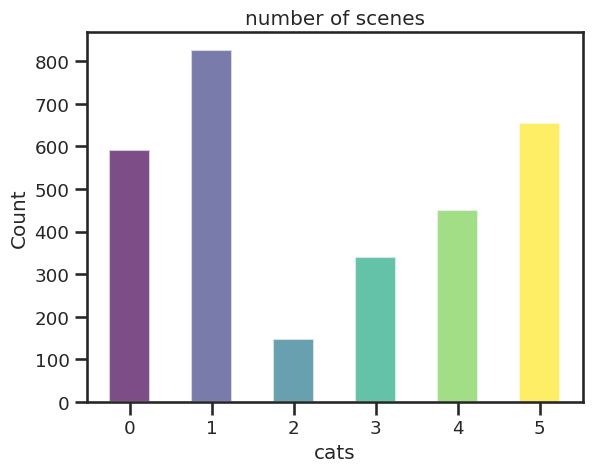

In [232]:
import matplotlib.pyplot as plt

cats = dffil.groupby('scene_id')['cats'].mean()
bins = np.arange(-0.25, 5.75, 0.5)
counts, edges = np.histogram(cats, bins=bins)
plt.figure()
for i in range(len(counts)):
    plt.bar(edges[i]+0.25, counts[i], width=0.5, color=catcolors[i//2], alpha=0.7)
plt.xlabel('cats')
plt.ylabel('Count')
plt.title('number of scenes')
plt.show()

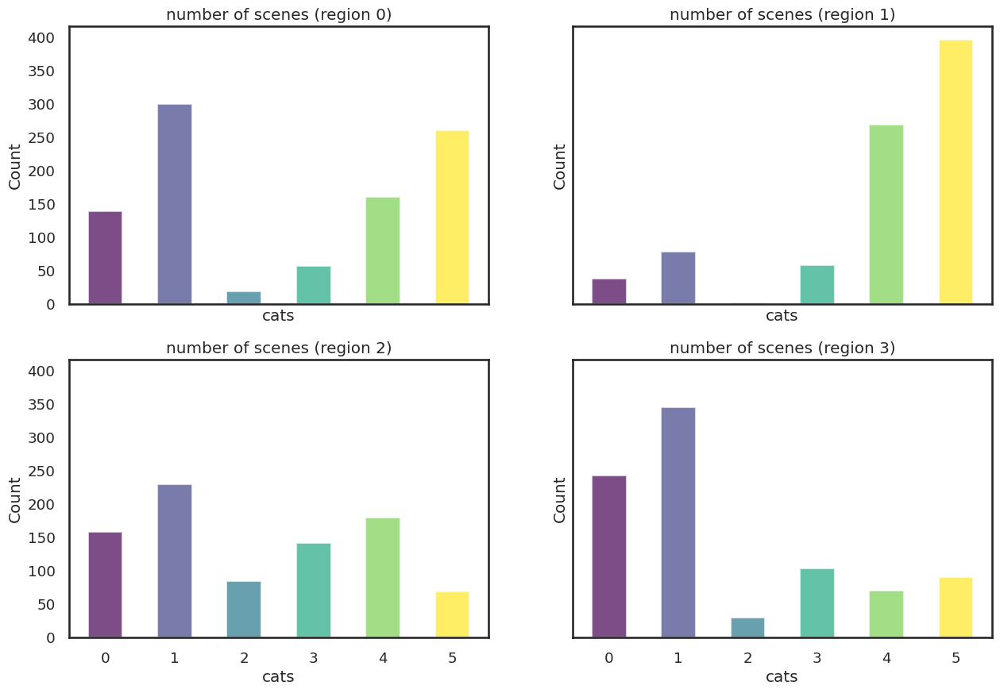

In [312]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(ncols=2, nrows=2, figsize=(15,10), sharey=True, sharex=True)
for i, (region, ax) in enumerate(zip(stratus_regions.keys(), axs.flatten())):
    reg = i  # 0: SEA, 1: NEA, 2: SEP, 3: NEP
    dffil_reg = dffil[dffil.stratus_region_index == reg]
    cats = dffil_reg.groupby('scene_id')['cats'].mean()

    bins = np.arange(-0.25, 5.75, 0.5)
    counts, edges = np.histogram(cats, bins=bins)
    for i in range(len(counts)):
        ax.bar(edges[i]+0.25, counts[i], width=0.5, color=catcolors[i//2], alpha=0.7)
    ax.set_xlabel('cats')
    ax.set_ylabel('Count')
    ax.set_title(f'number of scenes (region {reg})')
plt.show()

## geographic distribution

In [60]:
from matplotlib import colors
from mpl_toolkits.basemap import Basemap

In [61]:
def bmap(ax=None, drawlines=True, llr=None, par_labs=[1, 0, 0, 0], mer_labs=[0, 0, 0, 1], 
         merspace=5, parspace=5, **kwargs):

    if ax is None:
        fig, ax = plt.subplots()

    lat_range = llr['lat']
    lon_range = llr['lon']
    
    if 'projection' not in kwargs.keys():
        kwargs['projection'] = 'cyl'
        kwargs['rsphere'] =(6378137.00, 6356752.3142)
    m = Basemap(llcrnrlon=lon_range[0], llcrnrlat=lat_range[0],
                urcrnrlon=lon_range[1],  urcrnrlat=lat_range[1],
                ax=ax, resolution='l', **kwargs)
    if drawlines:
        m.drawparallels(np.arange(-90., 90., parspace), labels=par_labs, fontsize=14)
        m.drawmeridians(np.arange(-180., 180., merspace), labels=mer_labs, fontsize=14)
    m.drawcoastlines()
    m.fillcontinents(color="white", lake_color="white")

    return m

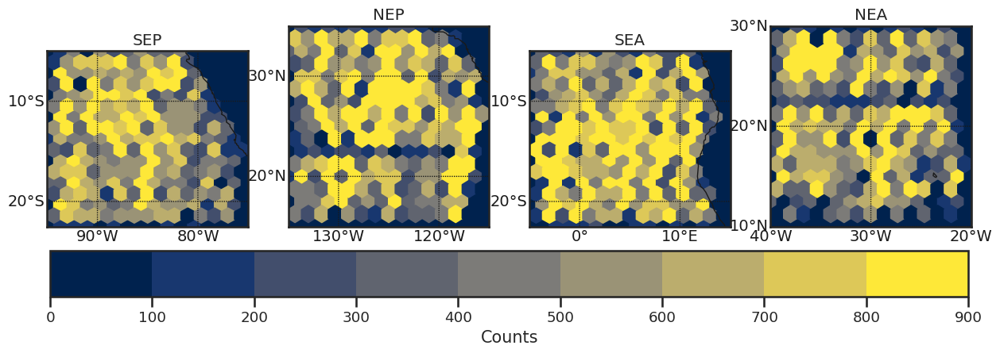

In [62]:
ticks = np.linspace(0, 1000, 11)[:-1]
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)
lnorm = colors.LogNorm(vmin=0.01, vmax=0.7)

fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(15, 5))
axn = axs.flatten()
for i, ax in enumerate(axn):
    stratus_region_order = [2, 3, 0, 1]
    sr = stratus_region_order[i]
    plot_df = dffil[(dffil.stratus_region_index == sr)]
    stratus_region_names = {0:'SEA', 1:'NEA', 2:'SEP', 3:'NEP'}
    llr = stratus_regions[stratus_region_names[sr]]

    b = bmap(ax=ax, llr=llr, merspace=10, parspace=10)
    image = b.hexbin(plot_df['longitude'], plot_df['latitude'], gridsize=15, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
    image.cmap.set_under('lightgrey')
    ax.set_title(stratus_region_names[sr])

plt.subplots_adjust(hspace=0.2, wspace=0.2)
cb = plt.colorbar(image, ax=axn, orientation='horizontal', pad=0.08)
cb.set_label("Counts", fontsize=15)

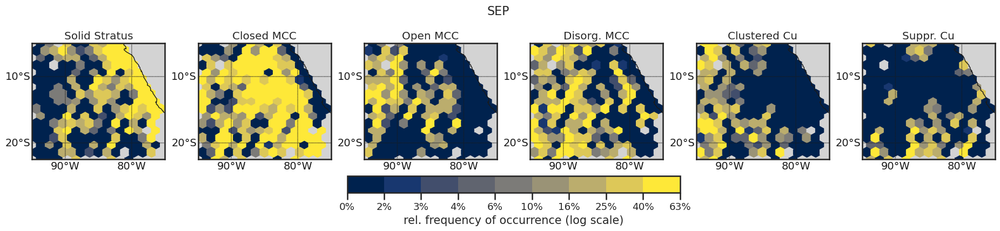

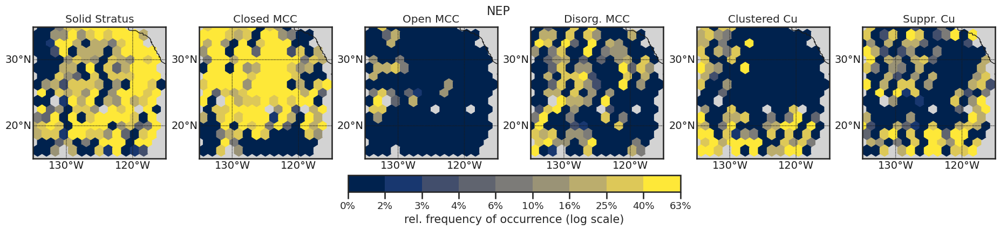

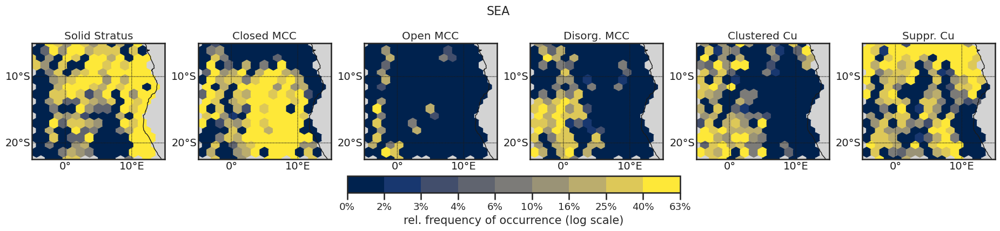

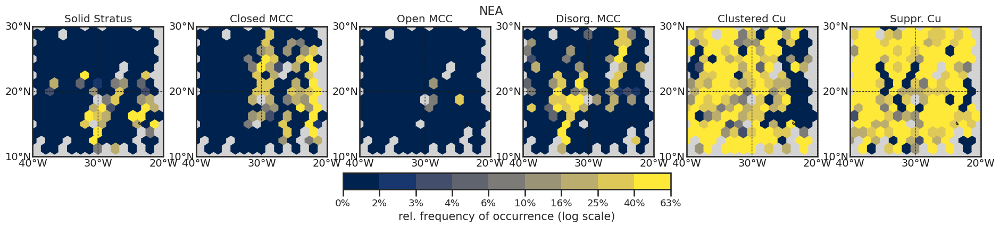

In [63]:
#ticks = np.linspace(0, 1, 11)[:-1]
#bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)
#lnorm = colors.LogNorm(vmin=0.01, vmax=0.7)
ticks = np.logspace(-2, 0, 11)[:-1]
ticks[0]=0
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)

for j in range(4):
    stratus_region_order = [2, 3, 0, 1]
    sr = stratus_region_order[j]
    stratus_region_names = {0:'SEA', 1:'NEA', 2:'SEP', 3:'NEP'}
    llr = stratus_regions[stratus_region_names[sr]]

    gridsize = 15
    fig, ax = plt.subplots()
    b = bmap(ax=ax, llr=llr)
    plot_df = dffil[(dffil.stratus_region_index == sr)]
    image = b.hexbin(plot_df['longitude'], plot_df['latitude'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
    all_counts = image.get_array()+1
    plt.close()

    fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(23, 4), sharex=True, sharey=True)
    plt.suptitle(f'{stratus_region_names[sr]}', fontsize=16)
    axn = axs.flatten()
    for i, ax in enumerate(axn):
        plot_df = dffil[(dffil.stratus_region_index == sr) & (dffil['cats'] == i)]

        b = bmap(ax=ax, llr=llr, merspace=10, parspace=10)
        image = b.hexbin(plot_df['longitude'], plot_df['latitude'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
        normed_counts = image.get_array()/all_counts
        normed_counts[all_counts<100] = -1
        
        image.set_array(normed_counts)
        image.cmap.set_under('lightgrey')
        ax.set_title(cats_names[i])

    plt.subplots_adjust(hspace=0.5, wspace=0.25)
    cb = plt.colorbar(image, ax=axn, ticks=ticks, orientation='horizontal', pad=0.1, fraction=0.1)
    cb.set_ticklabels([f"{i:0.0%}" for i in ticks])
    cb.set_label("rel. frequency of occurrence (log scale)", fontsize=15)
    plt.show()

## mesoscale structure

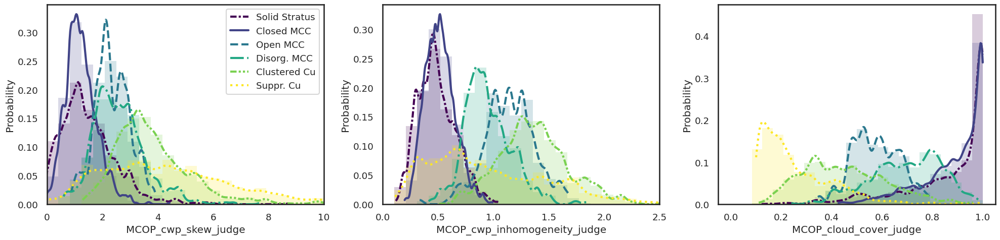

In [64]:
cloud_regime = 'cats'
# check how the clusters relate to the M-COP variables
fig, ax = plt.subplots(1,3, figsize=(20, 5))
for i in [0,1,2,3,4,5]: #6

    histplot_with_style(i, ax[0], dffil, 'MCOP_cwp_skew_judge', np.linspace(0,10,25))
    histplot_with_style(i, ax[1], dffil, 'MCOP_cwp_inhomogeneity_judge', np.linspace(0,2.5,25))
    histplot_with_style(i, ax[2], dffil, 'MCOP_cloud_cover_judge', np.linspace(0,1,25))

ax[0].legend(handles=legend_elements)
ax[0].set_xlim(0,10)
ax[1].set_xlim(0,2.5)
fig.tight_layout()

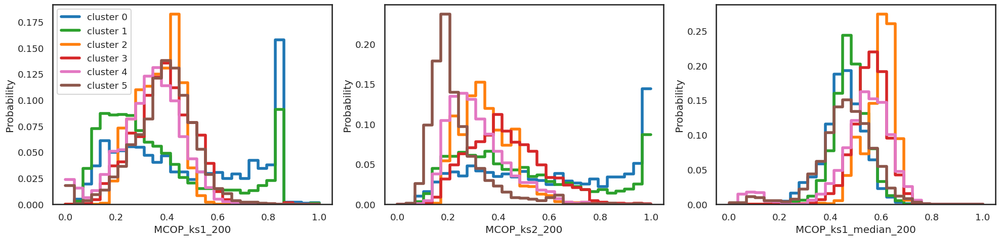

In [151]:
cloud_regime = 'cats'
# check how the clusters relate to the M-COP variables
fig, ax = plt.subplots(1,3, figsize=(20, 5))
for i in [0,1,2,3,4,5]: #6
    sns.histplot(ax=ax[0], data=dffil[dffil[cloud_regime] == i], x='MCOP_ks1_200', 
                 bins=np.linspace(0,1,30), element='step', stat='probability',  fill=False, label=f'cluster {i}', color=colors[i], lw=4)
    sns.histplot(ax=ax[1], data=dffil[dffil[cloud_regime] == i], x='MCOP_ks2_200', bins=np.linspace(0,1,30), element='step', stat='probability', fill=False, label=f'cluster {i}', color=colors[i], lw=4)
    sns.histplot(ax=ax[2], data=dffil[dffil[cloud_regime] == i], x='MCOP_ks1_median_200', 
                 bins=np.linspace(0,1,30), element='step', stat='probability', fill=False, label=f'cluster {i}', color=colors[i], lw=4)
    ax[0].legend()
fig.tight_layout()

### how do clusters relate to Meteo?

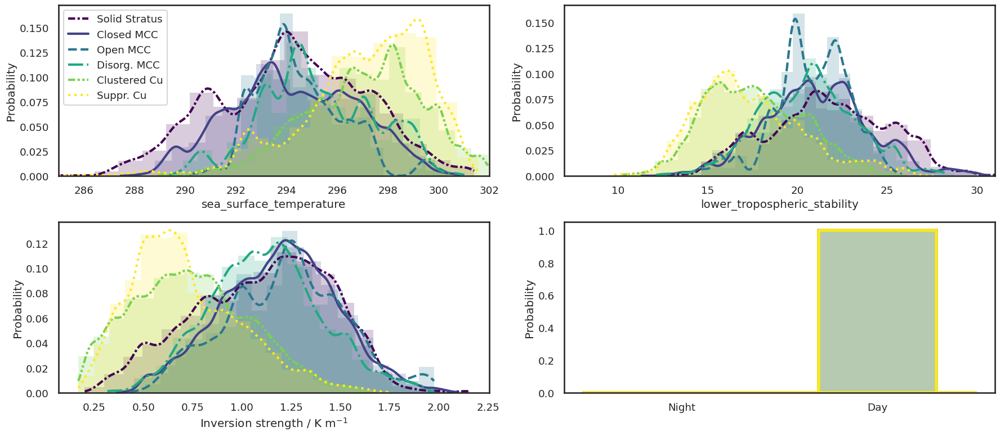

In [318]:
# check how the clusters relate to the M-COP variables
fig, ax = plt.subplots(2,2, figsize=(18, 8))
for i in [0,1,2,3,4,5]: #6
    histplot_with_style(i, ax[0,0], dffil, 'sea_surface_temperature', 20)
    histplot_with_style(i, ax[0,1], dffil, 'lower_tropospheric_stability', np.linspace(5,30,40))
    histplot_with_style(i, ax[1,0], dffil, 'inversion_strength', 20)
    
    night_weight = (dffil.daytime==1).sum()/(dffil.daytime==0).sum()
    dffil['daynight_weight'] = np.where(dffil['daytime'], 1, night_weight)
    sns.histplot(ax=ax[1,1], data=dffil[dffil[cloud_regime] == i], x='daytime', weights='daynight_weight', bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], 
                 element='step', alpha=0.1, stat='probability', label=f'cluster {i}', color=catcolors[i], lw=4)
    
ax[0,0].legend(handles=legend_elements)
ax[1,0].set_xlabel('Inversion strength / K m$^{-1}$')
ax[1,1].set_xticks([0,1])
ax[1,1].set_xticklabels(['Night', 'Day'])
ax[1,1].set_xlabel('')

ax[0,0].set_xlim(285,302)
ax[0,1].set_xlim(7,31)
fig.tight_layout()

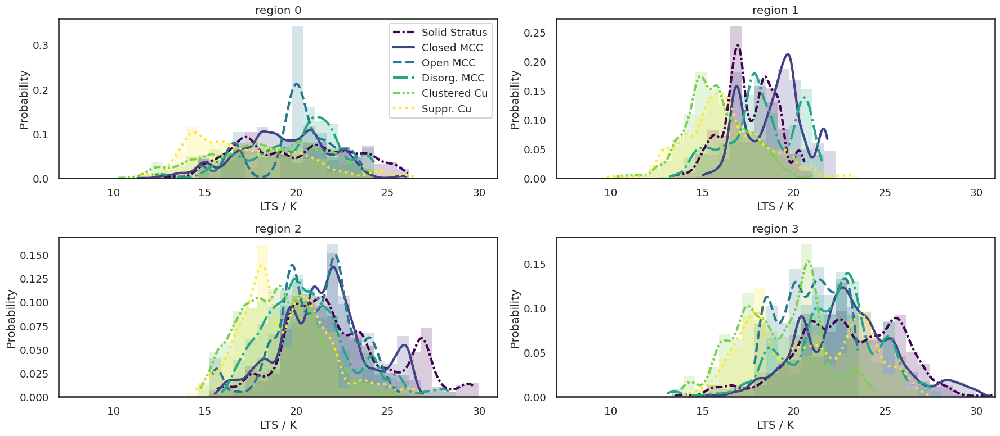

In [319]:
# check how the clusters relate to the M-COP variables
fig, axs = plt.subplots(2,2, figsize=(18, 8))
for reg in [0,1,2,3]:
    ax = axs.flatten()[reg]
    ax.set_title(f'region {reg}')
    for i in [0,1,2,3,4,5]:
        if len(dffil[(dffil.stratus_region_index == reg) & (dffil['cats'] == i)]) < 300:
            continue
        histplot_with_style(i, ax, dffil[dffil.stratus_region_index == reg], 'lower_tropospheric_stability', np.linspace(5,30,40))

axs[0,0].legend(handles=legend_elements)
for ax in axs.flatten():
    ax.set_xlabel('LTS / K')
    ax.set_xlim(7,31)
fig.tight_layout()

## vertical structure

### histograms

In [233]:
dffil['cloud_mask'] = dffil['N_cloudy_pixels'] > 0
dffil['cloud_fraction'] = dffil.groupby(['orbit', 'scene_id'])['cloud_mask'].transform(lambda x: np.mean(x))

In [234]:
# vertical cloud fraction
dffil['N_mean_113'] = dffil.groupby(['orbit', 'scene_id'])['N_cloudy_pixels'].transform(lambda x: np.nanmean(x))
dffil['N_std_113'] = dffil.groupby(['orbit', 'scene_id'])['N_cloudy_pixels'].transform(lambda x: np.nanstd(x))

In [235]:
dffil['H'] = (np.abs(dffil['cth'] - dffil['cbh']) + 1) * 100 # transform to meters
dffil['daytime'] = dffil['daytime'].astype(int)

dffil['cbh_minus_lcl_113'] = dffil.groupby(['orbit', 'scene_id'])['cbh_minus_lcl'].transform(lambda x: np.nanmean(x))

In [236]:
dffil['cbh_max_113'] = dffil.groupby(['orbit', 'scene_id'])['cbh_m'].transform(lambda x: np.nanmax(x))
dffil['cbh_min_113'] = dffil.groupby(['orbit', 'scene_id'])['cbh_m'].transform(lambda x: np.nanmin(x))
dffil['cbh_max_minus_min_113'] = dffil.groupby(['orbit', 'scene_id'])['cbh_m'].transform(lambda x: np.nanmax(x) - np.nanmin(x))

In [237]:
dffil['coupled'] = np.where(dffil.cloud_mask, dffil['cbh_minus_lcl'] < 250, np.nan)
dffil['coupled_fraction'] = dffil.groupby(['orbit', 'scene_id'])['coupled'].transform(lambda x: np.nanmean(x))

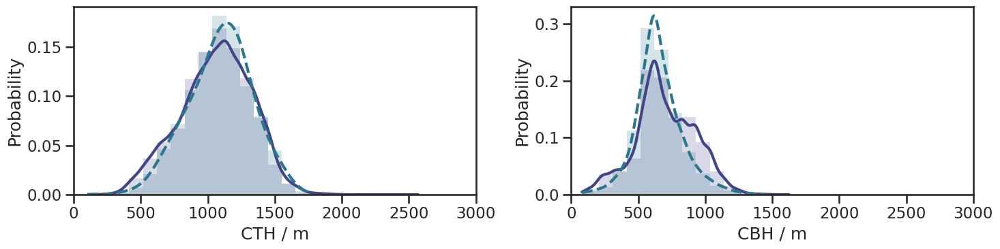

In [247]:
fig, ax = plt.subplots(1,2, figsize=(15, 4))
for i in [1,2]:#[0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'cth_m', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1], dffil, 'cbh_m', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
ax[0].set_xlim(0,3000)
ax[1].set_xlim(0,3000)
ax[0].set_xlabel('CTH / m')
ax[1].set_xlabel('CBH / m')
#ax[0].legend(handles=legend_elements)
fig.tight_layout()

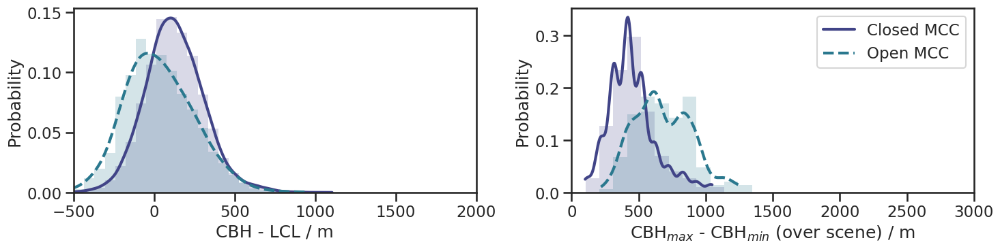

In [249]:
fig, ax = plt.subplots(1,2, figsize=(15, 4))
for i in [1,2]:#[0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'cbh_minus_lcl', np.linspace(-500,2000,40), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1], dffil, 'cbh_max_minus_min_113', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
ax[0].set_xlim(-500,2000)
ax[1].set_xlim(0,3000)
ax[0].set_xlabel('CBH - LCL / m')
ax[1].set_xlabel(r'CBH$_{max}$ - CBH$_{min}$ (over scene) / m')
# Custom legend with line styles
legend_elements_tmp = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in [1,2]
]
ax[1].legend(handles=legend_elements_tmp)
fig.tight_layout()

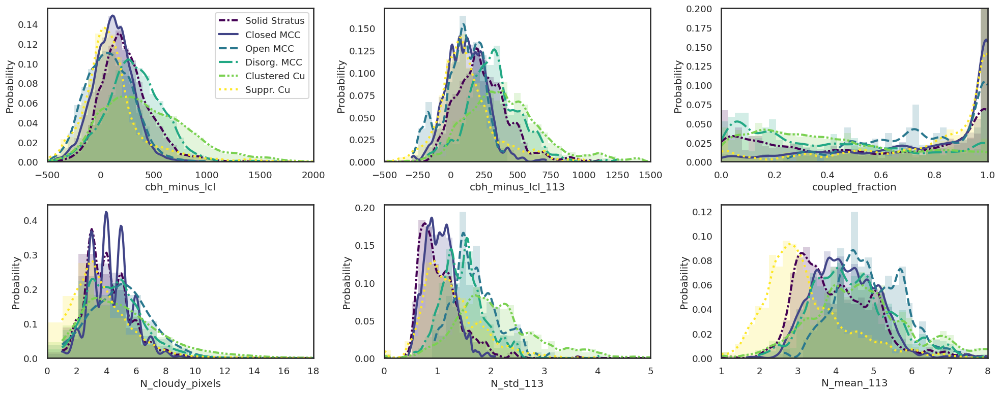

In [326]:
fig, ax = plt.subplots(2,3, figsize=(20, 8))
for i in [0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0,0], dffil, 'cbh_minus_lcl', np.linspace(-500,2000,40))
    histplot_with_style(i, ax[0,1], dffil, 'cbh_minus_lcl_113', np.linspace(-500,1500,40))
    histplot_with_style(i, ax[0,2], dffil, 'coupled_fraction', np.linspace(0,1,40))
    histplot_with_style(i, ax[1,0], dffil, 'N_cloudy_pixels', np.linspace(0,18,18), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1,1], dffil, 'N_std_113', np.linspace(0,5,40))
    histplot_with_style(i, ax[1,2], dffil, 'N_mean_113', np.linspace(1,8,40))

ax[0,0].set_xlim(-500,2000)
ax[0,1].set_xlim(-500,1500)
ax[0,2].set_xlim(0,1)
ax[0,2].set_ylim(0,0.2)
ax[1,0].set_xlim(0,18)
ax[1,1].set_xlim(0,5)
ax[1,2].set_xlim(1,8)
ax[0,0].legend(handles=legend_elements)
fig.tight_layout()

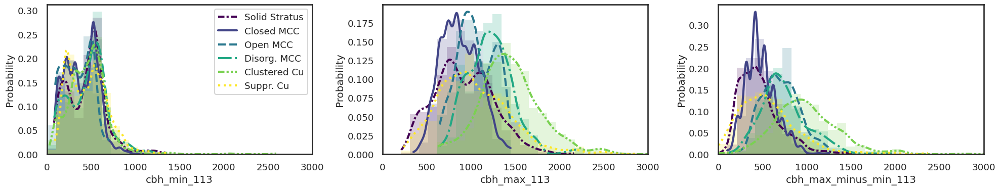

In [334]:
fig, ax = plt.subplots(1,3, figsize=(20, 4))
for i in [0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'cbh_min_113', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1], dffil, 'cbh_max_113', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[2], dffil, 'cbh_max_minus_min_113', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})

ax[0].set_xlim(0,3000)
ax[1].set_xlim(0,3000)
ax[2].set_xlim(0,3000)
ax[0].legend(handles=legend_elements)
fig.tight_layout()

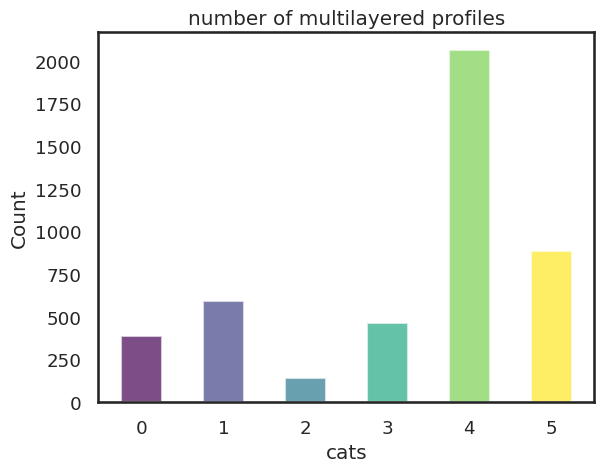

In [342]:
import matplotlib.pyplot as plt

cats = dffil[dffil.multilayer == 1]['cats']
bins = np.arange(-0.25, 5.75, 0.5)
counts, edges = np.histogram(cats, bins=bins)
plt.figure()
for i in range(len(counts)):
    plt.bar(edges[i]+0.25, counts[i], width=0.5, color=catcolors[i//2], alpha=0.7)
plt.xlabel('cats')
plt.ylabel('Count')
plt.title('number of multilayered profiles')
plt.show()

In [99]:
# rain_rate_cbh should be 0 for non-raining clouds and nan for clear sky
dffil['rain_rate_cbh_113'] = dffil.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.nanmean(x))

In [94]:
np.isnan(dffil['rain_rate_cbh']).sum()

np.int64(120467)

In [98]:
np.isnan(dffil[~dffil.cloud_mask]['rain_rate_cbh']).sum()

np.int64(56463)

In [97]:
np.isnan(dffil[dffil.cloud_mask]['rain_rate_cbh']).sum()

np.int64(64004)

In [ ]:
def contourplot(x_var, y_var, df=dffil, kde=False):
    # Plot the contour based on counts
    for i in [0,1,2,3,4,5]:
        plt.figure(figsize=(6, 4))
        cmaps = ['Purples', 'Blues',  'Greens', 'Oranges', 'Reds', 'Yellows']
        # Create a 2D histogram (counts)
        df_tmp = df[df.cats == i][[x_var,y_var]].dropna()
        if df_tmp.empty:
            continue
        x = df_tmp[x_var]
        y = df_tmp[y_var]

        if not kde:
            counts, xedges, yedges = np.histogram2d(x, y, bins=50)

            # Create meshgrid for plotting
            X, Y = np.meshgrid(xedges[:-1], yedges[:-1])

            contour = plt.contour(X, Y, counts.T, levels=np.linspace(max(counts.min(),min(10,counts.max()-1)), min(counts.max(),2000), 10), cmap=cmaps[i])
            plt.colorbar(contour, label=f'Counts {i}')

        if kde:
            from scipy.stats import gaussian_kde
            # Perform Gaussian KDE
            xy = np.vstack([x, y])
            kde = gaussian_kde(xy)
            xi, yi = np.mgrid[x.min():x.max():100j, y.min():y.max():100j]
            zi = kde(np.vstack([xi.ravel(), yi.ravel()]))
            contour = plt.contour(xi, yi, zi.reshape(xi.shape), levels=12, cmap=cmaps[i])
            plt.colorbar(contour, label=f'Density {i}')
            
        plt.xlim(0,3)
        plt.ylim(-220,1000)
        plt.xlabel(x_var)
        plt.ylabel(y_var)
        plt.tight_layout()

(-220.0, 1000.0)

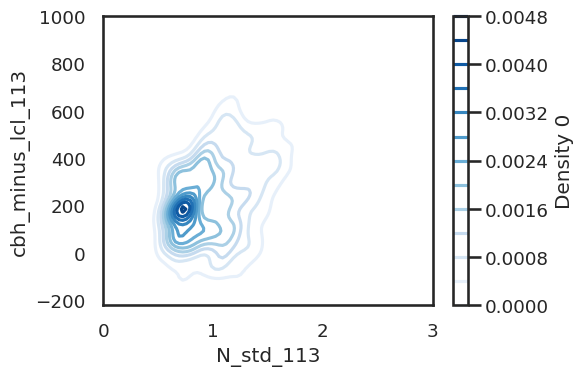

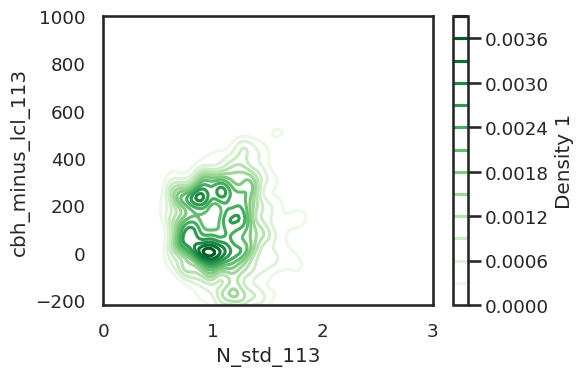

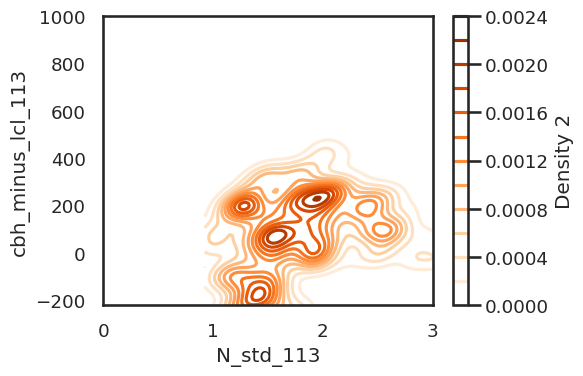

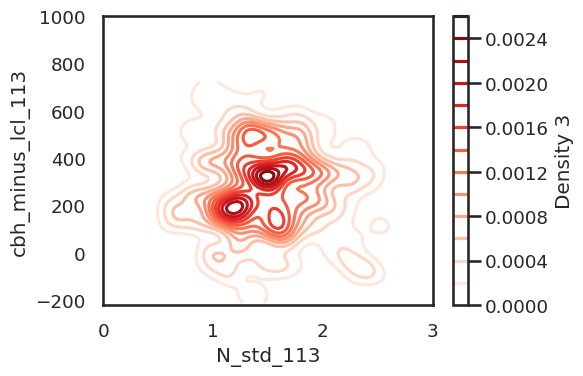

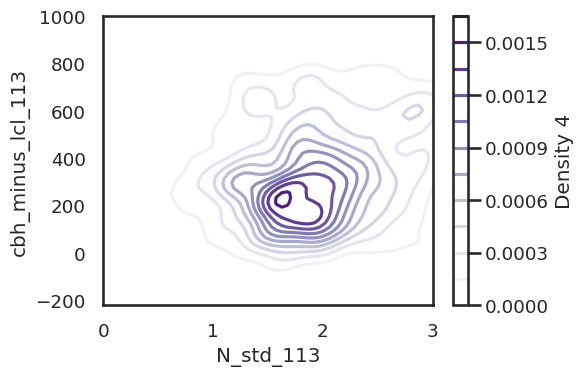

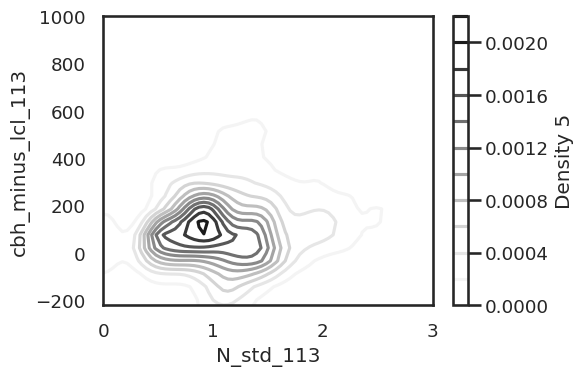

In [ ]:
contourplot('N_std_113', 'cbh_minus_lcl_113', df=dffil, kde=True)
plt.xlim(0,3)
plt.ylim(-220,1000)

## microphysics

### rain

In [250]:
# rain_rate_subcloud should be non-NaN everywhere (also in clear sky)
np.isnan(dffil[dffil.cloud_mask == 0]['rain_rate_subcloud']).sum() == 0

np.True_

In [251]:
# rain_rate_cbh should be NaN for clear sky (and can also be NaN for clouds that are not raining)
np.all(np.isnan(dffil[dffil.cloud_mask == 0]['rain_rate_cbh']))

np.True_

In [252]:
# rwp should be non-NaN everywhere (also in clear sky)
np.isnan(dffil[dffil.cloud_mask == 0]['rwp']).sum() == 0

np.True_

In [253]:
dffil['rain_rate_cbh_113'] = dffil.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.nanmean(x))
dffil['rain_rate_cbh_everywhere_113'] = dffil.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.mean(x.fillna(0)))

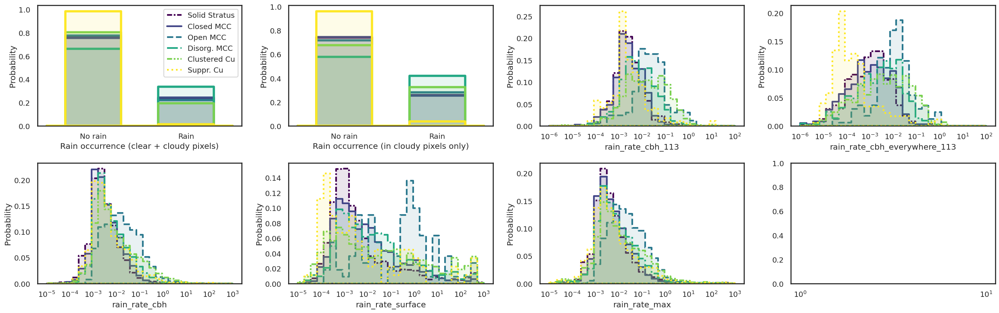

In [ ]:
fig, ax = plt.subplots(2,4, figsize=(25, 8))
for i in [0,1,2,3,4,5]: #6
    sns.histplot(ax=ax[0,0], x=(dffil[dffil['cats'] == i]['rain_rate_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(ax=ax[0,1], x=(dffil[dffil['cats'] == i][dffil.cloud_mask==1]['rain_rate_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(
        ax=ax[0,2], x=dffil[dffil['cats'] == i]['rain_rate_cbh_113']*3600, bins=np.logspace(-6,2,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[0,3], x=dffil[dffil['cats'] == i]['rain_rate_cbh_everywhere_113']*3600, bins=np.logspace(-6,2,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1,0], x=dffil[dffil['cats'] == i]['rain_rate_cbh']*3600, bins=np.logspace(-5,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1,1], x=dffil[dffil['cats'] == i]['rain_rate_surface']*3600, bins=np.logspace(-5,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1,2], x=dffil[dffil['cats'] == i]['rain_rate_max']*3600, bins=np.logspace(-5,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])

ax[0,0].legend(handles=legend_elements)
for a in ax.flatten()[2:]:
    a.set_xscale('log')

for a in ax.flatten()[0:2]:
    a.set_xticks([0,1])
    a.set_xticklabels(['No rain', 'Rain'])
ax[0,0].set_xlabel('Rain occurrence (clear + cloudy pixels)')
ax[0,1].set_xlabel('Rain occurrence (in cloudy pixels only)')
fig.tight_layout()

In [50]:
dffil['rwp'] = dffil['rwp'] * 1e3 # transform to g/m2
dffil['rwp_subcloud'] = dffil['rwp_subcloud'] * 1e3 # transform to g/m2

In [51]:
dffil['rain_occurrence'] = (dffil['rwp_subcloud'] > 0).astype(int)

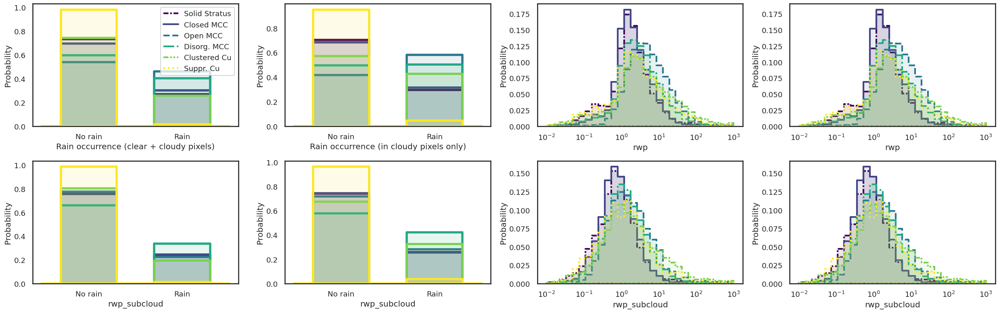

In [ ]:
fig, ax = plt.subplots(2,4, figsize=(25, 8))
for i in [0,1,2,3,4,5]: #6
    sns.histplot(ax=ax[0,0], x=(dffil[dffil['cats'] == i]['rwp'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(ax=ax[0,1], x=(dffil[dffil['cats'] == i][dffil.cloud_mask==1]['rwp'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(
        ax=ax[0,2], x=dffil[dffil['cats'] == i]['rwp'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[0,3], x=dffil[(dffil['cats'] == i) & (dffil['rwp']>0)]['rwp'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    
    sns.histplot(ax=ax[1,0], x=(dffil[dffil['cats'] == i]['rwp_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(ax=ax[1,1], x=(dffil[dffil['cats'] == i][dffil.cloud_mask==1]['rwp_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(
        ax=ax[1,2], x=dffil[dffil['cats'] == i]['rwp_subcloud'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1,3], x=dffil[(dffil['cats'] == i) & (dffil['rwp_subcloud']>0)]['rwp_subcloud'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])

ax[0,0].legend(handles=legend_elements)
for a in [ax[0,2], ax[0,3], ax[1,2], ax[1,3]]:
    a.set_xscale('log')

for a in [ax[0,0], ax[0,1], ax[1,0], ax[1,1]]:
    a.set_xticks([0,1])
    a.set_xticklabels(['No rain', 'Rain'])
ax[0,0].set_xlabel('Rain occurrence (clear + cloudy pixels)')
ax[0,1].set_xlabel('Rain occurrence (given a cloud)')
fig.tight_layout()

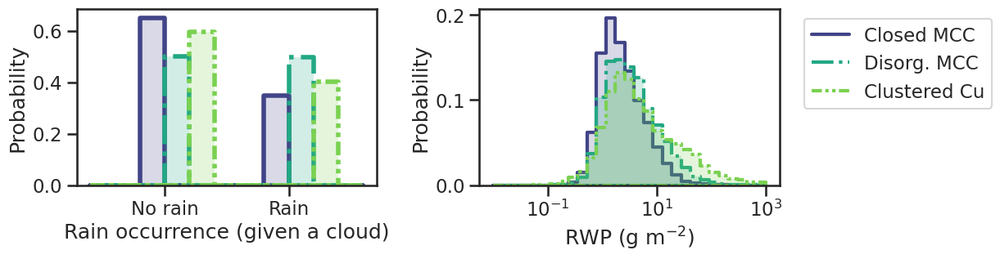

In [262]:
cats = [1,3,4]

fig, ax = plt.subplots(1,2, figsize=(10, 3.5))
for j,i in enumerate(cats): #6
    sns.histplot(ax=ax[0], x=(dffil[dffil['cats'] == i][dffil.cloud_mask==1]['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', color=catcolors[i], lw=4, ls=line_styles[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i) & (dffil['rwp']>0)]['rwp'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])


ax[1].set_xscale('log')
ax[1].set_xlabel('RWP (g m$^{-2}$)')

ax[0].set_xticks([0.1,1.1])
ax[0].set_xticklabels(['No rain', 'Rain'])
ax[0].set_xlabel('Rain occurrence (given a cloud)')
fig.tight_layout()

legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
ax[1].legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), loc='upper left')

### LWP, Nd, ER

In [ ]:
AB_end = pd.to_datetime('2025-05-08')
AC_start = pd.to_datetime('2025-05-09')
AC_end = pd.to_datetime('2025-06-11')
AD_start = pd.to_datetime('2025-06-13')
AD_end = pd.to_datetime('2025-07-07')
BA_start = pd.to_datetime('2025-07-09')

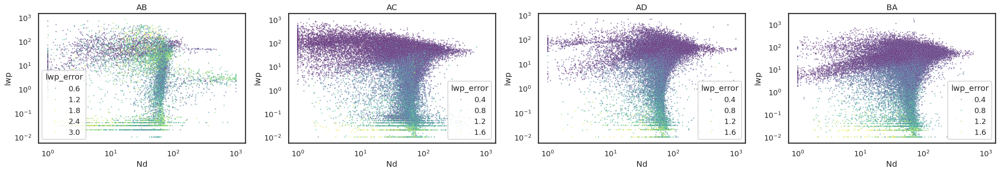

In [ ]:
fig, ax = plt.subplots(1,4, figsize=(25,4.5))
sns.scatterplot(ax=ax[0], data=dffil[pd.to_datetime(dffil.time) <= AB_end], x='Nd', y='lwp', hue='lwp_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,1.5))
sns.scatterplot(ax=ax[1], data=dffil[(pd.to_datetime(dffil.time) >= AC_start) & (pd.to_datetime(dffil.time) <= AC_end)], x='Nd', y='lwp', hue='lwp_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,1.5))
sns.scatterplot(ax=ax[2], data=dffil[(pd.to_datetime(dffil.time) >= AD_start) & (pd.to_datetime(dffil.time) <= AD_end)], x='Nd', y='lwp', hue='lwp_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,1.5))
sns.scatterplot(ax=ax[3], data=dffil[pd.to_datetime(dffil.time) >= BA_start], x='Nd', y='lwp', hue='lwp_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,1.5))
ax[0].set_title('AB')
ax[1].set_title('AC')
ax[2].set_title('AD')
ax[3].set_title('BA')
for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')
fig.tight_layout()

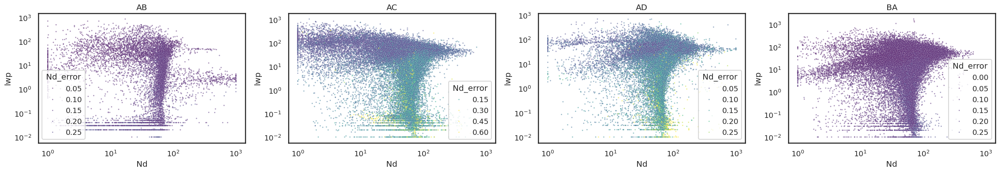

In [ ]:
fig, ax = plt.subplots(1,4, figsize=(25,4.5))
sns.scatterplot(ax=ax[0], data=dffil[pd.to_datetime(dffil.time) <= AB_end], x='Nd', y='lwp', hue='Nd_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,1.5))
sns.scatterplot(ax=ax[1], data=dffil[(pd.to_datetime(dffil.time) >= AC_start) & (pd.to_datetime(dffil.time) <= AC_end)], x='Nd', y='lwp', hue='Nd_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,0.3))
sns.scatterplot(ax=ax[2], data=dffil[(pd.to_datetime(dffil.time) >= AD_start) & (pd.to_datetime(dffil.time) <= AD_end)], x='Nd', y='lwp', hue='Nd_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,0.3))
sns.scatterplot(ax=ax[3], data=dffil[pd.to_datetime(dffil.time) >= BA_start], x='Nd', y='lwp', hue='Nd_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,1.5))
ax[0].set_title('AB')
ax[1].set_title('AC')
ax[2].set_title('AD')
ax[3].set_title('BA')
for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')
fig.tight_layout()

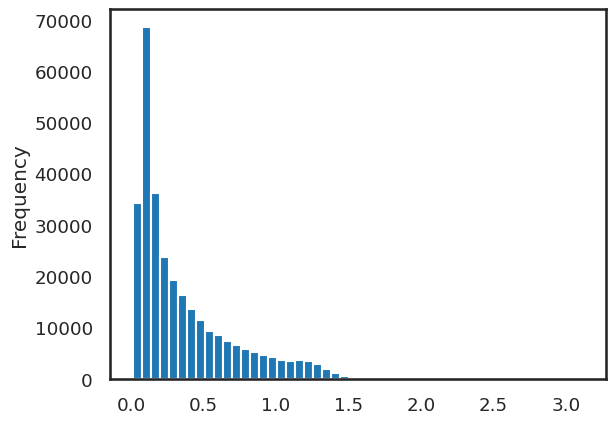

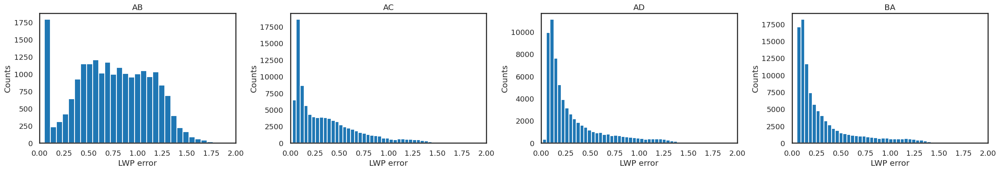

In [ ]:
dffil.lwp_error.plot.hist(bins=50)

fig, ax = plt.subplots(1,4, figsize=(25,4.5))
dffil[pd.to_datetime(dffil.time) <= AB_end].lwp_error.plot.hist(ax=ax[0], bins=50)
dffil[(pd.to_datetime(dffil.time) >= AC_start) & (pd.to_datetime(dffil.time) <= AC_end)].lwp_error.plot.hist(ax=ax[1], bins=50)
dffil[(pd.to_datetime(dffil.time) >= AD_start) & (pd.to_datetime(dffil.time) <= AD_end)].lwp_error.plot.hist(ax=ax[2], bins=50)
dffil[pd.to_datetime(dffil.time) >= BA_start].lwp_error.plot.hist(ax=ax[3], bins=50)
ax[0].set_title('AB')
ax[1].set_title('AC')
ax[2].set_title('AD')
ax[3].set_title('BA')
for a in ax:
    a.set_xlim(0,2)
    a.set_xlabel('LWP error')
    a.set_ylabel('Counts')
fig.tight_layout()

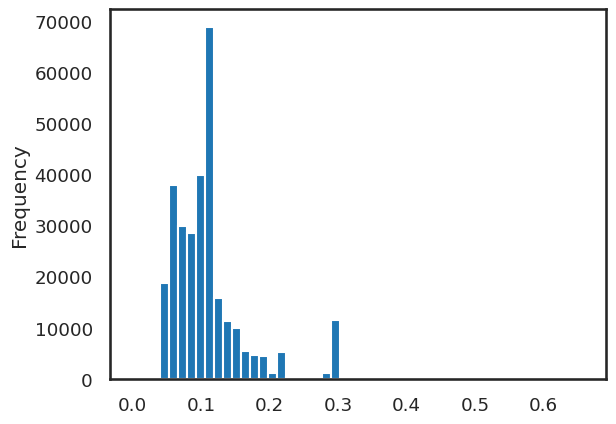

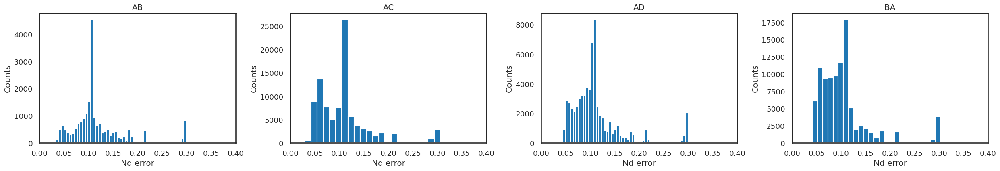

In [ ]:
dffil.Nd_error.plot.hist(bins=50)

fig, ax = plt.subplots(1,4, figsize=(25,4.5))
dffil[pd.to_datetime(dffil.time) <= AB_end].Nd_error.plot.hist(ax=ax[0], bins=50)
dffil[(pd.to_datetime(dffil.time) >= AC_start) & (pd.to_datetime(dffil.time) <= AC_end)].Nd_error.plot.hist(ax=ax[1], bins=50)
dffil[(pd.to_datetime(dffil.time) >= AD_start) & (pd.to_datetime(dffil.time) <= AD_end)].Nd_error.plot.hist(ax=ax[2], bins=50)
dffil[pd.to_datetime(dffil.time) >= BA_start].Nd_error.plot.hist(ax=ax[3], bins=50)
ax[0].set_title('AB')
ax[1].set_title('AC')
ax[2].set_title('AD')
ax[3].set_title('BA')
for a in ax:
    a.set_xlim(0,0.4)
    a.set_xlabel('Nd error')
    a.set_ylabel('Counts')
fig.tight_layout()

In [52]:
dffil['Nd'] = dffil['Nd'] * 1e-6 # transform to cm-3
dffil['lwp'] = dffil['lwp'] * 1e3 # transform to g/m2

In [53]:
dffil['lwp_fil'] = dffil['lwp'].where((dffil.lwp_error <= 0.3) & (dffil.Nd_error <= 0.125))
dffil['Nd_fil'] = dffil['Nd'].where((dffil.lwp_error <= 0.3) & (dffil.Nd_error <= 0.125))
dffil['ER_fil'] = dffil['ER'].where((dffil.lwp_error <= 0.3) & (dffil.Nd_error <= 0.125))

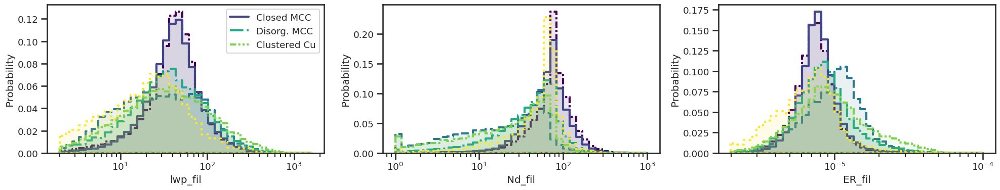

In [352]:
fig, ax = plt.subplots(1,3, figsize=(20, 4))
for i in [0,1,2,3,4,5]: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_fil', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_fil', bins=np.logspace(0,3,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_fil', bins=np.logspace(-5.7,-4,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
ax[0].legend(handles=legend_elements)
fig.tight_layout()

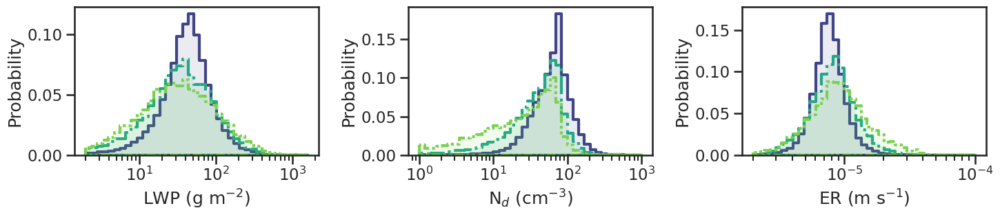

In [261]:
cats = [1,3,4]

fig, ax = plt.subplots(1,3, figsize=(15, 3.5))
for i in cats: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_fil', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_fil', bins=np.logspace(0,3,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_fil', bins=np.logspace(-5.7,-4,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
#ax[0].legend(handles=legend_elements)
ax[0].set_xlabel('LWP (g m$^{-2}$)')
ax[1].set_xlabel('N$_d$ (cm$^{-3}$)')
ax[2].set_xlabel('ER (m s$^{-1}$)')
fig.tight_layout()

In [376]:
dffil['MCOP_cloud_water_path'] = dffil['MCOP_cloud_water_path'] * 1e3 # transform to g/m2

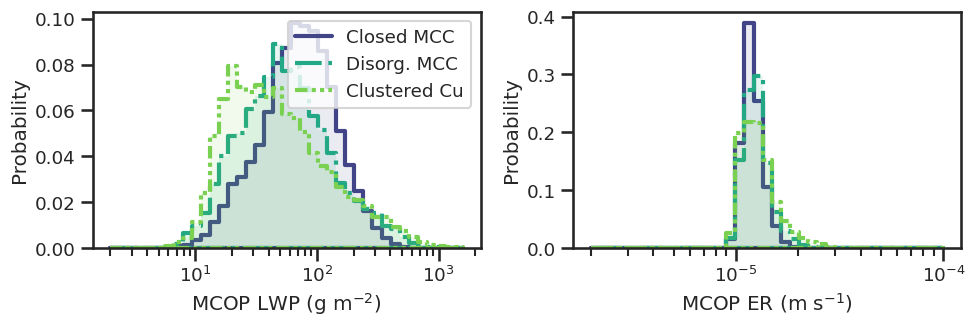

In [380]:
cats = [1,3,4]

fig, ax = plt.subplots(1,2, figsize=(10, 3.5))
for i in cats: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.MCOP_cloud_water_path > 0][dffil['cats'] == i], x='MCOP_cloud_water_path', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.MCOP_cloud_water_path > 0][dffil['cats'] == i], x='MCOP_effective_radius', bins=np.logspace(-5.7,-4,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
ax[0].legend(handles=legend_elements)
ax[0].set_xlabel('MCOP LWP (g m$^{-2}$)')
ax[1].set_xlabel('MCOP ER (m s$^{-1}$)')
fig.tight_layout()

In [359]:
df.MCOP_cloud_water_path
df.MCOP_effective_radius

0               NaN
1               NaN
2               NaN
3               NaN
4               NaN
             ...   
1122455         NaN
1122456         NaN
1122457         NaN
1122458         NaN
1122459    0.000011
Name: MCOP_effective_radius, Length: 535369, dtype: float64

0 2 38
0 5 77
1 0 275
1 1 80
1 2 0
3 5 8


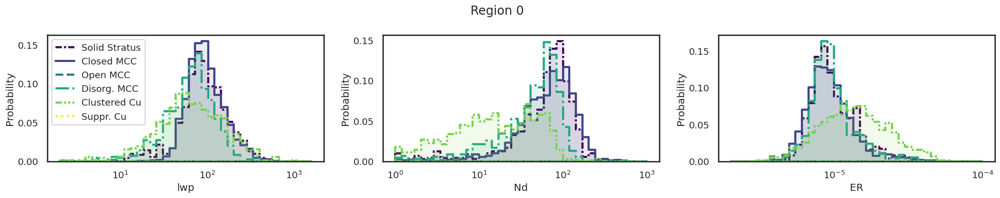

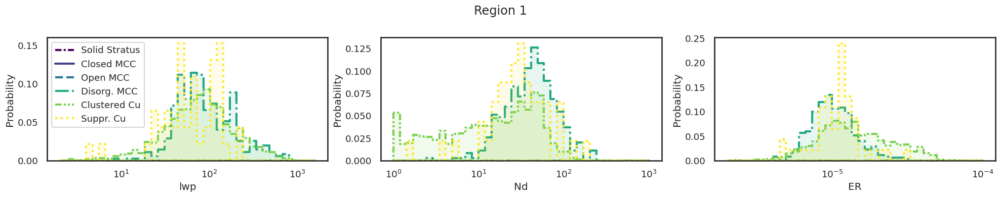

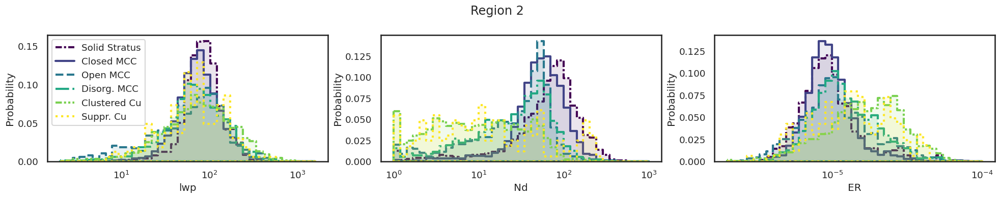

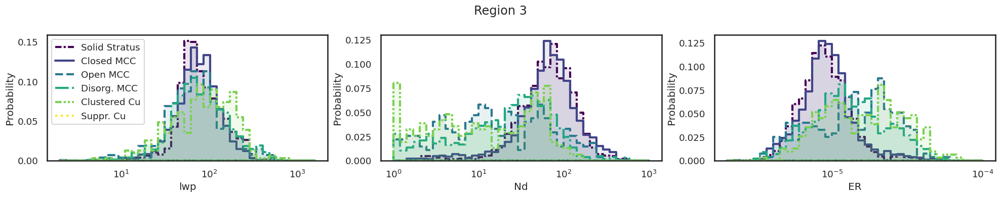

In [ ]:
for reg in [0,1,2,3]:
    fig, ax = plt.subplots(1,3, figsize=(20, 4))
    fig.suptitle(f'Region {reg}')
    for i in [0,1,2,3,4,5]: 
        d = dffil[(dffil.cloud_mask == 1) & (dffil['cats'] == i) & (dffil.stratus_region_index == reg)].dropna()
        if len(d.groupby('scene_id')['cats'].mean()) < 10: # at least 10 scenes per category
            print(reg, i, len(d))
            continue
        sns.histplot(
            ax=ax[0], data=d, x='lwp', bins=np.logspace(0.3,3.2,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
        sns.histplot(
            ax=ax[1], data=d, x='Nd', bins=np.logspace(0,3,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
        sns.histplot(
            ax=ax[2], data=d, x='ER', bins=np.logspace(-5.7,-4,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
    for a in ax.flatten():
        a.set_xscale('log')
    ax[0].legend(handles=legend_elements)
    fig.tight_layout()

1 0 275
1 1 80
0 2 38
1 2 0
0 5 77
3 5 8


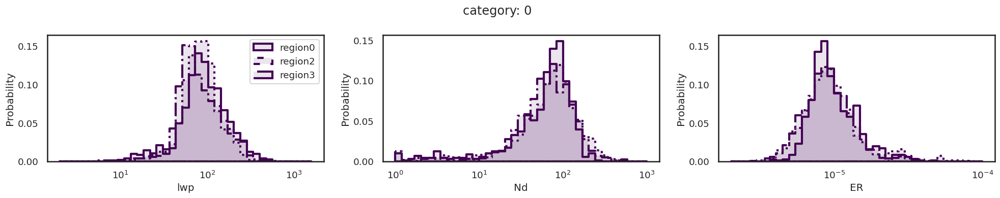

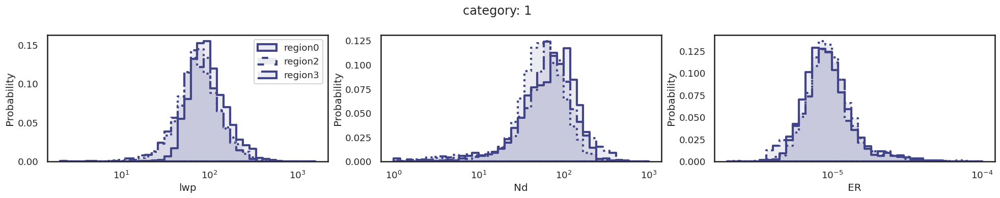

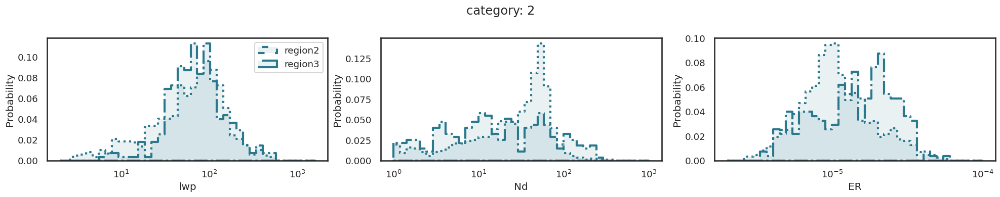

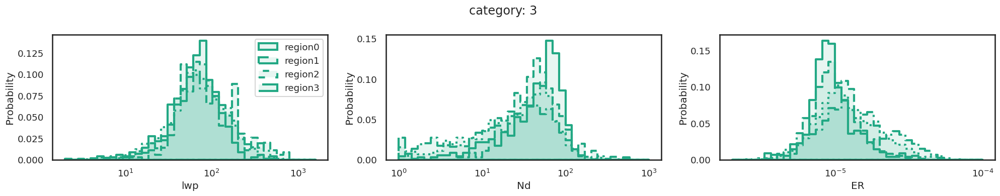

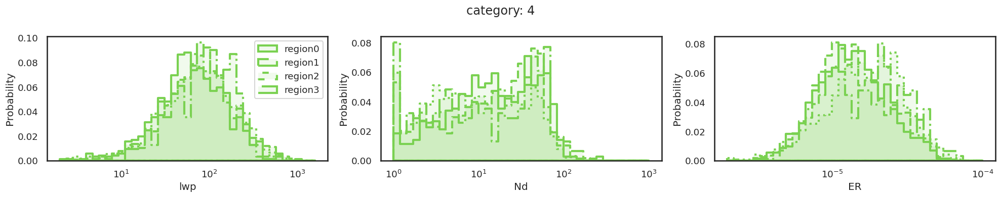

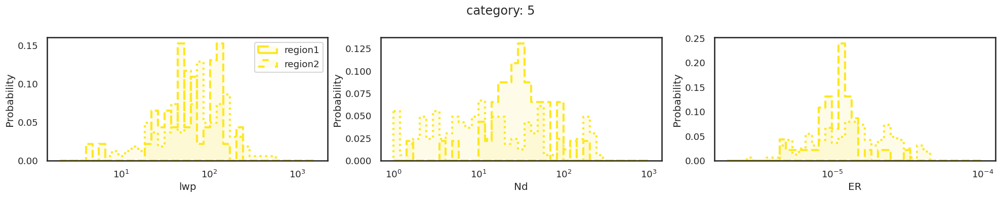

In [ ]:
line_styles_region = ['solid', 'dashed', 'dotted', 'dashdot']

for i in [0,1,2,3,4,5]: 
    fig, ax = plt.subplots(1,3, figsize=(20, 4))
    fig.suptitle(f'category: {i}')
    for reg in [0,1,2,3]:
        d = dffil[(dffil.cloud_mask == 1) & (dffil['cats'] == i) & (dffil.stratus_region_index == reg)].dropna()
        if len(d.groupby('scene_id')['cats'].mean()) < 10: # at least 10 scenes per category
            print(reg, i, len(d))
            continue
        sns.histplot(
            ax=ax[0], data=d, x='lwp', bins=np.logspace(0.3,3.2,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i], label='region'+str(reg))
        sns.histplot(
            ax=ax[1], data=d, x='Nd', bins=np.logspace(0,3,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i])
        sns.histplot(
            ax=ax[2], data=d, x='ER', bins=np.logspace(-5.7,-4,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i])
    for a in ax.flatten():
        a.set_xscale('log')
    ax[0].legend()
    fig.tight_layout()

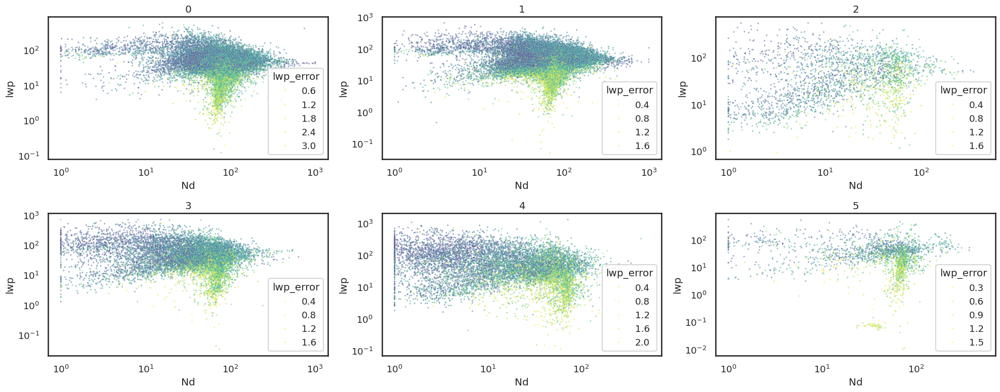

In [ ]:
fig, ax = plt.subplots(2,3, figsize=(20,8))
axs = ax.flatten()
for i in [0,1,2,3,4,5]: 
    sns.scatterplot(ax=axs[i], data=dffil[dffil.cats == i], x='Nd', y='lwp', hue='lwp_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,0.25))
    axs[i].set_title(i)
for a in axs:
    a.set_xscale('log')
    a.set_yscale('log')
fig.tight_layout()

## average vertical profile per cat

### 1d average vertical profile per cat

In [35]:
avg_profiles_1d = {}

for cat in range(6):
    cbh = dffil[dffil.cats == cat].cbh_m
    cth = dffil[dffil.cats == cat].cth_m

    profile_cat = xr.DataArray(np.zeros(30), dims=['height'], coords={'height': np.arange(30)*100})

    num_valid_scenes = 0
    for i in range(len(cbh)):
        if np.isnan(cbh.iloc[i]) or np.isnan(cth.iloc[i]):
            continue
        cbh_i = int(cbh.iloc[i] // 100)
        cth_i = int(cth.iloc[i] // 100)
        if cbh_i < 30 and cth_i < 30:
            profile_cat[cbh_i:cth_i+1] += 1
            num_valid_scenes += 1
            
    avg_profiles_1d[cat] = profile_cat / num_valid_scenes

KeyboardInterrupt: 

In [36]:
avg_profiles_1d_normed_cth = {}

for cat in range(6):
    cbh = dffil[dffil.cats == cat].cbh_m
    cth = dffil[dffil.cats == cat].cth_m
    thickness = cth - cbh + 100

    profile_cat = xr.DataArray(np.zeros(30), dims=['height'], coords={'height': np.arange(30)*100})

    num_valid_scenes = 0
    for i in range(len(cbh)):
        if np.isnan(thickness.iloc[i]):
            continue
        thickness_i = int(thickness.iloc[i] // 100)
        profile_cat[max(0, 30 - thickness_i):30] += 1
        num_valid_scenes += 1
            
    avg_profiles_1d_normed_cth[cat] = profile_cat / num_valid_scenes

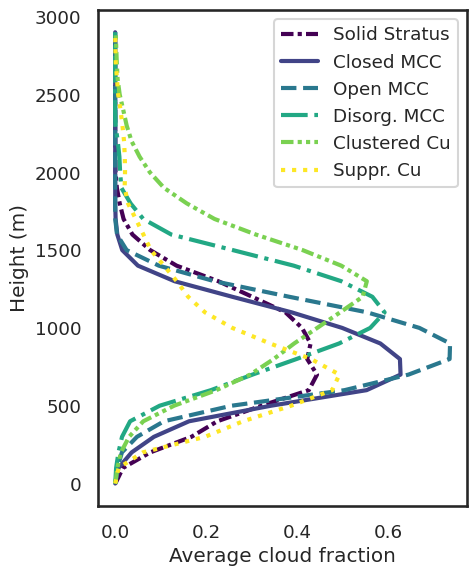

In [431]:
plt.figure(figsize=(5,6))
for cat in range(6):
    profile_cat = avg_profiles_1d[cat]
    plt.plot(profile_cat.values, profile_cat['height'].values, color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
plt.xlabel('Average cloud fraction')
plt.ylabel('Height (m)')
plt.legend()
plt.tight_layout()
plt.show()


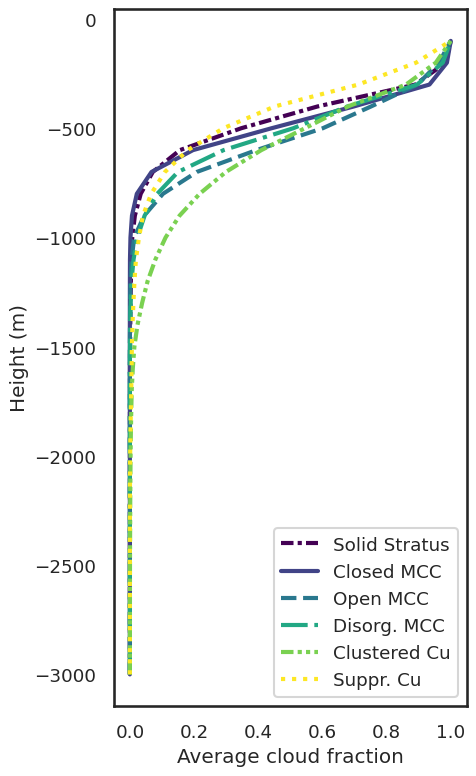

In [368]:
plt.figure(figsize=(5,8))
for cat in range(6):
    profile_cat = avg_profiles_1d_normed_cth[cat]
    plt.plot(profile_cat.values, profile_cat['height'].values - 3000, color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
plt.xlabel('Average cloud fraction')
plt.ylabel('Height (m)')
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
#profiles_1d = {}
#avg_scale = 10
#
#for cat in range(6):
#    profile_cat = None
#    cbh = dffil[dffil.cats == cat].cbh_m
#    cth = dffil[dffil.cats == cat].cth_m
#
#    for i in range(len(cbh)//avg_scale):
#        profile_cat_i = np.zeros(30)
#        for ii in range(avg_scale):
#            idx = i*avg_scale + ii
#            if np.isnan(cbh.iloc[idx]) or np.isnan(cth.iloc[idx]):
#                continue
#            cbh_i = int(cbh.iloc[idx] // 100)
#            cth_i = int(cth.iloc[idx] // 100)
#
#            profile_cat_i[cbh_i:min(30, cth_i+1)] += 1
#        profile_cat_i = profile_cat_i / avg_scale
#        
#        if profile_cat is None:
#            profile_cat = profile_cat_i
#        else:
#            profile_cat = np.vstack((profile_cat, profile_cat_i))
#            
#    profiles_1d[cat] = profile_cat

In [37]:
profiles_normed_cth_1d = {}

for cat in range(6):
    profile_cat = None
    cbh = dffil[dffil.cats == cat].cbh_m
    cth = dffil[dffil.cats == cat].cth_m
    thickness = cth - cbh + 100

    quantiles = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
    quantile_vals = thickness.quantile(quantiles).values

    for i in range(1, len(quantile_vals)):
        profile_cat_i = np.zeros(30)
        thickness_quant = thickness[(thickness >= quantile_vals[i-1]) & (thickness < quantile_vals[i])]
        for ii in range(len(thickness_quant)):
            if np.isnan(thickness_quant.iloc[ii]):
                continue
            thickness_ii = int(thickness_quant.iloc[ii] // 100)
            profile_cat_i[max(0, 30 - thickness_ii):30] += 1

        profile_cat_i = profile_cat_i / len(thickness_quant)

        if profile_cat is None:
            profile_cat = profile_cat_i
        else:
            profile_cat = np.vstack((profile_cat, profile_cat_i))
            
    profiles_normed_cth_1d[cat] = profile_cat

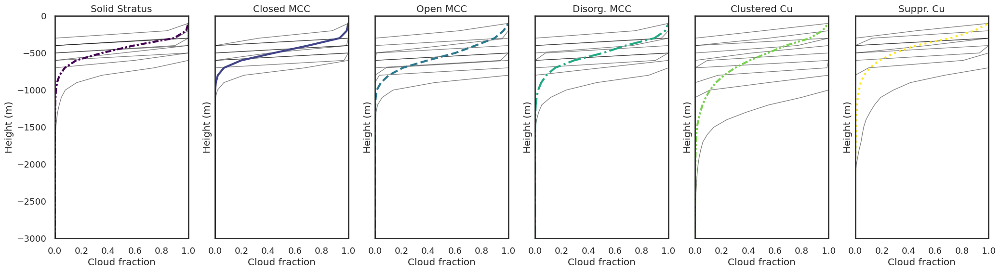

In [46]:
fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(25,6), sharey=True)
quantiles = [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]
for cat in range(6):
    profile_cat = profiles_normed_cth_1d[cat]
    for i in range(profile_cat.shape[0]):
        axs[cat].plot(profile_cat[i], np.arange(30)*100 - 3000, color='black', alpha=0.5, lw=1)
    avg_profile_cat = avg_profiles_1d_normed_cth[cat]
    axs[cat].plot(avg_profile_cat.values, avg_profile_cat['height'].values - 3000, color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
    axs[cat].set_xlabel('Cloud fraction')
    axs[cat].set_ylabel('Height (m)')
    axs[cat].set_title(cats_names[cat])
    axs[cat].set_xlim(0,1)
    axs[cat].set_ylim(-3000,0)

### 2d average vertical profile per cat

In [65]:
def add_profile(profile_arr, cbh_m, cth_m):
    # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
    for i in range(len(dfex)):
        cbh = cbh_m.values[i]
        cth = cth_m.values[i]
        if np.isnan(cbh) or np.isnan(cth):
            continue
        cbh_idx = int(cbh // 100)
        cth_idx = int(cth // 100)
        # Ensure indices are within bounds
        cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
        cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
        profile_arr[i, cbh_idx:cth_idx+1] += 1
    return profile_arr

In [ ]:
avg_profiles = {}
for cat in [0,1,2,3,4,5]:
    df_cat = df[df.cats == cat]
    scene_ids = df_cat.scene_id.unique()
    print(f'\ncat {cat} with {len(scene_ids)} scenes')

    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})

    num_valid_scenes = 0
    for si in scene_ids:
        #print(si)
        dfex = df_cat[df_cat.scene_id == si]
        if len(dfex) == 112: # some scenes have 112 points only, so we duplicate the last point
            dfex = pd.concat([dfex, pd.DataFrame(dfex.iloc[-1,:]).T]).reset_index(drop=True)
        if len(dfex) != 113:
            print(f'skipping scene {si} with {len(dfex)} points')
            continue
        if dfex.cert.iloc[0] < 0.75:
            print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
            continue
        if (dfex.ocean_mask != 1).all():
            print(f'skipping scene {si} with non-ocean points')
            continue

        profile_cat = add_profile(profile_cat, dfex.cbh_m, dfex.cth_m)
        num_valid_scenes += 1

    profile_cat = profile_cat / num_valid_scenes
    avg_profiles[cat] = profile_cat


cat 0 with 748 scenes
skipping scene 17 with 127 points
skipping scene 22 with low cert 0.73391724
skipping scene 25 with low cert 0.58158565
skipping scene 35 with low cert 0.7221943
skipping scene 42 with low cert 0.56422484
skipping scene 49 with 178 points
skipping scene 50 with 166 points
skipping scene 57 with 232 points
skipping scene 80 with low cert 0.5173724
skipping scene 123 with 225 points
skipping scene 145 with low cert 0.50802225
skipping scene 199 with low cert 0.40408826
skipping scene 213 with 217 points
skipping scene 219 with 116 points
skipping scene 248 with low cert 0.6156231
skipping scene 277 with low cert 0.53960246
skipping scene 306 with low cert 0.5735373
skipping scene 311 with low cert 0.5012679
skipping scene 332 with 231 points
skipping scene 337 with low cert 0.44286245
skipping scene 367 with low cert 0.6321818
skipping scene 379 with low cert 0.566886
skipping scene 421 with 150 points
skipping scene 431 with low cert 0.6237167716026306
skipping sc

In [ ]:
avg_profiles_per_region = {0: {}, 1: {}, 2: {}, 3: {}}
for region in [0,1,2,3]:
    for cat in [0,1,2,3,4,5]:
        df_cat = df[(df.cats == cat) & (df.stratus_region_index == region)]
        scene_ids = df_cat.scene_id.unique()
        print(f'\ncat {cat} with {len(scene_ids)} scenes')

        profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})

        num_valid_scenes = 0
        for si in scene_ids:
            #print(si)
            dfex = df_cat[df_cat.scene_id == si]
            if len(dfex) != 113:
                print(f'skipping scene {si} with {len(dfex)} points')
                continue
            if dfex.cert.iloc[0] < 0.75:
                print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
                continue
            if (dfex.ocean_mask != 1).all():
                print(f'skipping scene {si} with non-ocean points')
                continue

            profile_cat = add_profile(profile_cat, dfex.cbh_m, dfex.cth_m)
            num_valid_scenes += 1

        profile_cat = profile_cat / num_valid_scenes
        avg_profiles_per_region[region][cat] = profile_cat


cat 0 with 133 scenes
skipping scene 1571 with low cert 0.733917236328125
skipping scene 1574 with low cert 0.5815856456756592
skipping scene 1584 with low cert 0.7221943140029907
skipping scene 1591 with low cert 0.5642248392105103
skipping scene 1597 with low cert 0.5965360999107361
skipping scene 1598 with non-ocean points
skipping scene 1599 with low cert 0.6364901661872864
skipping scene 1629 with low cert 0.5173724293708801
skipping scene 1672 with low cert 0.6771941781044006
skipping scene 1694 with low cert 0.5080222487449646
skipping scene 1748 with low cert 0.4040882587432861
skipping scene 1762 with low cert 0.5056627988815308
skipping scene 1768 with low cert 0.6345291137695312
skipping scene 1797 with low cert 0.6156231164932251
skipping scene 1826 with low cert 0.5396024584770203
skipping scene 1855 with low cert 0.573537290096283
skipping scene 1860 with low cert 0.5012679100036621
skipping scene 1886 with low cert 0.4428624510765075
skipping scene 1916 with low cert 0.

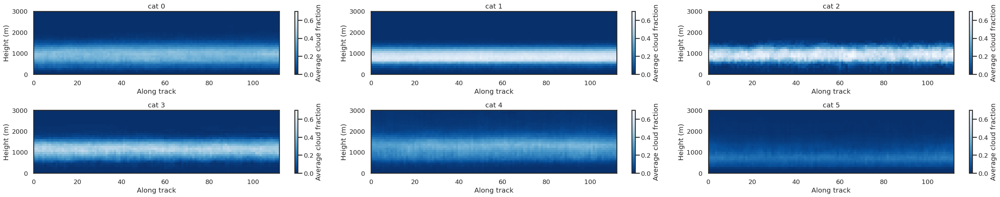

In [306]:
plt.subplots(2,3, figsize=(30,6))
for cat in [0,1,2,3,4,5]:
    plt.subplot(2,3,cat+1)
    plt.title(f'cat {cat}')
    plt.imshow(avg_profiles[cat].T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Blues_r', vmax=0.7)
    plt.colorbar(label='Average cloud fraction')
    plt.xlabel('Along track')
    plt.ylabel('Height (m)')
plt.tight_layout()

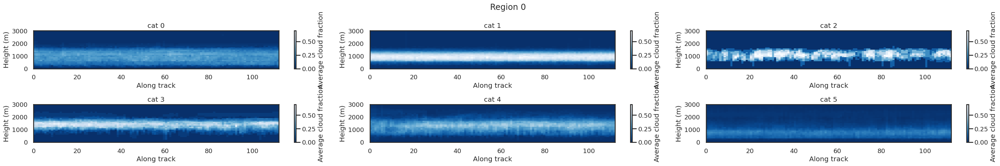

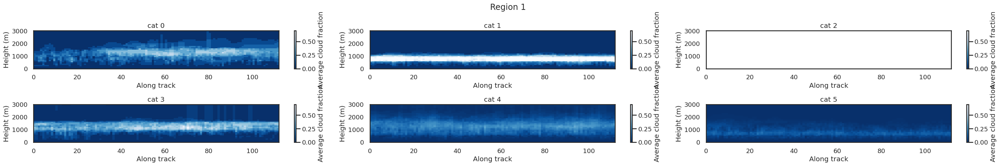

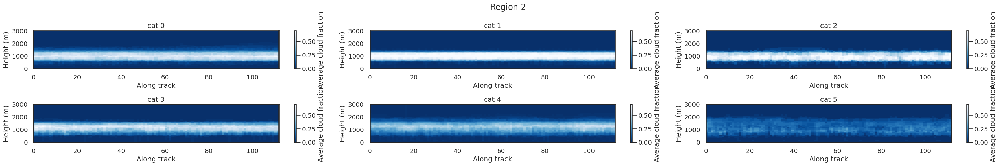

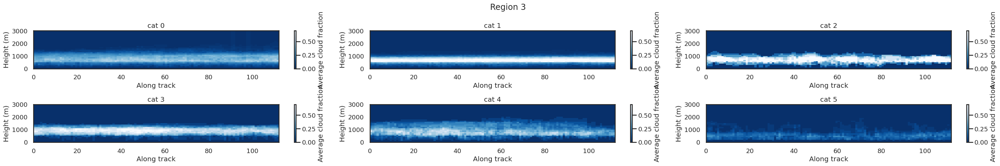

In [31]:
for region in [0,1,2,3]:
    plt.subplots(2,3, figsize=(30,5))
    plt.suptitle(f'Region {region}')
    for cat in [0,1,2,3,4,5]:
        plt.subplot(2,3,cat+1)
        plt.title(f'cat {cat}')
        plt.imshow(avg_profiles_per_region[region][cat].T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Blues_r', vmax=0.7)
        plt.colorbar(label='Average cloud fraction')
        plt.xlabel('Along track')
        plt.ylabel('Height (m)')
    plt.tight_layout()
    plt.show()


cat 2 with 108 scenes


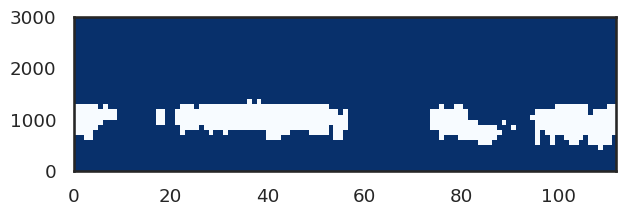

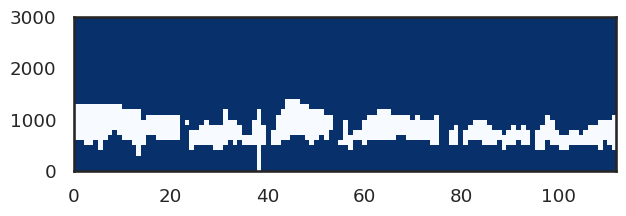

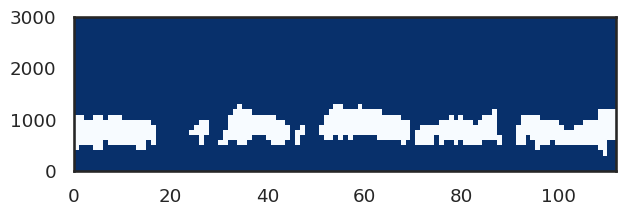

skipping scene 1647 with low cert 0.5306299924850464
skipping scene 1655 with low cert 0.6836847066879272
skipping scene 1656 with low cert 0.526387095451355
skipping scene 1657 with 112 points
skipping scene 1660 with low cert 0.614243745803833


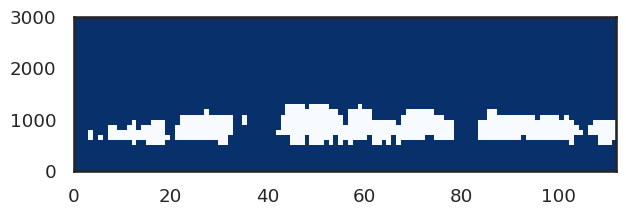

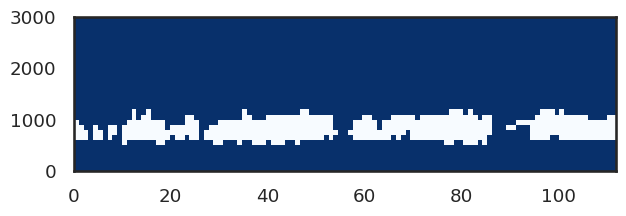

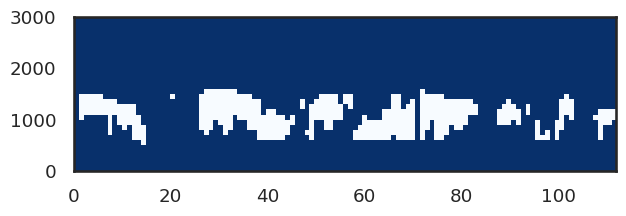

skipping scene 2185 with low cert 0.5023829936981201
skipping scene 2239 with low cert 0.6803068518638611
skipping scene 2655 with 89 points
skipping scene 2715 with low cert 0.538474440574646


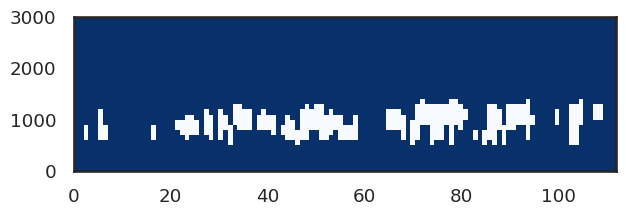

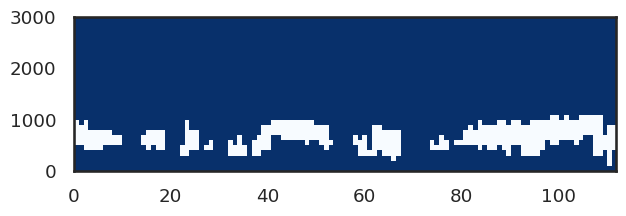

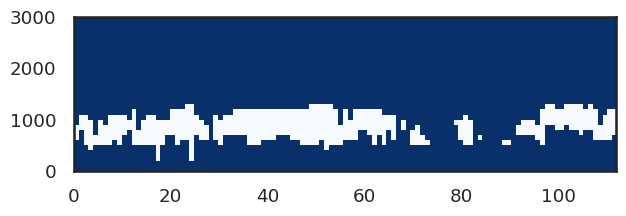

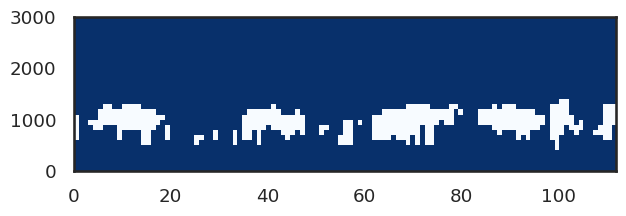

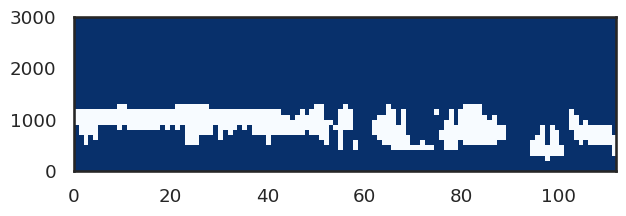

skipping scene 2933 with 112 points


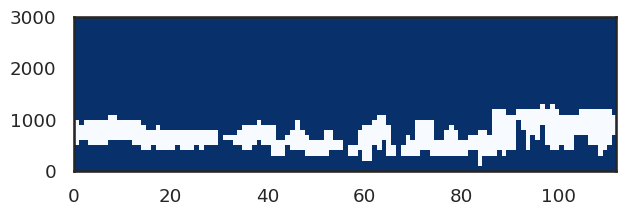

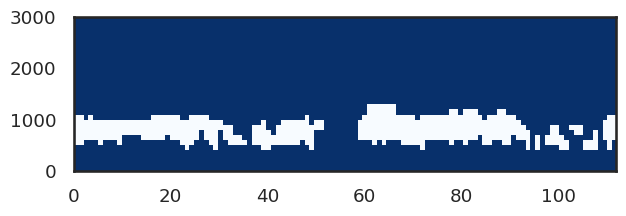

skipping scene 3051 with low cert 0.7093806862831116
skipping scene 3155 with 70 points


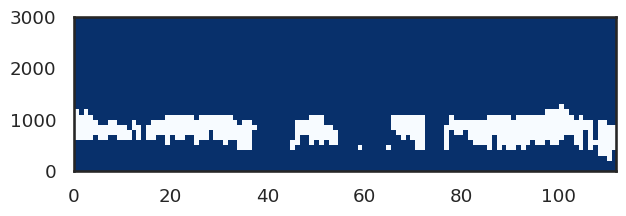

skipping scene 3263 with low cert 0.5734316110610962
skipping scene 3273 with low cert 0.3767310082912445
skipping scene 3280 with low cert 0.5272645950317383
skipping scene 3347 with low cert 0.5065200924873352


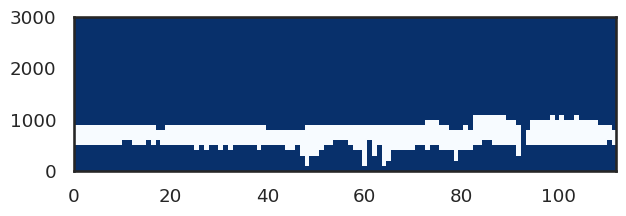

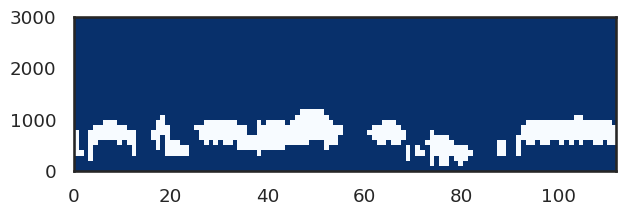

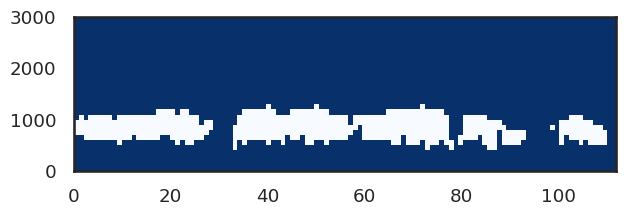

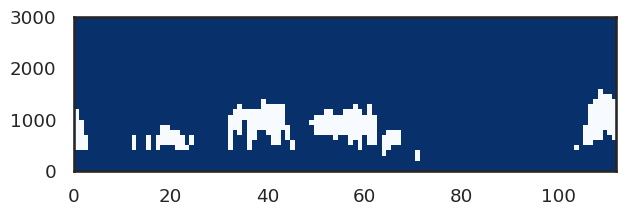

skipping scene 3397 with low cert 0.5725045800209045
skipping scene 3439 with 112 points


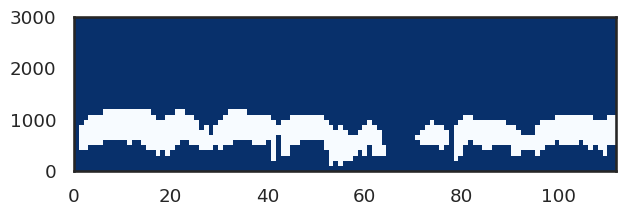

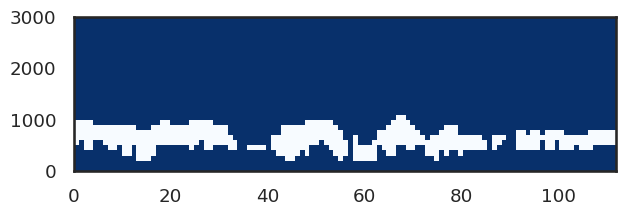

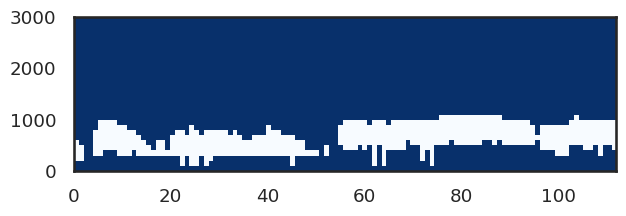

In [59]:
cat = 2
df_cat = df[df.cats == cat]
scene_ids = df_cat.scene_id.unique()
print(f'\ncat {cat} with {len(scene_ids)} scenes')

for si in scene_ids[-40:-1]:
    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    #print(si)
    dfex = df_cat[df_cat.scene_id == si]
    if len(dfex) != 113:
        print(f'skipping scene {si} with {len(dfex)} points')
        continue
    if dfex.cert.iloc[0] < 0.75:
        print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
        continue
    if (dfex.ocean_mask != 1).all():
        print(f'skipping scene {si} with non-ocean points')
        continue

    profile_cat = add_profile(profile_cat, dfex.cbh_m, dfex.cth_m)
    plt.figure(figsize = (7,2))
    plt.imshow(profile_cat.T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Blues_r')
    plt.show()

#### 2d average vertical profile per cat - normalized to CTH or LCL

In [307]:
def add_profile_norm_cth(profile_arr, cbh_m, cth_m):
    # between dfex.cbh_m and dfex.cth_m (both arrays of size 112), the profile_arr should be filled with 1
    for i in range(len(dfex)):
        cbh = cbh_m.values[i]
        cth = cth_m.values[i]
        if np.isnan(cbh) or np.isnan(cth):
            continue
        cbh_idx = int(cbh // 100)
        cth_idx = int(cth // 100)
        # Ensure indices are within bounds
        thickness = cth_idx - cbh_idx
        ceiling = profile_arr.shape[1] - 1
        profile_arr[i, ceiling-thickness:ceiling] += 1
    return profile_arr

In [308]:
def add_profile_norm_lcl(profile_arr, cbh_m, cth_m, cbh_minus_lcl):
    # between dfex.cbh_m and dfex.cth_m (both arrays of size 112), the profile_arr should be filled with 1
    for i in range(len(dfex)):
        cbh = cbh_m.values[i]
        cth = cth_m.values[i]
        lcl = cbh - cbh_minus_lcl.values[i]
        if np.isnan(cbh) or np.isnan(cth) or np.isnan(lcl):
            continue
        cbh_idx = int(cbh // 100)
        cth_idx = int(cth // 100)
        lcl_idx = int(lcl // 100)

        cth_minus_lcl_idx = cth_idx - lcl_idx + 5
        cbh_minus_lcl_idx = cbh_idx - lcl_idx + 5

        cbh_minus_lcl_idx = max(0, min(cbh_minus_lcl_idx, profile_arr.shape[1] - 1))
        cth_minus_lcl_idx = max(0, min(cth_minus_lcl_idx, profile_arr.shape[1] - 1))

        profile_arr[i, cbh_minus_lcl_idx:cth_minus_lcl_idx+1] += 1
    return profile_arr

In [309]:
# TODO: add rain rate profiles
avg_profiles_normed_cth = {}
avg_profiles_normed_lcl = {}
for cat in [0,1,2,3,4,5]:
    df_cat = df[df.cats == cat]
    scene_ids = df_cat.scene_id.unique()
    print(f'\ncat {cat} with {len(scene_ids)} scenes')

    profile_cat_normed_cth = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    profile_cat_normed_lcl = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})

    num_valid_scenes = 0
    for si in scene_ids:
        #print(si)
        dfex = df_cat[df_cat.scene_id == si]
        if len(dfex) == 112:
            dfex = pd.concat([dfex, pd.DataFrame(dfex.iloc[-1,:]).T]).reset_index(drop=True)
            
        if len(dfex) != 113:
            print(f'skipping scene {si} with {len(dfex)} points')
            continue
        if dfex.cert.iloc[0] < 0.75:
            print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
            continue
        if (dfex.ocean_mask != 1).all():
            print(f'skipping scene {si} with non-ocean points')
            continue

        profile_cat_normed_cth = add_profile_norm_cth(profile_cat_normed_cth, dfex.cbh_m, dfex.cth_m)
        profile_cat_normed_lcl = add_profile_norm_lcl(profile_cat_normed_lcl, dfex.cbh_m, dfex.cth_m, dfex.cbh_minus_lcl)
        num_valid_scenes += 1

    profile_cat_normed_cth = profile_cat_normed_cth / num_valid_scenes
    profile_cat_normed_lcl = profile_cat_normed_lcl / num_valid_scenes
    avg_profiles_normed_cth[cat] = profile_cat_normed_cth
    avg_profiles_normed_lcl[cat] = profile_cat_normed_lcl


cat 0 with 748 scenes
skipping scene 17 with 127 points
skipping scene 22 with low cert 0.73391724
skipping scene 25 with low cert 0.58158565
skipping scene 35 with low cert 0.7221943
skipping scene 42 with low cert 0.56422484
skipping scene 49 with 178 points
skipping scene 50 with 166 points
skipping scene 57 with 232 points
skipping scene 80 with low cert 0.5173724
skipping scene 123 with 225 points
skipping scene 145 with low cert 0.50802225
skipping scene 199 with low cert 0.40408826
skipping scene 213 with 217 points
skipping scene 219 with 116 points
skipping scene 248 with low cert 0.6156231
skipping scene 277 with low cert 0.53960246
skipping scene 306 with low cert 0.5735373
skipping scene 311 with low cert 0.5012679
skipping scene 332 with 231 points
skipping scene 337 with low cert 0.44286245
skipping scene 367 with low cert 0.6321818
skipping scene 379 with low cert 0.566886
skipping scene 421 with 150 points
skipping scene 431 with low cert 0.6237167716026306
skipping sc

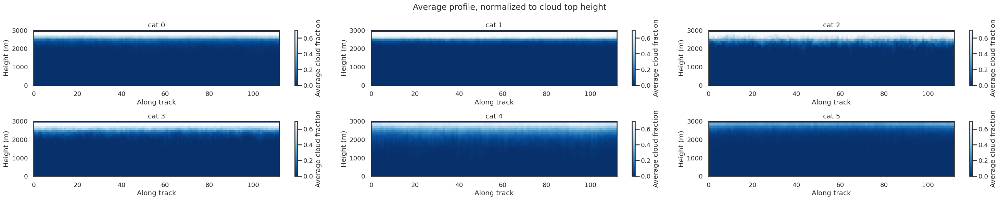

In [311]:
plt.subplots(2,3, figsize=(30,6))
plt.suptitle('Average profile, normalized to cloud top height')
for cat in [0,1,2,3,4,5]:
    plt.subplot(2,3,cat+1)
    plt.title(f'cat {cat}')
    plt.imshow(avg_profiles_normed_cth[cat].T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Blues_r', vmax=0.7)
    plt.colorbar(label='Average cloud fraction')
    plt.xlabel('Along track')
    plt.ylabel('Height (m)')
plt.tight_layout()

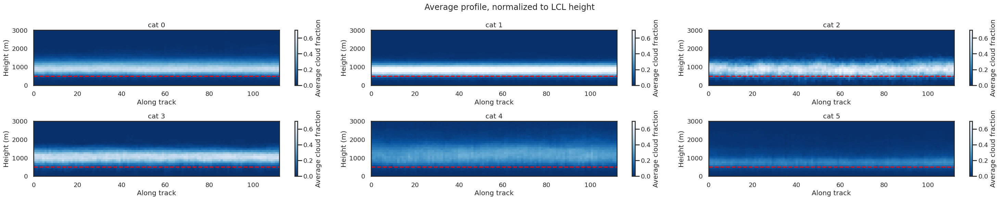

In [312]:
plt.subplots(2,3, figsize=(30,6))
plt.suptitle('Average profile, normalized to LCL height')
for cat in [0,1,2,3,4,5]:
    plt.subplot(2,3,cat+1)
    plt.title(f'cat {cat}')
    plt.imshow(avg_profiles_normed_lcl[cat].T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Blues_r', vmax=0.7)
    plt.colorbar(label='Average cloud fraction')
    plt.xlabel('Along track')
    plt.ylabel('Height (m)')
    plt.hlines(500,0,112, color='red', ls='--')
plt.tight_layout()

## archetypical profiles

In [263]:
def add_profile(profile_arr, cbh_m, cth_m):
    # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
    for i in range(len(dfex)):
        cbh = cbh_m.values[i]
        cth = cth_m.values[i]
        if np.isnan(cbh) or np.isnan(cth):
            continue
        cbh_idx = int(cbh // 100)
        cth_idx = int(cth // 100)
        # Ensure indices are within bounds
        cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
        cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
        profile_arr[i, cbh_idx:cth_idx+1] += 1
    return profile_arr

#### archetypical profiles by mean profile values

In [264]:
profile_vars = ['cbh_m', 'cth_m', 'cbh_max_minus_min_113', 'cbh_minus_lcl_113', 'coupled_fraction', 'N_mean_113', 'N_std_113', 'cloud_fraction']
#profile_vars = ['cbh_max_minus_min_113', 'cbh_minus_lcl_113', 'coupled_fraction', 'N_mean_113', 'N_std_113']

profile_vars = ['cbh_m', 'cth_m', 'cbh_max_minus_min_113', 'cbh_minus_lcl_113', 'N_mean_113', 'cloud_fraction',
                'lwp_fil', 'rain_occurrence', 'rwp']

In [309]:
cat = 2
dfcat = dffil[dffil.cats == cat]

In [321]:
# find scenes that fall within the 40-60% quantile for all profile_vars
dfcat_sel = dfcat[['orbit', 'scene_id'] + profile_vars].copy()
dfcat_sel = dfcat_sel.groupby(['orbit', 'scene_id']).mean().reset_index()
quantiles = dfcat_sel[profile_vars].quantile([0.2,0.25, 0.5, 0.75])

In [322]:
quantiles

,cbh_m,cth_m,cbh_max_minus_min_113,cbh_minus_lcl_113,N_mean_113,cloud_fraction,lwp_fil,rain_occurrence,rwp
0.20,571.021851,956.194336,511.429816,-94.982523,4.504478,0.707965,25.302788,0.079646,1.886677
0.25,601.910950,980.582458,522.195740,-76.097763,4.698571,0.742217,29.990430,0.097345,2.047287
0.50,653.035217,1091.330200,627.237671,35.885868,5.164557,0.805310,41.208336,0.238938,4.568998
0.75,723.102600,1205.582397,828.822601,149.238228,5.652395,0.893805,57.050558,0.367257,7.913379


In [323]:
print(f'Initial number of scenes in cat {cat}: {len(dfcat_sel)}')
for var in profile_vars:
    #dfcat_sel = dfcat_sel[(dfcat_sel[var] >= quantiles[var][0.25]) & (dfcat_sel[var] <= quantiles[var][0.75])]
    dfcat_sel = dfcat_sel[(dfcat_sel[var] >= quantiles[var][0.2]) & (dfcat_sel[var] <= quantiles[var][0.75])]
    print(f'After applying {var} quantile filter, number of scenes in cat {cat}: {len(dfcat_sel)}')

    # distance to 0.5 quantile as a measure of how close the scene is to the median
    dfcat_sel['dist_' + var] = np.abs(dfcat_sel[var] - quantiles[var][0.5]) / (quantiles[var][0.75] - quantiles[var][0.25])

print(f'Final number of scenes in cat {cat}: {len(dfcat_sel)}')

Initial number of scenes in cat 2: 147
After applying cbh_m quantile filter, number of scenes in cat 2: 80
After applying cth_m quantile filter, number of scenes in cat 2: 64
After applying cbh_max_minus_min_113 quantile filter, number of scenes in cat 2: 31
After applying cbh_minus_lcl_113 quantile filter, number of scenes in cat 2: 18
After applying N_mean_113 quantile filter, number of scenes in cat 2: 12
After applying cloud_fraction quantile filter, number of scenes in cat 2: 9
After applying lwp_fil quantile filter, number of scenes in cat 2: 6
After applying rain_occurrence quantile filter, number of scenes in cat 2: 6
After applying rwp quantile filter, number of scenes in cat 2: 5
Final number of scenes in cat 2: 5


In [324]:
dfcat_sel['dist_mean'] = dfcat_sel[[f'dist_{v}' for v in profile_vars]].mean(axis=1)
dfcat_sel = dfcat_sel.sort_values('dist_mean')

dfcat_sel

,orbit,scene_id,cbh_m,cth_m,cbh_max_minus_min_113,cbh_minus_lcl_113,N_mean_113,cloud_fraction,lwp_fil,rain_occurrence,...,dist_cbh_m,dist_cth_m,dist_cbh_max_minus_min_113,dist_cbh_minus_lcl_113,dist_N_mean_113,dist_cloud_fraction,dist_lwp_fil,dist_rain_occurrence,dist_rwp,dist_mean
129,07093E,16092.0,680.553162,1114.847168,528.098633,-38.722263,5.209302,0.761062,34.429317,0.265487,...,0.227061,0.104520,0.323321,0.331097,0.046912,0.291895,0.250517,0.098361,0.194945,0.207625
110,06844E,15726.0,617.027405,1027.446411,727.022766,-35.921532,4.866667,0.796460,40.656311,0.168142,...,0.297115,0.283928,0.325428,0.318668,0.312312,0.058379,0.020400,0.262295,0.135876,0.223822
124,07093E,6756.0,694.715515,1080.820312,528.098633,-87.566956,4.731959,0.858407,35.834911,0.256637,...,0.343921,0.046711,0.323321,0.547861,0.453541,0.350274,0.198574,0.065574,0.337396,0.296352
30,06439E,2183.0,639.359070,1048.380615,733.638062,148.253311,4.938272,0.716814,28.913607,0.221239,...,0.112847,0.190887,0.347003,0.498666,0.237240,0.583789,0.454349,0.065574,0.322480,0.312537
49,06548E,2358.0,588.051270,979.665100,621.096680,-82.868385,4.795918,0.867257,32.939491,0.115044,...,0.536208,0.496289,0.020028,0.527010,0.386485,0.408653,0.305573,0.459016,0.007416,0.349631


07093E


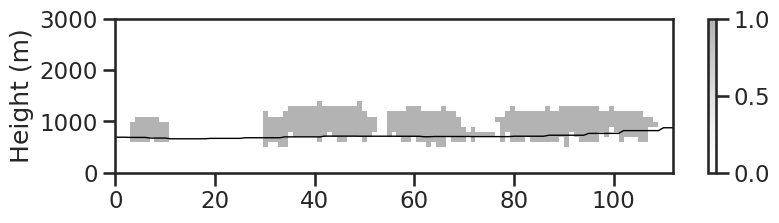

06844E


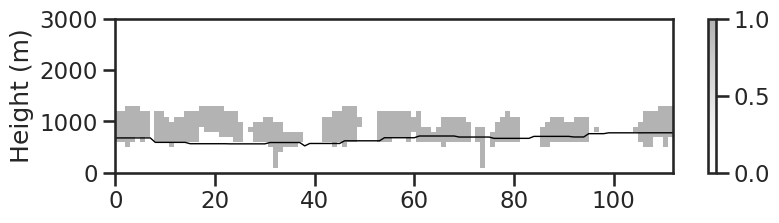

07093E


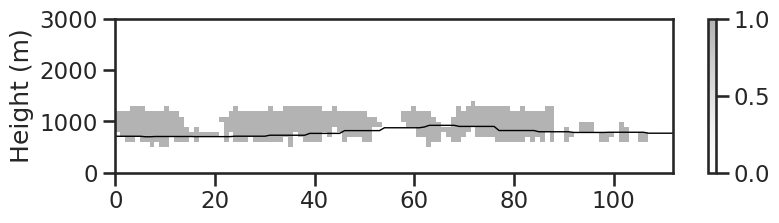

06439E


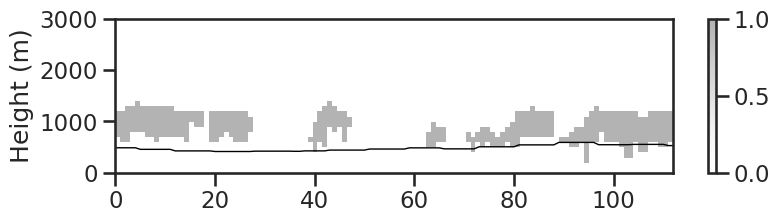

06548E


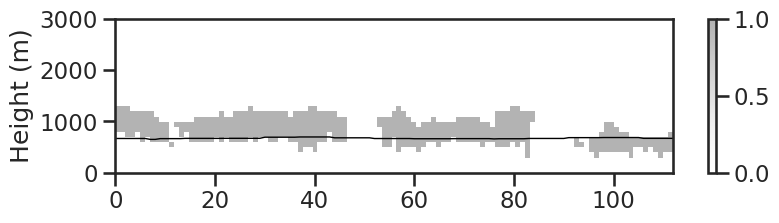

In [325]:
for si in dfcat_sel.scene_id.unique():    
    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    #print(si)
    dfex = dffil[dffil.scene_id == si]
    print(dfex.orbit.values[0])
    if len(dfex) == 112:
        dfex = pd.concat([dfex, pd.DataFrame(dfex.iloc[-1,:]).T]).reset_index(drop=True)
    if len(dfex) != 113:
        print(f'skipping scene {si} with {len(dfex)} points')
        continue
    if dfex.cert.iloc[0] < 0.75:
        print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
        continue
    if (dfex.ocean_mask != 1).all():
        print(f'skipping scene {si} with non-ocean points')
        continue

    profile_cat = add_profile(profile_cat, dfex.cbh_m, dfex.cth_m)

    plt.figure(figsize = (9,2))
    plt.imshow(profile_cat.T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Greys', alpha=0.3)
    plt.plot(dfex.lcl.values, color='black', lw=1, label='LCL')
    plt.colorbar()

    #plt.figure(figsize = (9,2))
    #im = plt.imshow((profile_cat * dfex.lwp.values[:, np.newaxis].astype(np.float32) / dfex.N_cloudy_pixels.values[:, np.newaxis].astype(np.float32)).T, origin='lower', aspect='auto', extent=[0,112,0,3000], 
    #           cmap='viridis', norm=LogNorm(1e-1, 5e2))
    #im = plt.imshow((profile_cat * dfex.lwp.values[:, np.newaxis].astype(np.float32)).T, origin='lower', aspect='auto', extent=[0,112,0,3000], 
    #           cmap='viridis', norm=LogNorm(1e-1, 5e2))
    ax = plt.gca()
    ax.set_ylabel('Height (m)')
    #plt.colorbar(im, label='LWP / g m$^{-2}$', pad=0.2)
    #ax = ax.twinx()
    #ax.plot(dfex.rwp.values, label='RWP', color='red', lw=1)
    #ax.set_ylim(1e-1, 1e2)
    #ax.set_ylabel('RWP (g/m2)', color='red')
    #ax.set_yscale('log')
    plt.show()

In [326]:
def plot_ACMCAP_MCOP_for_scene_id(scene_id):
    orbit = dffil[dffil.scene_id == scene_id].orbit.values[0]
    lat_max = dffil[dffil.scene_id == scene_id].latitude.values.max()
    lat_min = dffil[dffil.scene_id == scene_id].latitude.values.min()

    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/*/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

    # load MCOP
    filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/*/*/*_{orbit}.h5')[0]
    MCOP = ecio.load_MCOP(filename)
    MCOP = MCOP.assign_coords(
        {
        'along_track': (
            ["along_track"],
            MCOP['along_track'].data,
            MCOP['along_track'].attrs
            ),
        'across_track': (
            ['across_track'],
            MCOP['across_track'].data,
            MCOP['across_track'].attrs
            )
        })
    along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
    along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
    MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
    MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

    # plot
    sns.set_context('talk')
    fig, axs = plt.subplots(2,1, figsize=(9,9), gridspec_kw={'height_ratios': [1, 3]})
    ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
    ACMCAP.liquid_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-6, vmax=1e-3, norm=LogNorm(), cmap='chiljet2', cbar_kwargs={'label': 'LWC (kg m$^{-3}$)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    axs[0].set_title(f'{orbit}, lat:{lat_min.round(2)}-{lat_max.round(2)}')

    ax = axs[1]
    MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', vmin=1e-2, vmax=1e0, norm=LogNorm(), add_colorbar=True)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP liquid water path')
    fig.tight_layout()
    plt.show()

07093E


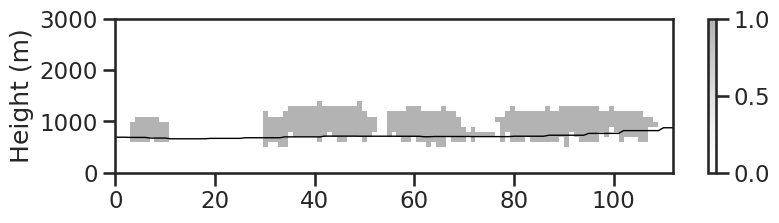

Selecting frame from 9 to 4877
Selecting frame from 444 to 11484


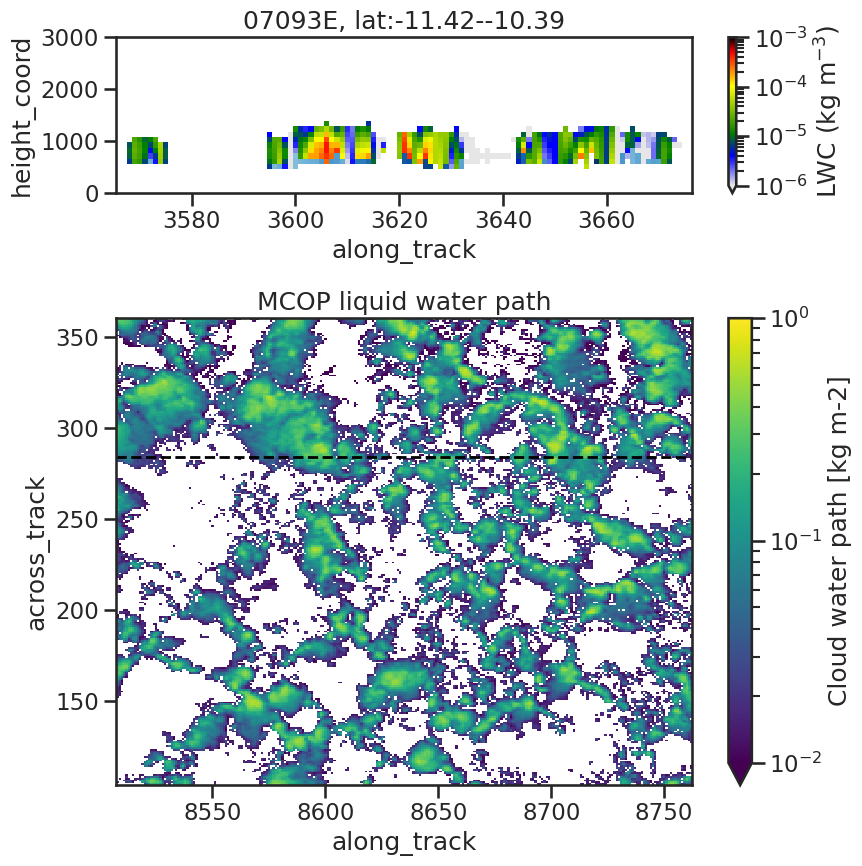

06844E


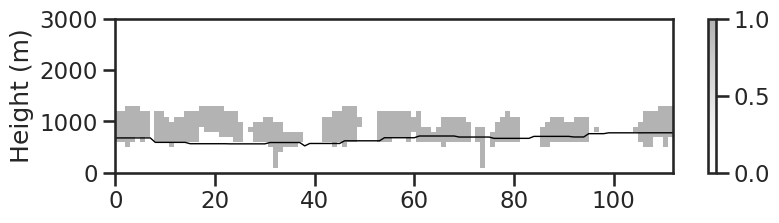

Selecting frame from 10 to 4877
Selecting frame from 440 to 11478


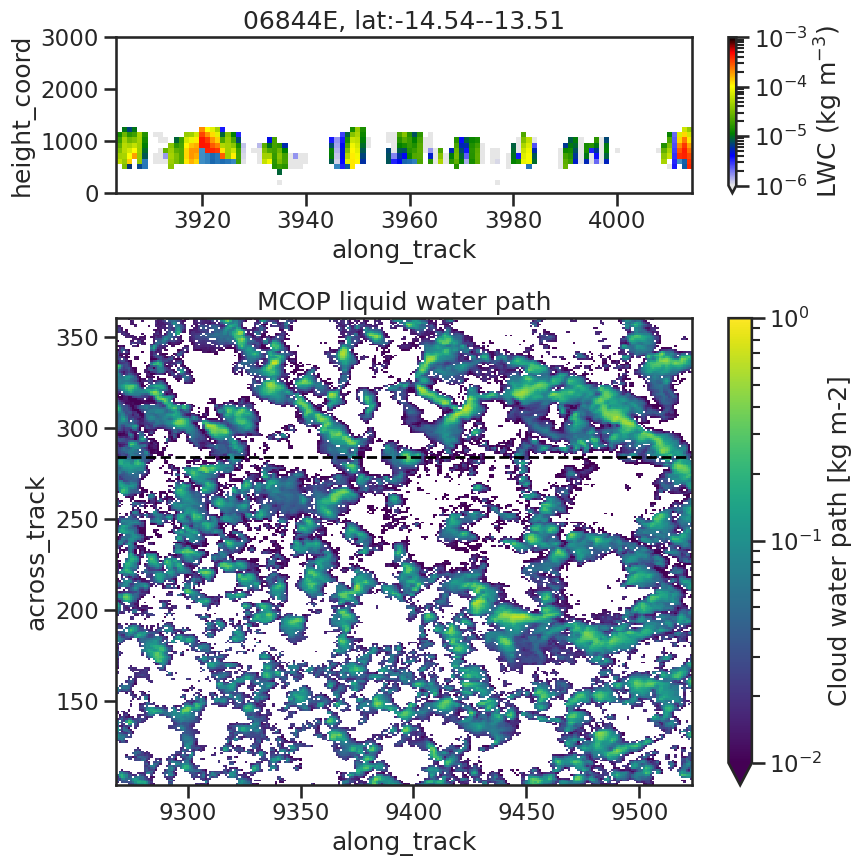

07093E


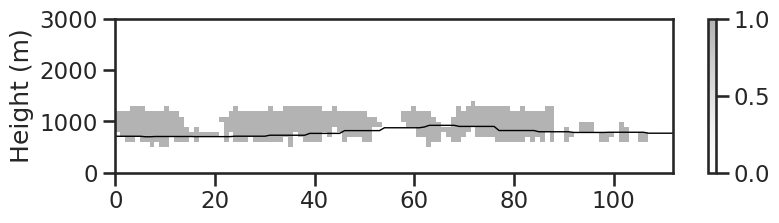

Selecting frame from 9 to 4877
Selecting frame from 444 to 11484


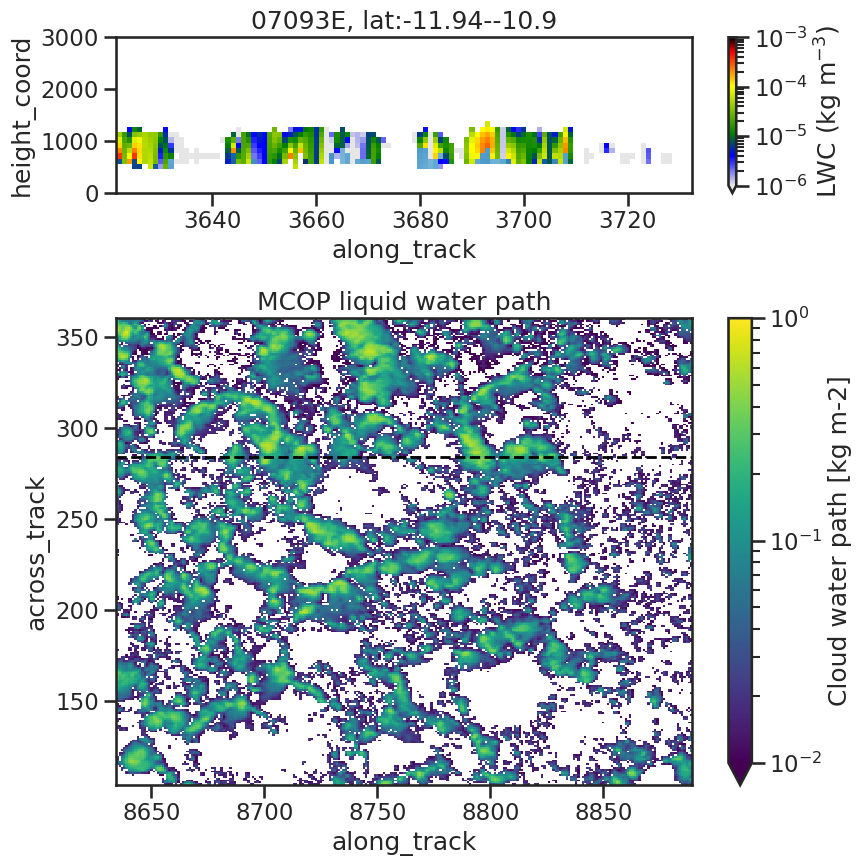

06439E


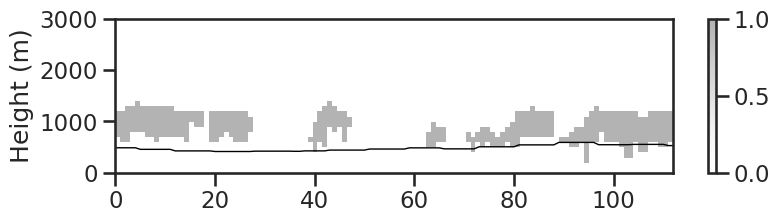

Selecting frame from 7 to 4875
Selecting frame from 433 to 11472


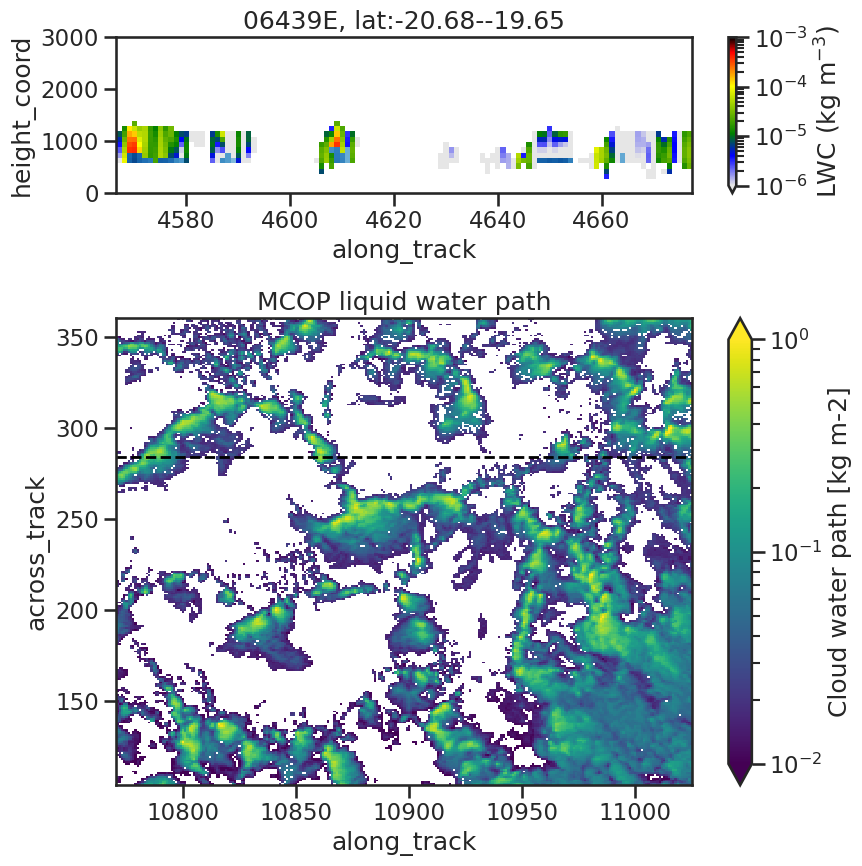

06548E


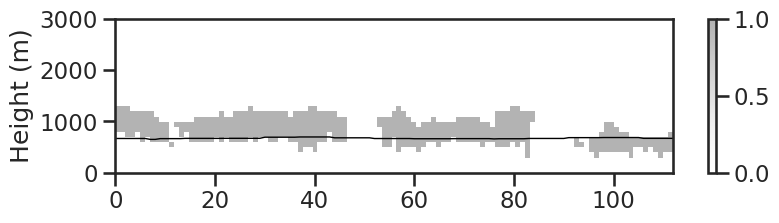

Selecting frame from 6 to 4874
Selecting frame from 431 to 11471


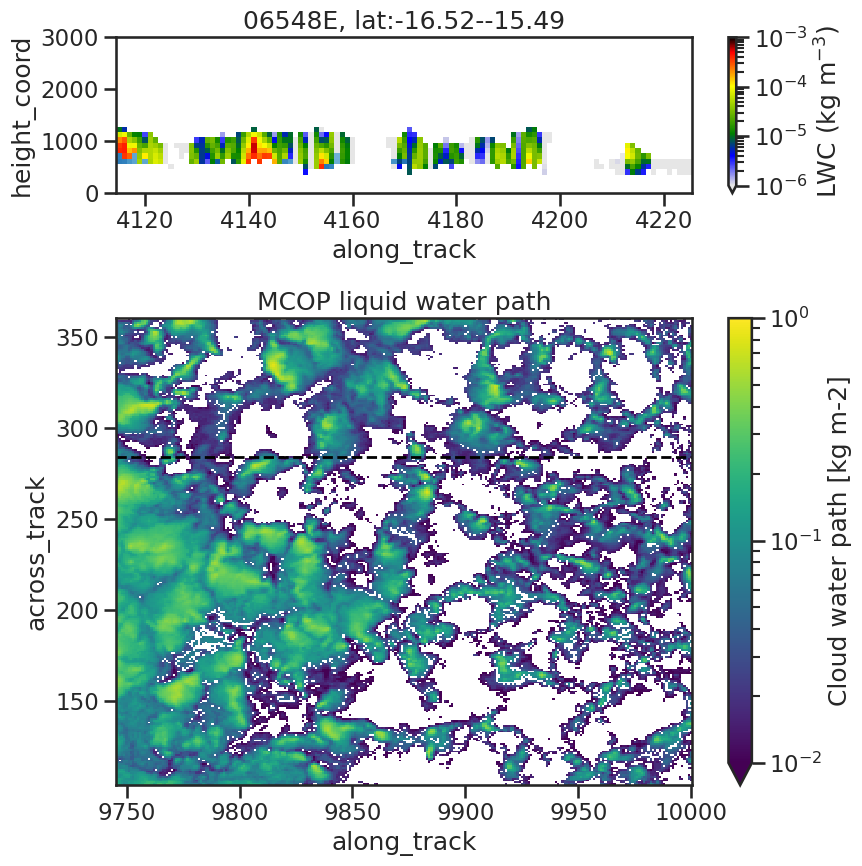

In [327]:
for si in dfcat_sel.scene_id.unique()[0:10]:
    print(dffil[dffil.scene_id == si].orbit.values[0])
    
    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    #print(si)
    dfex = dffil[dffil.scene_id == si]
    if len(dfex) == 112:
        dfex = pd.concat([dfex, pd.DataFrame(dfex.iloc[-1,:]).T]).reset_index(drop=True)
    if len(dfex) != 113:
        print(f'skipping scene {si} with {len(dfex)} points')
        continue
    if dfex.cert.iloc[0] < 0.75:
        print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
        continue
    if (dfex.ocean_mask != 1).all():
        print(f'skipping scene {si} with non-ocean points')
        continue
    profile_cat = add_profile(profile_cat, dfex.cbh_m, dfex.cth_m)
    plt.figure(figsize = (9,2))
    plt.imshow(profile_cat.T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Greys', alpha=0.3)
    plt.plot(dfex.lcl.values, color='black', lw=1, label='LCL')
    plt.colorbar()
    ax = plt.gca()
    ax.set_ylabel('Height (m)')
    plt.show()
    
    plot_ACMCAP_MCOP_for_scene_id(si)

#### archetypal vertical profiles per cat using scipy cdist

In [170]:
import numpy as np
import matplotlib.pyplot as plt

def stack_profiles(df_cat, min_cloud_frac=0.30):
    stacked = []
    for si in df_cat.scene_id.unique():
        dfex = df_cat[df_cat.scene_id == si]
        if len(dfex) != 113 or dfex.cert.iloc[0] < 0.75 or (dfex.ocean_mask != 1).all():
            continue
        # filter out scenes with low cloud fraction
        if (dfex.cbh_m > 0).sum()/113 < min_cloud_frac:
            continue
        arr = np.zeros((113, 20))
        arr = add_profile(arr, dfex.cbh_m, dfex.cth_m)
        stacked.append(arr)
    if len(stacked) == 0:
        print(f"No valid scenes for category {df_cat.cats.iloc[0]}")
        return None
    return np.stack(stacked)

In [148]:
from scipy.spatial.distance import cdist

archetypes = {}
for cat in range(6):
    df_cat = df[df.cats == cat]
    stacked_arr = stack_profiles(df_cat)
    print(f'cat {cat} with {stacked_arr.shape[0]} profiles')

    profiles_flat = stacked_arr.reshape(stacked_arr.shape[0], -1)
    distances = cdist(profiles_flat, profiles_flat)
    medoid_idx = np.argmin(distances.sum(axis=0))
    archetype = stacked_arr[medoid_idx]
    archetypes[cat] = archetype

cat 0 with 331 profiles
cat 1 with 464 profiles
cat 2 with 62 profiles
cat 3 with 164 profiles
cat 4 with 269 profiles
cat 5 with 180 profiles


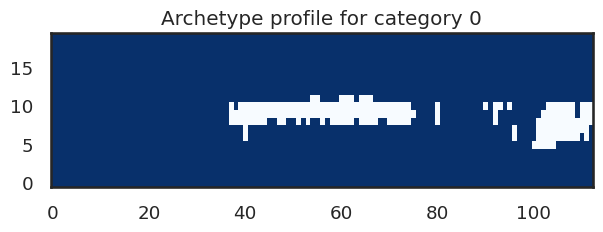

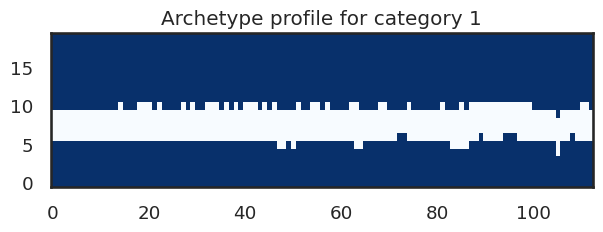

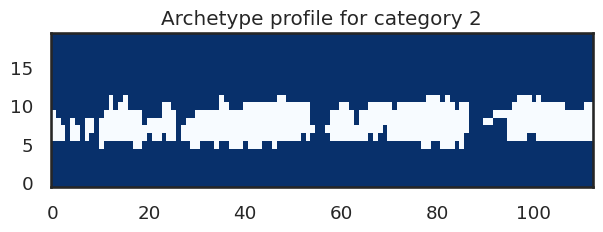

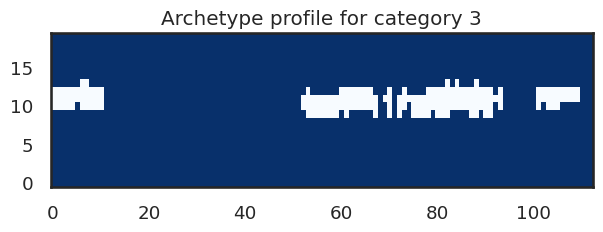

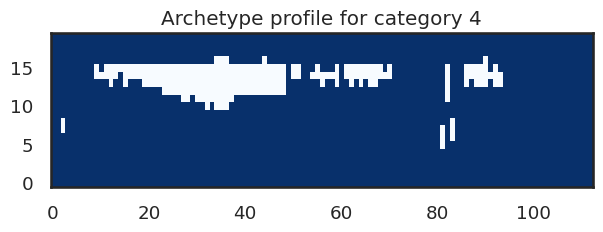

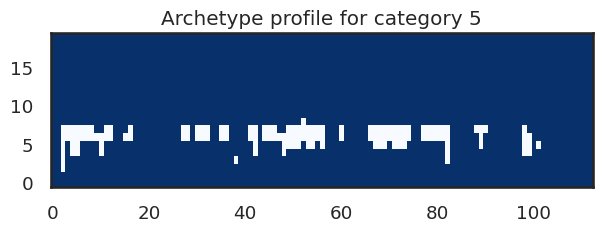

In [149]:
for cat in range(6):
    archetype = archetypes[cat]
    plt.figure(figsize = (7,2))
    plt.imshow(archetype.T, origin='lower', aspect='auto', cmap='Blues_r')
    plt.title('Archetype profile for category {}'.format(cat))
    plt.show()

#### archetypal vertical profiles per cat - using structural similarity

In [166]:
from skimage.metrics import structural_similarity as ssim

archetypes = {}
for cat in range(6):
    df_cat = df[df.cats == cat]
    stacked_arr = stack_profiles(df_cat)
    print(f'cat {cat} with {stacked_arr.shape[0]} profiles')

    def find_highest_avg_ssim(stacked_arr):
        n = stacked_arr.shape[0]
        scores = np.zeros(n)
        for i in range(n):
            ssim_sum = 0
            for j in range(n):
                if i != j:
                    ssim_sum += ssim(stacked_arr[i], stacked_arr[j], data_range=stacked_arr[i].max() - stacked_arr[i].min())
            scores[i] = ssim_sum / (n - 1)
        # three most similar profiles
        similar_indices = np.argsort(scores)[-3:]
        return [scores[similar_indices[0]], scores[similar_indices[1]], scores[similar_indices[2]]], similar_indices, [stacked_arr[similar_indices[0]], stacked_arr[similar_indices[1]], stacked_arr[similar_indices[2]]]

    # Example usage:
    # stacked_arr = stack_profiles(df_cat)
    scores, similar_indices, images = find_highest_avg_ssim(stacked_arr)
    print(f'Highest average SSIM scores for category {cat}: {scores}')
    archetypes[cat] = {'scores': scores, 'indices': similar_indices, 'images': images}

cat 0 with 331 profiles
Highest average SSIM scores for category 0: [np.float64(0.26525491291097786), np.float64(0.26743263011790347), np.float64(0.27009421533427785)]
cat 1 with 464 profiles
Highest average SSIM scores for category 1: [np.float64(0.3768588227026237), np.float64(0.37724533947146865), np.float64(0.38561056039730207)]
cat 2 with 62 profiles
Highest average SSIM scores for category 2: [np.float64(0.27269445318469787), np.float64(0.2750373860776324), np.float64(0.27609330378942787)]
cat 3 with 164 profiles
Highest average SSIM scores for category 3: [np.float64(0.2516007546044766), np.float64(0.25356911930262266), np.float64(0.2587042694948273)]
cat 4 with 269 profiles
Highest average SSIM scores for category 4: [np.float64(0.20765556387380033), np.float64(0.21376731481257538), np.float64(0.21486342191143554)]
cat 5 with 180 profiles
Highest average SSIM scores for category 5: [np.float64(0.3170523747991695), np.float64(0.3199946802041883), np.float64(0.32147808342532336)]

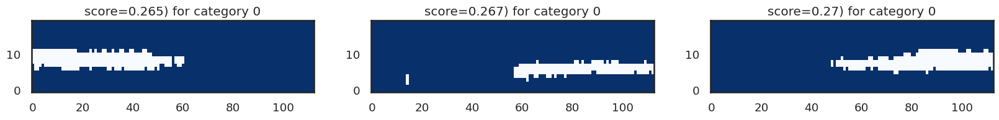

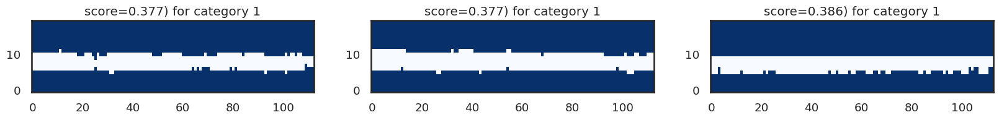

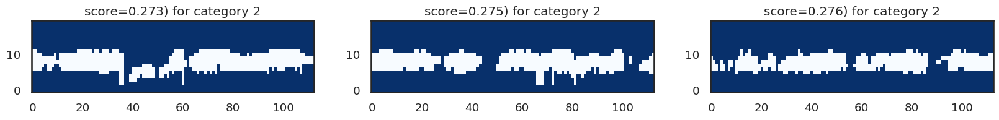

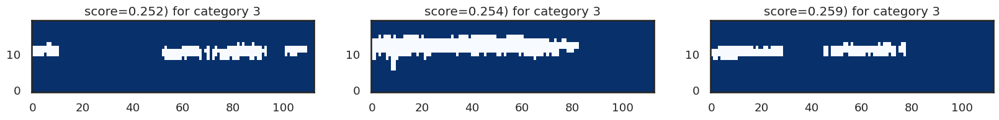

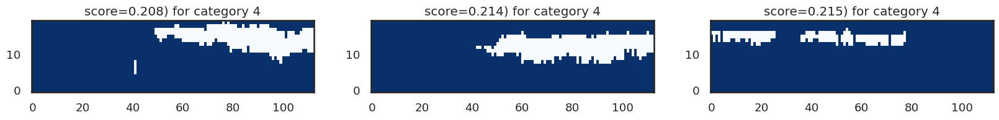

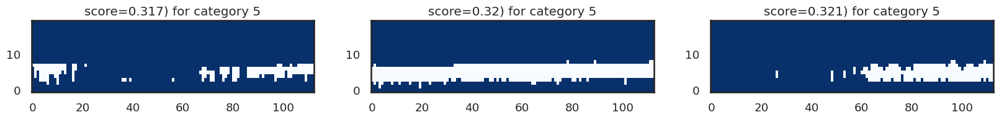

In [168]:
for cat in range(6):
    fig, axs = plt.subplots(1, 3, figsize = (20,1.5))
    imgs = archetypes[cat]['images']
    scores = archetypes[cat]['scores']
    for i, img in enumerate(imgs):
        axs[i].imshow(img.T, origin='lower', aspect='auto', cmap='Blues_r')
        axs[i].set_title(f'score={scores[i].round(3)}) for category {cat}')
    plt.show()

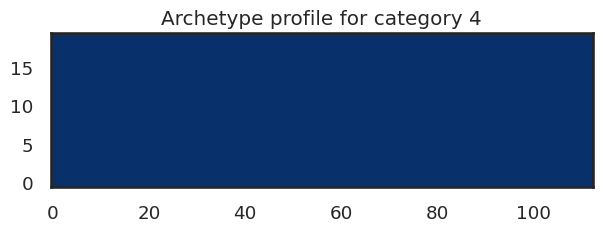

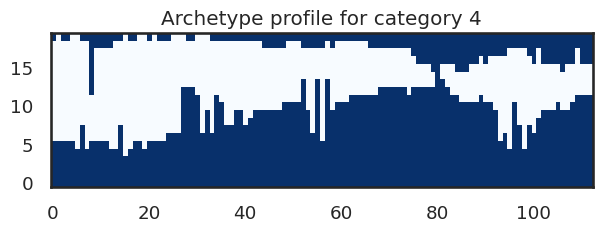

0.16311717953754426


In [ ]:
i = 166
j = 4

plt.figure(figsize = (7,2))
plt.imshow(stacked_arr[i].T, origin='lower', aspect='auto', cmap='Blues_r')
plt.title('Archetype profile for category {}'.format(cat))
plt.show()
plt.figure(figsize = (7,2))
plt.imshow(stacked_arr[j].T, origin='lower', aspect='auto', cmap='Blues_r')
plt.title('Archetype profile for category {}'.format(cat))
plt.show()

score = ssim(stacked_arr[i], stacked_arr[j], data_range=1)
print(score)

---
PROBLEM: I think for both cdist and structural similarity the algorithms put too much emphasize on clear sky pixels. Because there are always more clear sky pixels than cloudy pixels, the distance/similarity is dominated by clear sky pixels, and scenes that are mostly clear are seen as the most similar ones.

### categorize vertical profiles using KMeans

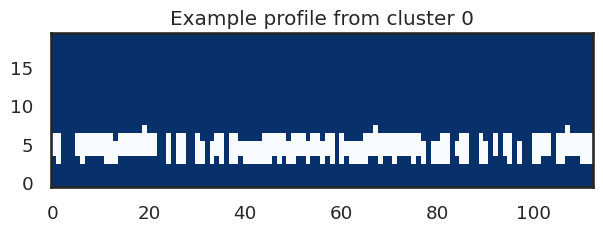

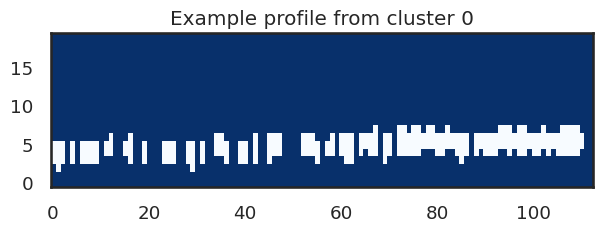

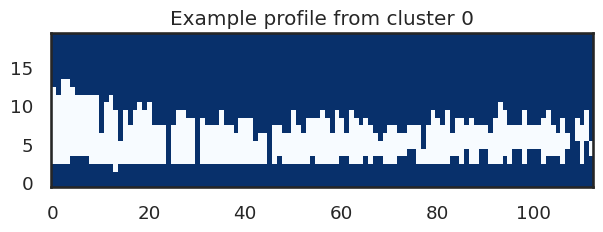

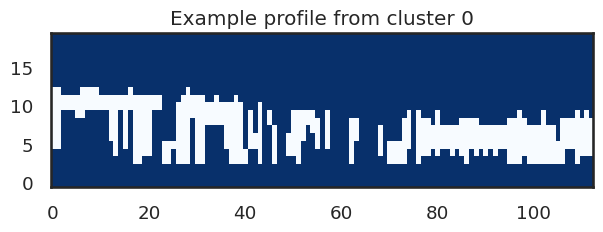

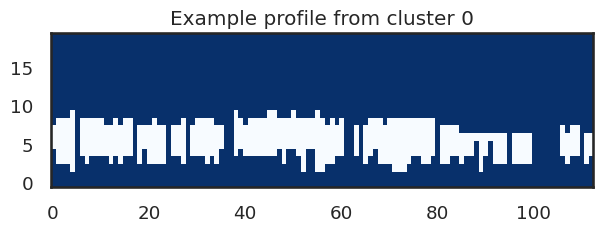

...

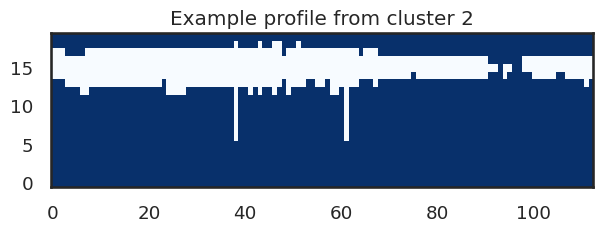

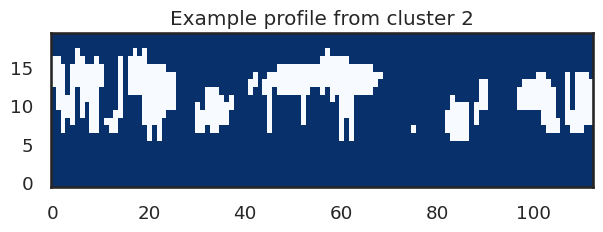

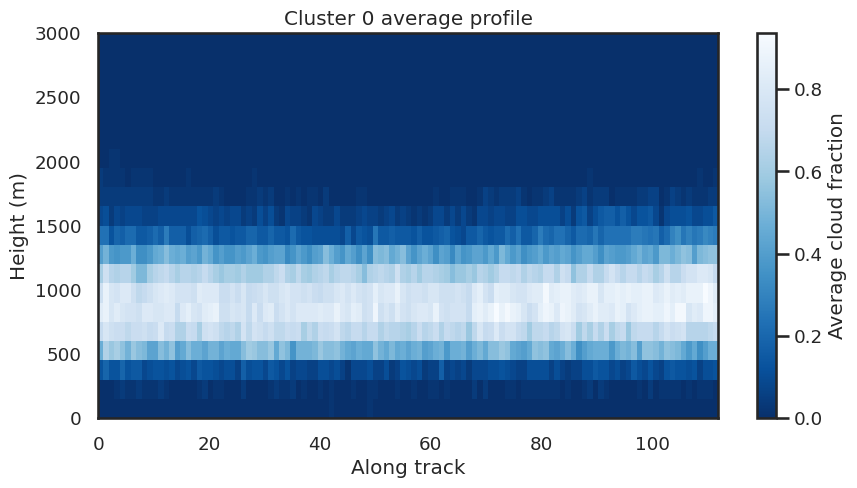

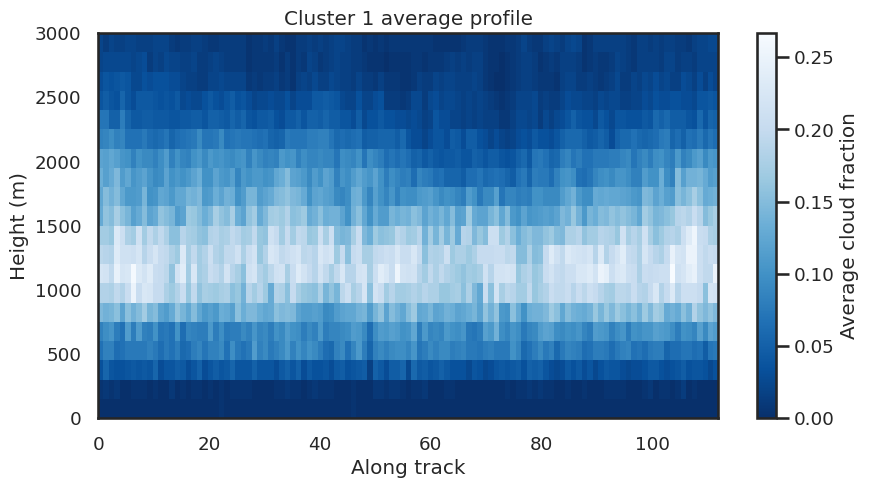

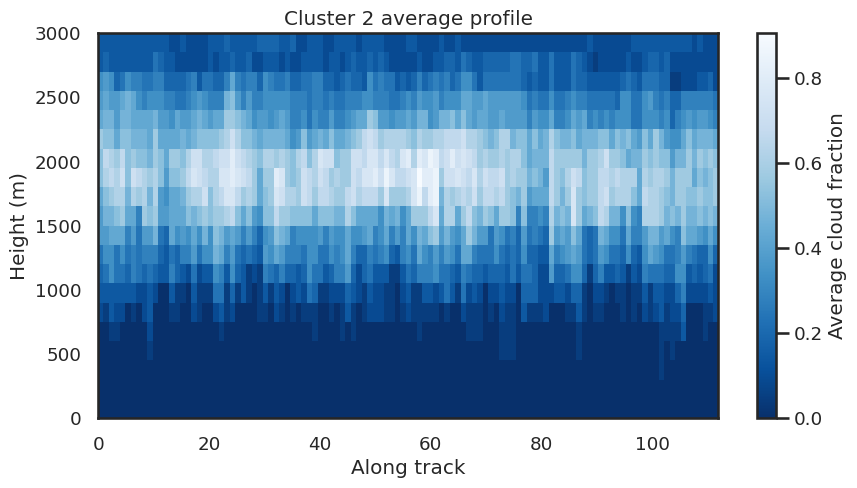

In [173]:
from sklearn.cluster import KMeans

def cluster_and_average_profiles(stacked_arr, n_clusters=3, plot_examples=True):
    # Flatten each profile for clustering
    n_scenes = stacked_arr.shape[0]
    profiles_flat = stacked_arr.reshape(n_scenes, -1)
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(profiles_flat)
    labels = kmeans.labels_
    avg_profiles = []
    for i in range(n_clusters):
        cluster_profiles = stacked_arr[labels == i]
        avg_profiles.append(cluster_profiles.mean(axis=0))
        if plot_examples:
            for j in range(min(5, cluster_profiles.shape[0])):
                plt.figure(figsize = (7,2))
                plt.imshow(cluster_profiles[j].T, origin='lower', aspect='auto', cmap='Blues_r')
                plt.title(f'Example profile from cluster {i}')
                plt.show()
    return avg_profiles, labels

# Example usage:
cat = 5
df_cat = df[df.cats == cat]
stacked_arr = stack_profiles(df_cat)
avg_profiles, labels = cluster_and_average_profiles(stacked_arr, n_clusters=3)

# Plot average profile for each cluster
for i, avg_profile in enumerate(avg_profiles):
    plt.figure(figsize=(10,5))
    plt.imshow(avg_profile.T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Blues_r')
    plt.colorbar(label='Average cloud fraction')
    plt.xlabel('Along track')
    plt.ylabel('Height (m)')
    plt.title(f'Cluster {i} average profile')
    plt.show()

--> doesnt work very well

### categorize vertical profiles using CASSCCAD

#### compute needed variables

In [35]:
dffil = df1

In [36]:
dffil['cloud_mask'] = dffil['lwp'] > 0

In [37]:
# horizontal cloud fraction on several scales
length_scales = [10,20,40,80]
for scale in length_scales:
    dffil[f'HCF_c_{scale}'] = dffil.groupby('orbit')['cloud_mask'].transform(lambda x: x.rolling(window=scale, center=True, min_periods=1).mean())
    dffil[f'HCF_f_{scale}'] = dffil.groupby('orbit')['cloud_mask'].transform(lambda x: x.rolling(window=scale, center=False, min_periods=1).mean())
    dffil[f'HCF_b_{scale}'] = dffil.groupby('orbit')['cloud_mask'].transform(lambda x: x[::-1].rolling(window=scale, center=False, min_periods=1).mean()[::-1])

In [38]:
# vertical cloud fraction
dffil['N_mean_80'] = dffil.groupby('orbit')['N_cloudy_pixels'].transform(lambda x: x.rolling(window=80, center=True, min_periods=1).mean())
dffil['N_std_80'] = dffil.groupby('orbit')['N_cloudy_pixels'].transform(lambda x: x.rolling(window=80, center=True, min_periods=1).std())

#### plot variables for algorithm

<Axes: ylabel='Frequency'>

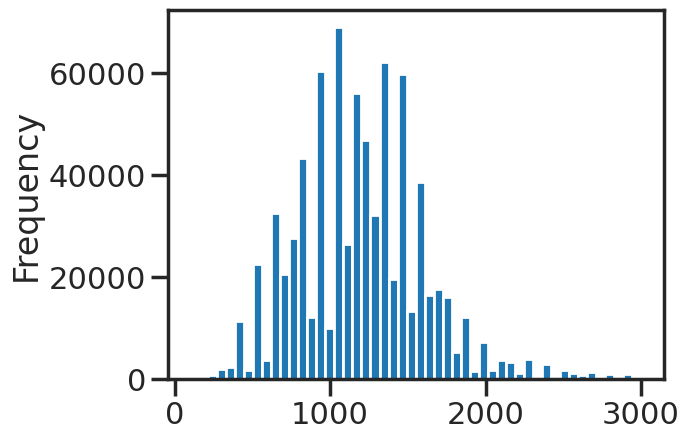

In [39]:
dffil.cth_m.plot.hist(bins=50)

In [40]:
dffil.HCF_c_80

0         0.925000
1         0.926829
2         0.928571
3         0.930233
4         0.931818
            ...   
452588    0.955556
452589    0.954545
452590    0.953488
452591    0.952381
452592    0.951220
Name: HCF_c_80, Length: 1118800, dtype: float64

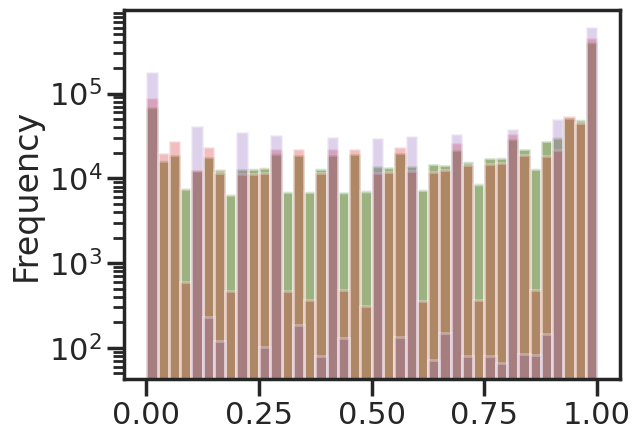

In [41]:
dffil.HCF_c_80.plot.hist(bins=40, alpha=0.3)
dffil.HCF_f_80.plot.hist(bins=40, alpha=0.3)
dffil.HCF_b_80.plot.hist(bins=40, alpha=0.3)
dffil.HCF_c_40.plot.hist(bins=40, alpha=0.3)
dffil.HCF_c_10.plot.hist(bins=40, alpha=0.3)
plt.yscale('log')

<Axes: ylabel='Frequency'>

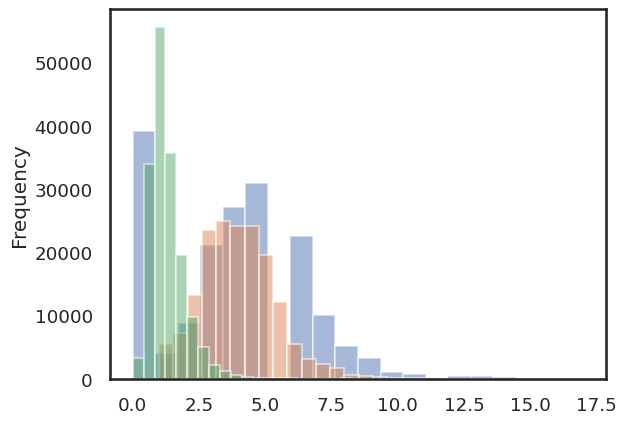

In [114]:
dffil.N_high_cc.plot.hist(bins=20, alpha=0.5)
dffil.N_mean_80.plot.hist(bins=20, alpha=0.5)
dffil.N_std_80.plot.hist(bins=20, alpha=0.5)

<Axes: xlabel='N_mean_80', ylabel='N_std_80'>

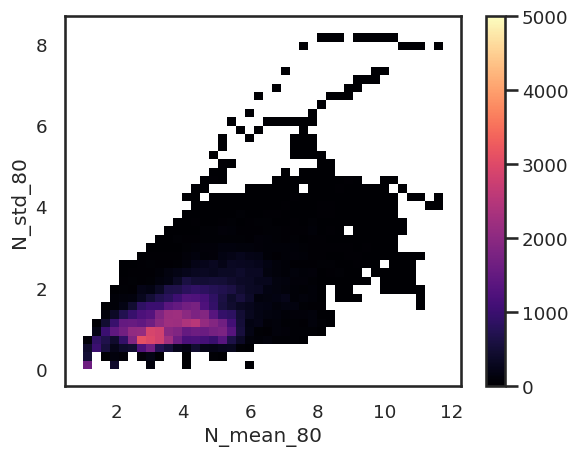

In [115]:
# joint histogram
sns.histplot(data=dffil, x="N_mean_80", y="N_std_80", bins=40, cbar=True, vmax=5000, cmap='magma')

#### classification

In [320]:
# Sc :              0
# broken Sc :       1
# Cu under Sc :     2
# Cu w. Sc outflow: 3
# Cu :              4

In [42]:
cth_test = (dffil['cth_m'] > 2000) & (dffil['N_mean_80'] > 5) # added condition that N_mean_80 > 5 to original logic
# I find that 2000 is a bit low in examples... 

In [43]:
HCF_test_1 = (dffil['HCF_c_10'] > 0.75) & (dffil['HCF_c_20'] > 0.7) & (dffil['HCF_c_40'] > 0.6) & (dffil['HCF_c_80'] > 0.5)
HCF_test_2 = (dffil['HCF_f_10'] > 0.75) & (dffil['HCF_f_20'] > 0.7) & (dffil['HCF_f_40'] > 0.6) & (dffil['HCF_f_80'] > 0.5)
HCF_test_3 = (dffil['HCF_b_10'] > 0.75) & (dffil['HCF_b_20'] > 0.7) & (dffil['HCF_b_40'] > 0.6) & (dffil['HCF_b_80'] > 0.5)
HCF_test_4 = (dffil['HCF_c_40'] > 0.6) | (dffil['HCF_c_80'] > 0.5) | (dffil['HCF_f_40'] > 0.6) | (dffil['HCF_f_80'] > 0.5) | (dffil['HCF_b_40'] > 0.6) | (dffil['HCF_b_80'] > 0.5)

In [44]:
VCF_test = (dffil['N_mean_80'] > 5) & (dffil['N_std_80'] > 1.7)
#VCF_test = (dffil['N_high_cc'] >= 7) & (dffil['N_std_80'] > 1.7)

In [45]:
# version 1
dffil['label'] = -1
dffil['label'] = np.where(cth_test, 4, dffil['label'])
dffil['label'] = np.where((~cth_test) & HCF_test_1 & VCF_test, 2, dffil['label'])
dffil['label'] = np.where((~cth_test) & HCF_test_1 & (~VCF_test), 0, dffil['label'])
dffil['label'] = np.where((~cth_test) & (~HCF_test_1) & (HCF_test_2 | HCF_test_3) & VCF_test, 2, dffil['label'])
dffil['label'] = np.where((~cth_test) & (~HCF_test_1) & (HCF_test_2 | HCF_test_3) & (~VCF_test), 0, dffil['label'])
dffil['label'] = np.where((~cth_test) & (~HCF_test_1) & (~HCF_test_2) & (~HCF_test_3) & HCF_test_4 & VCF_test, 2, dffil['label'])
dffil['label'] = np.where((~cth_test) & (~HCF_test_1) & (~HCF_test_2) & (~HCF_test_3) & HCF_test_4 & (~VCF_test), 1, dffil['label'])
dffil['label'] = np.where((~cth_test) & (~HCF_test_1) & (~HCF_test_2) & (~HCF_test_3) & (~HCF_test_4), 4, dffil['label'])

In [46]:
dffil.label

0         0
1         0
2         0
3         0
4         0
         ..
452588    2
452589    2
452590    2
452591    2
452592    2
Name: label, Length: 1118800, dtype: int64

#### analysis of classified profiles

In [47]:
# Sc :              0
# broken Sc :       1
# Cu under Sc :     2
# Cu w. Sc outflow: 3
# Cu :              4

<Axes: xlabel='label', ylabel='Count'>

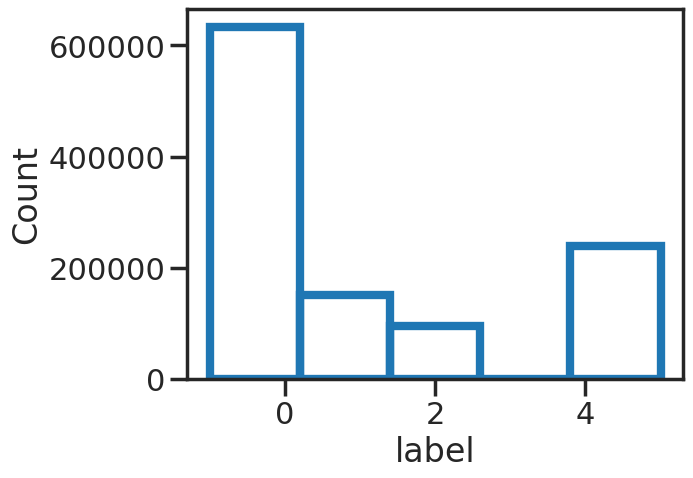

In [48]:
sns.histplot(data=dffil, x='label', bins=np.linspace(-1,5,6), element='bars', fill=False, stat='count', lw=4)

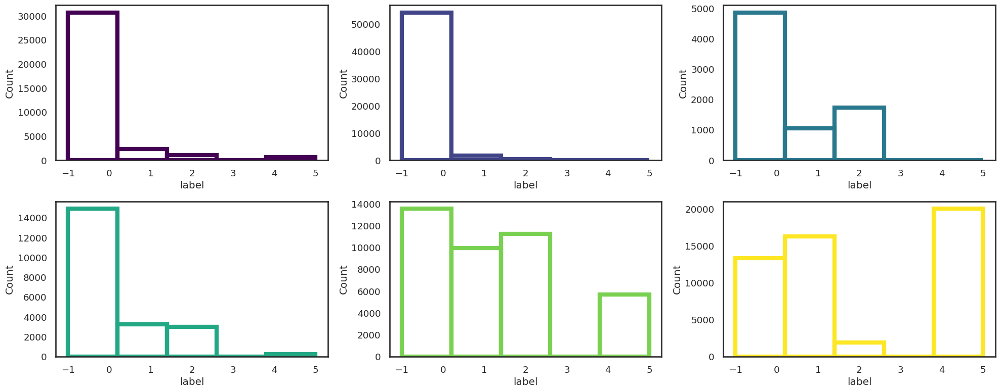

In [63]:
fig, axs = plt.subplots(2,3, figsize=(20, 8))
for i in [0,1,2,3,4,5]:
    sns.histplot(ax=axs.flatten()[i], data=dffil[dffil[cloud_regime] == i], x='label', bins=np.linspace(-1,5,6), element='bars', fill=False, stat='count', label=f'cluster {i}', color=catcolors[i], lw=4)
fig.tight_layout()

## Vertical structure of LWC and rain

In [ ]:
# only use profiles that contain clouds, and where lwp error is less than 0.25
valid_lwp_mask = (dffil.lwp_error <= 0.25)

In [ ]:
def left_align_non_nan(arr):
    """Shift non-NaN values in each row to the left end."""
    result = np.full_like(arr, np.nan)
    for i, row in enumerate(arr):
        valid = row[~np.isnan(row)]
        result[i, :len(valid)] = valid
    return result

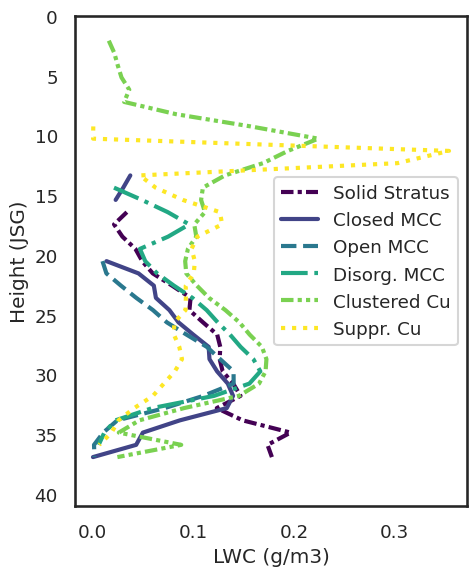

In [135]:
avg_profiles_1d = {}

dffil_valid_lwp = dffil[valid_lwp_mask]

for cat in range(6):
    dffil_cat = dffil_valid_lwp[dffil_valid_lwp.cats == cat]
    lwc_2d = np.stack(dffil_cat.lwc_profile.values)
    lwc_2d = np.where(lwc_2d == 0, np.nan, lwc_2d)
    lwc_2d = lwc_2d * 1e3 # convert to g/m3

    avg_profiles_1d[cat] = np.nanmean(lwc_2d, axis=0)

plt.figure(figsize=(5,6))
for cat in range(6):
    profile_cat = avg_profiles_1d[cat]
    h = len(profile_cat)
    plt.plot(profile_cat, np.linspace(0,h,h), color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
plt.xlabel('LWC (g/m3)')
plt.ylabel('Height (JSG)')
plt.ylim(h,0)
plt.legend()
plt.tight_layout()
plt.show()

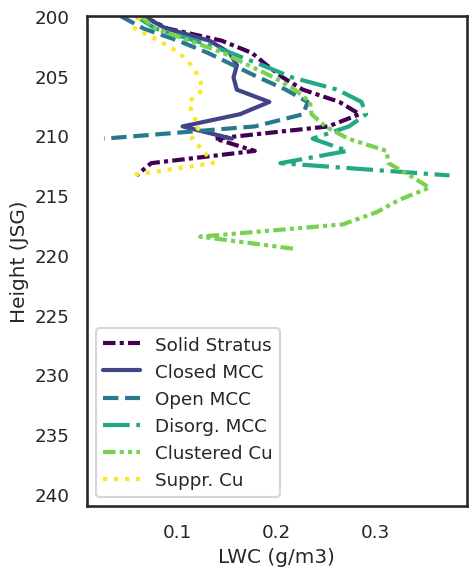

In [ ]:
avg_profiles_1d_normed_cth = {}

dffil_valid_lwp = dffil[valid_lwp_mask]

for cat in range(6):
    dffil_cat = dffil_valid_lwp[dffil_valid_lwp.cats == cat]
    lwc_2d = np.stack(dffil_cat.lwc_profile.values)
    lwc_2d = np.where(lwc_2d == 0, np.nan, lwc_2d)
    lwc_2d = lwc_2d * 1e3 # convert to g/m3

    lwc_2d_aligned = left_align_non_nan(lwc_2d)

    avg_profiles_1d_normed_cth[cat] = np.nanmean(lwc_2d_aligned, axis=0)

plt.figure(figsize=(5,6))
for cat in range(6):
    profile_cat = avg_profiles_1d_normed_cth[cat]
    h = len(profile_cat)
    plt.plot(profile_cat, np.linspace(0,h,h) + 200, color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
plt.xlabel('LWC (g/m3)')
plt.ylabel('Height (JSG)')
plt.ylim(h + 200,200)
plt.legend()
plt.tight_layout()
plt.show()

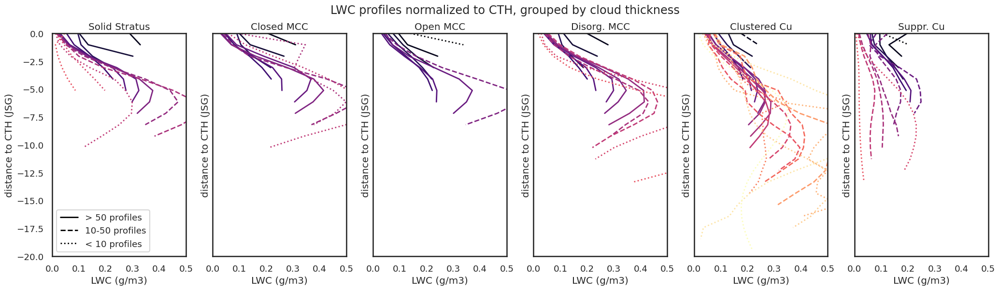

In [227]:
profiles_normed_cth_1d = {}
number_of_profiles = {}

dffil_valid_lwp = dffil[valid_lwp_mask]

for cat in range(6):
    dffil_cat = dffil_valid_lwp[dffil_valid_lwp.cats == cat]

    quantiles = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

    thickness = dffil_cat.cth_m - dffil_cat.cbh_m
    quantile_vals = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 
                     1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000]

    for i in range(1, len(quantile_vals)):
        dffil_cat_i = dffil_cat[(thickness >= quantile_vals[i-1]) & (thickness < quantile_vals[i])]
        if len(dffil_cat_i) == 0:
            continue

        lwc_2d = np.stack(dffil_cat_i.lwc_profile.values)
        lwc_2d = np.where(lwc_2d == 0, np.nan, lwc_2d)
        lwc_2d = lwc_2d * 1e3 # convert to g/m3

        lwc_2d_aligned = left_align_non_nan(lwc_2d)
        number_of_profiles_cat_i = lwc_2d_aligned.shape[0]

        avg_profile_cat_i = np.nanmean(lwc_2d_aligned, axis=0)

        if cat not in profiles_normed_cth_1d:
            profiles_normed_cth_1d[cat] = avg_profile_cat_i
            number_of_profiles[cat] = number_of_profiles_cat_i
        else:
            profiles_normed_cth_1d[cat] = np.vstack((profiles_normed_cth_1d[cat], avg_profile_cat_i))
            number_of_profiles[cat] = np.vstack((number_of_profiles[cat], number_of_profiles_cat_i))

fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(25,6), sharey=True)
plt.suptitle('LWC profiles normalized to CTH, grouped by cloud thickness')
color_thickness = plt.cm.magma(np.linspace(0,1,len(quantile_vals)-1))
for cat in range(6):
    profile_cat = profiles_normed_cth_1d[cat]
    for i in range(profile_cat.shape[0]):
        if number_of_profiles[cat][i] < 10:
            linestyle = 'dotted'
        elif number_of_profiles[cat][i] < 50:
            linestyle = 'dashed'
        else:
            linestyle = 'solid'
        h = len(profile_cat[i])
        axs[cat].plot(profile_cat[i], np.linspace(0,-h,h), color=color_thickness[i], lw=2, linestyle=linestyle)
    avg_profile_cat = avg_profiles_1d_normed_cth[cat]
    #axs[cat].plot(avg_profile_cat, np.linspace(0,h,h) + 200, color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
    axs[cat].set_xlabel('LWC (g/m3)')
    axs[cat].set_ylabel('distance to CTH (JSG)')
    axs[cat].set_title(cats_names[cat])
    axs[cat].set_ylim(-20,0)
    axs[cat].set_xlim(0,0.5)
legend_elements_lwc_profile = [Line2D([0], [0], color='black', lw=2, label='> 50 profiles', linestyle='solid'),
                   Line2D([0], [0], color='black', lw=2, label='10-50 profiles', linestyle='dashed'),
                   Line2D([0], [0], color='black', lw=2, label='< 10 profiles', linestyle='dotted')]
axs[0].legend(handles=legend_elements_lwc_profile)

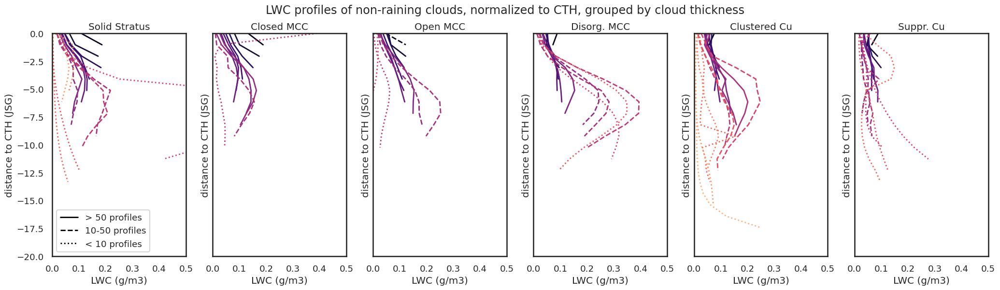

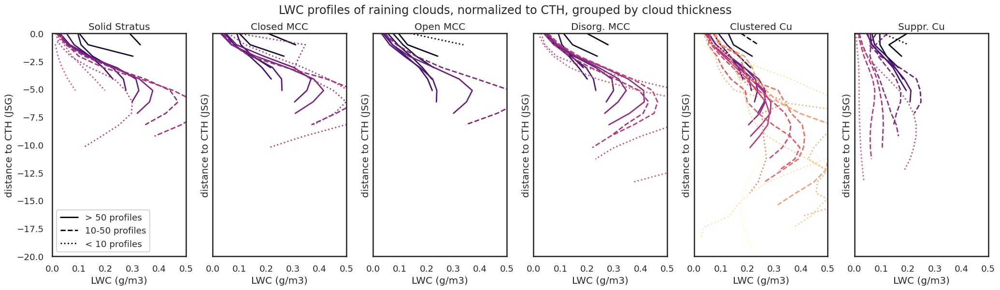

In [228]:


#BA_start = pd.to_datetime('2025-07-09') & (pd.to_datetime(dffil.time) >= BA_start)

for raining in [0,1]:
    if raining == 0:
        valid_lwp_mask = (dffil.lwp_error <= 0.25) & (dffil.rain_rate_subcloud == 0)
    else:
        valid_lwp_mask = (dffil.lwp_error <= 0.25) & (dffil.rain_rate_subcloud > 0)

    profiles_normed_cth_1d = {}
    number_of_profiles = {}
    dffil_valid_lwp = dffil[valid_lwp_mask ]

    for cat in range(6):
        dffil_cat = dffil_valid_lwp[dffil_valid_lwp.cats == cat]

        quantiles = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

        thickness = dffil_cat.cth_m - dffil_cat.cbh_m
        quantile_vals = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 
                        1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000]

        for i in range(1, len(quantile_vals)):
            dffil_cat_i = dffil_cat[(thickness >= quantile_vals[i-1]) & (thickness < quantile_vals[i])]
            if len(dffil_cat_i) == 0:
                continue

            lwc_2d = np.stack(dffil_cat_i.lwc_profile.values)
            lwc_2d = np.where(lwc_2d == 0, np.nan, lwc_2d)
            lwc_2d = lwc_2d * 1e3 # convert to g/m3

            lwc_2d_aligned = left_align_non_nan(lwc_2d)
            number_of_profiles_cat_i = lwc_2d_aligned.shape[0]

            avg_profile_cat_i = np.nanmean(lwc_2d_aligned, axis=0)

            if cat not in profiles_normed_cth_1d:
                profiles_normed_cth_1d[cat] = avg_profile_cat_i
                number_of_profiles[cat] = number_of_profiles_cat_i
            else:
                profiles_normed_cth_1d[cat] = np.vstack((profiles_normed_cth_1d[cat], avg_profile_cat_i))
                number_of_profiles[cat] = np.vstack((number_of_profiles[cat], number_of_profiles_cat_i))

    fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(25,6), sharey=True)
    if raining == 0:
        plt.suptitle('LWC profiles of non-raining clouds, normalized to CTH, grouped by cloud thickness')
    else:
        plt.suptitle('LWC profiles of raining clouds, normalized to CTH, grouped by cloud thickness')
    color_thickness = plt.cm.magma(np.linspace(0,1,len(quantile_vals)-1))
    for cat in range(6):
        profile_cat = profiles_normed_cth_1d[cat]
        for i in range(profile_cat.shape[0]):
            if number_of_profiles[cat][i] < 10:
                linestyle = 'dotted'
            elif number_of_profiles[cat][i] < 50:
                linestyle = 'dashed'
            else:
                linestyle = 'solid'
            h = len(profile_cat[i])
            axs[cat].plot(profile_cat[i], np.linspace(0,-h,h), color=color_thickness[i], lw=2, linestyle=linestyle)
        axs[cat].set_xlabel('LWC (g/m3)')
        axs[cat].set_ylabel('distance to CTH (JSG)')
        axs[cat].set_title(cats_names[cat])
        axs[cat].set_ylim(-20,0)
        axs[cat].set_xlim(0,0.5)

    legend_elements_lwc_profile = [Line2D([0], [0], color='black', lw=2, label='> 50 profiles', linestyle='solid'),
                    Line2D([0], [0], color='black', lw=2, label='10-50 profiles', linestyle='dashed'),
                    Line2D([0], [0], color='black', lw=2, label='< 10 profiles', linestyle='dotted')]
    axs[0].legend(handles=legend_elements_lwc_profile)
    plt.show()

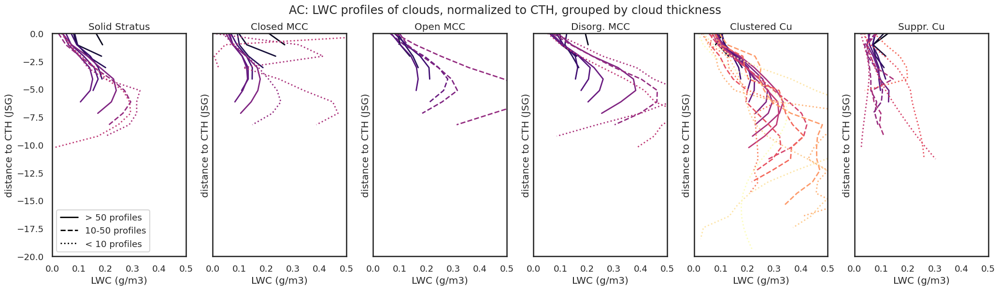

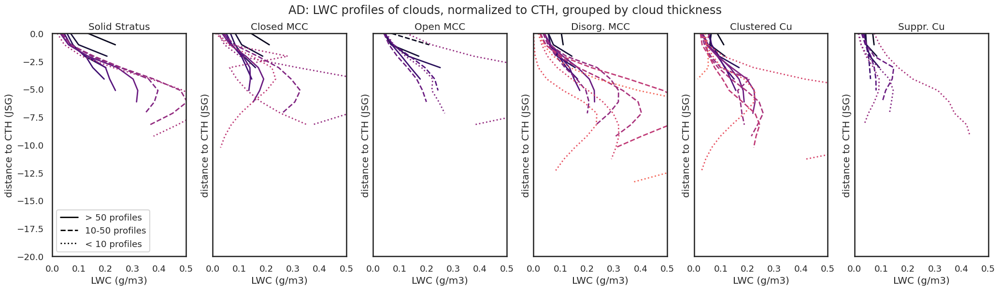

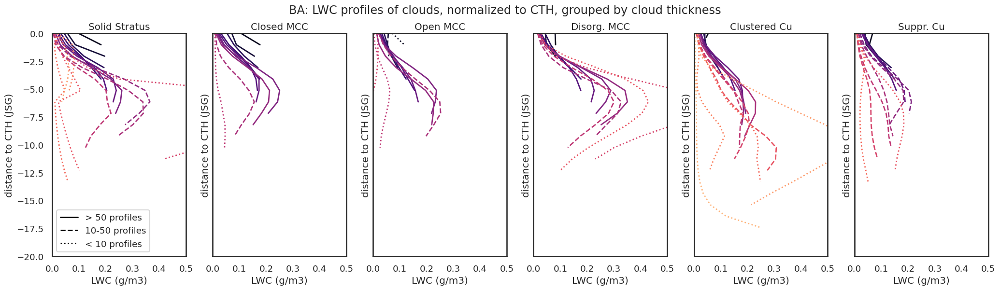

In [ ]:
AB_end = pd.to_datetime('2025-05-08')
AC_start = pd.to_datetime('2025-05-09')
AC_end = pd.to_datetime('2025-06-11')
AD_start = pd.to_datetime('2025-06-13')
AD_end = pd.to_datetime('2025-07-07')
BA_start = pd.to_datetime('2025-07-09')


for baseline in ['AC', 'AD', 'BA']:
    if baseline == 'AC':
        valid_lwp_mask = (dffil.lwp_error <= 0.25) & (pd.to_datetime(dffil.time) >= AC_start) & (pd.to_datetime(dffil.time) <= AC_end)
    elif baseline == 'AD':
        valid_lwp_mask = (dffil.lwp_error <= 0.25) & (pd.to_datetime(dffil.time) >= AD_start) & (pd.to_datetime(dffil.time) <= AD_end)
    else:
        valid_lwp_mask = (dffil.lwp_error <= 0.25) & (pd.to_datetime(dffil.time) >= BA_start)

    profiles_normed_cth_1d = {}
    number_of_profiles = {}
    dffil_valid_lwp = dffil[valid_lwp_mask ]

    for cat in range(6):
        dffil_cat = dffil_valid_lwp[dffil_valid_lwp.cats == cat]

        quantiles = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

        thickness = dffil_cat.cth_m - dffil_cat.cbh_m
        quantile_vals = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 
                        1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000]

        for i in range(1, len(quantile_vals)):
            dffil_cat_i = dffil_cat[(thickness >= quantile_vals[i-1]) & (thickness < quantile_vals[i])]
            if len(dffil_cat_i) == 0:
                continue

            lwc_2d = np.stack(dffil_cat_i.lwc_profile.values)
            lwc_2d = np.where(lwc_2d == 0, np.nan, lwc_2d)
            lwc_2d = lwc_2d * 1e3 # convert to g/m3

            lwc_2d_aligned = left_align_non_nan(lwc_2d)
            number_of_profiles_cat_i = lwc_2d_aligned.shape[0]

            avg_profile_cat_i = np.nanmean(lwc_2d_aligned, axis=0)

            if cat not in profiles_normed_cth_1d:
                profiles_normed_cth_1d[cat] = avg_profile_cat_i
                number_of_profiles[cat] = number_of_profiles_cat_i
            else:
                profiles_normed_cth_1d[cat] = np.vstack((profiles_normed_cth_1d[cat], avg_profile_cat_i))
                number_of_profiles[cat] = np.vstack((number_of_profiles[cat], number_of_profiles_cat_i))

    fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(25,6), sharey=True)
    plt.suptitle(f'{baseline}: LWC profiles of clouds, normalized to CTH, grouped by cloud thickness')
    color_thickness = plt.cm.magma(np.linspace(0,1,len(quantile_vals)-1))
    for cat in range(6):
        profile_cat = profiles_normed_cth_1d[cat]
        for i in range(profile_cat.shape[0]):
            if number_of_profiles[cat][i] < 10:
                linestyle = 'dotted'
            elif number_of_profiles[cat][i] < 50:
                linestyle = 'dashed'
            else:
                linestyle = 'solid'
            h = len(profile_cat[i])
            axs[cat].plot(profile_cat[i], np.linspace(0,-h,h), color=color_thickness[i], lw=2, linestyle=linestyle)
        axs[cat].set_xlabel('LWC (g/m3)')
        axs[cat].set_ylabel('distance to CTH (JSG)')
        axs[cat].set_title(cats_names[cat])
        axs[cat].set_ylim(-20,0)
        axs[cat].set_xlim(0,0.5)

    legend_elements_lwc_profile = [Line2D([0], [0], color='black', lw=2, label='> 50 profiles', linestyle='solid'),
                    Line2D([0], [0], color='black', lw=2, label='10-50 profiles', linestyle='dashed'),
                    Line2D([0], [0], color='black', lw=2, label='< 10 profiles', linestyle='dotted')]
    axs[0].legend(handles=legend_elements_lwc_profile)
    plt.show()

### rain profiles

... something went wrong with the rain profiles below cbh, need to rerun

In [69]:
dforbit = dffil[dffil.orbit == '06513E']
rr_2d = np.stack(dforbit.rain_rate_profile.values)

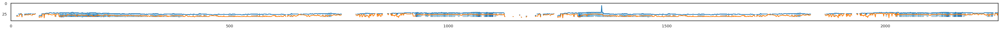

In [70]:
plt.figure(figsize=(60,4))
plt.imshow(np.transpose(rr_2d), cmap='Blues', norm=LogNorm())
plt.plot( np.arange(len(dforbit.cth)), dforbit.cth-200)
plt.plot( np.arange(len(dforbit.cbh)), dforbit.cbh-200)

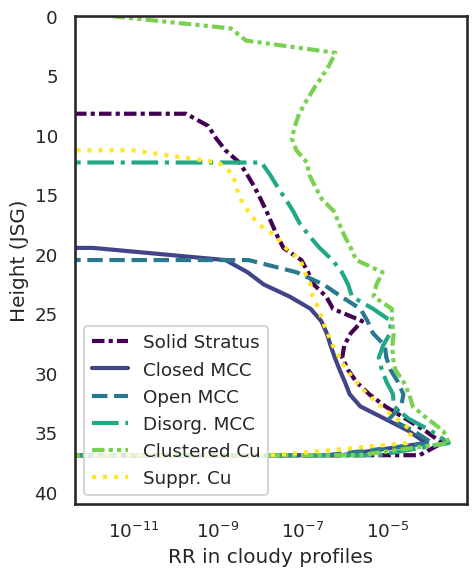

In [42]:
avg_profiles_1d = {}

dffil_valid_rain = dffil[dffil.lwp > 0]

for cat in range(6):
    dffil_cat = dffil_valid_rain[dffil_valid_rain.cats == cat]
    rr_2d = np.stack(dffil_cat.rain_rate_profile.values)
    rr_2d = np.nan_to_num(rr_2d, nan=0)

    avg_profiles_1d[cat] = np.mean(rr_2d, axis=0)

plt.figure(figsize=(5,6))
for cat in range(6):
    profile_cat = avg_profiles_1d[cat]
    h = len(profile_cat)
    plt.plot(profile_cat, np.linspace(0,h,h), color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
plt.xlabel('RR in cloudy profiles')
plt.ylabel('Height (JSG)')
plt.ylim(h,0)
plt.gca().ticklabel_format(axis='x', style='sci', scilimits=(0,0))
plt.xscale('log')
plt.legend()
plt.tight_layout()
plt.show()

Processing category 0
5
6
8
9
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
74
75
76
77
79
83
84
86
87
88
89
90
91
92
93
94
95
113
114
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
141
142
143
152
153
154
155
156
157
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277
278
279
280
281
282
283
284
285
286
287
288
289
290
291
292
293
294
295
296
297
298
299
300
301
302
303
304
305
306
307
308
309
310
311
3

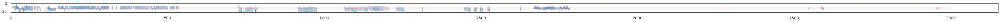

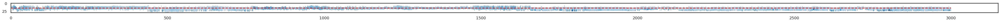

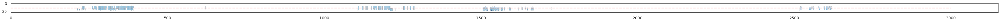

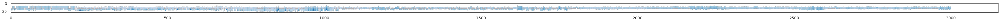

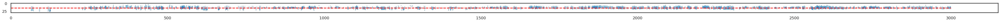

...

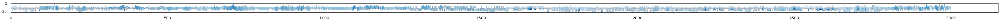

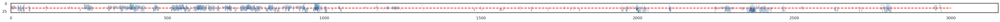

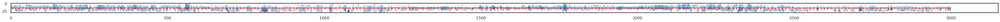

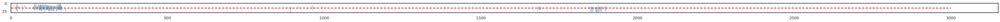

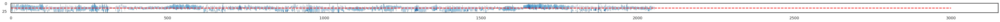

In [ ]:
cat = 1
profile_cat_rain_normed_cbh = {}
profile_cat_rain_normed_cbh_raining_clouds = {}

for cat in range(6):
    print(f'Processing category {cat}')
    dffil_valid_rain = dffil[dffil.lwp > 0]
    dffil_cat = dffil_valid_rain[dffil_valid_rain.cats == cat]

    rr = dffil_cat.rain_rate_profile.values
    cbh = dffil_cat.cbh.values

    num_valid_scenes = 0
    # loop through rain profiles
    # add profile always normalized to the position of the CBH, s.t. rain below CBH has negative height_cbh values and rain inside cloud positive ones
    rr_2d_normed_cbh = np.zeros((len(rr), 30))
    rr_2d_normed_cbh_raining_clouds = np.zeros((len(rr), 30))

    for i in range(len(rr)):
        rr_i = np.nan_to_num(rr[i], nan=0)
        # if all values are nan or zero or a mixture, skip
        if (rr_i == 0).all():
            rr_2d_normed_cbh[i] = np.zeros(30)
            rr_2d_normed_cbh_raining_clouds[i] = np.empty(30)
            rr_2d_normed_cbh_raining_clouds[i][:] = np.nan
            continue
        print(i)

        cbh_ind = int(cbh[i] - 200 - 1)

        rr_i_normed_cbh = np.zeros(30)

        # Get the upper part (above CBH)
        start_upper = max(0, cbh_ind - 15)
        end_upper = cbh_ind
        upper_slice = rr_i[start_upper:end_upper]
        # Pad or trim to length 15
        if len(upper_slice) < 15:
            upper_slice = np.pad(upper_slice, (15 - len(upper_slice), 0), 'constant')
        elif len(upper_slice) > 15:
            upper_slice = upper_slice[-15:]
        rr_i_normed_cbh[:15] = upper_slice

        # Get the lower part (below CBH)
        start_lower = cbh_ind
        end_lower = min(len(rr_i), cbh_ind + 15)
        lower_slice = rr_i[start_lower:end_lower]
        # Pad or trim to length 15
        if len(lower_slice) < 15:
            lower_slice = np.pad(lower_slice, (0, 15 - len(lower_slice)), 'constant')
        elif len(lower_slice) > 15:
            lower_slice = lower_slice[:15]
        rr_i_normed_cbh[15:] = lower_slice

        rr_2d_normed_cbh[i] = rr_i_normed_cbh
        rr_2d_normed_cbh_raining_clouds[i] = rr_i_normed_cbh

    # remove all nan rows from rr_2d_normed_cbh_raining_clouds
    rr_2d_normed_cbh_raining_clouds = rr_2d_normed_cbh_raining_clouds[~np.isnan(rr_2d_normed_cbh_raining_clouds).any(axis=1)]

    plt.figure(figsize=(60,4))
    plt.imshow(np.transpose(rr_2d_normed_cbh[0:3000]), cmap="Blues", norm=LogNorm())
    plt.hlines(15, 0, 3000, colors='red', linestyles='dashed')
    plt.figure(figsize=(60,4))
    plt.imshow(np.transpose(rr_2d_normed_cbh_raining_clouds[0:3000]), cmap="Blues", norm=LogNorm())
    plt.hlines(15, 0, 3000, colors='red', linestyles='dashed')

    rr_2d_normed_cbh_mean = np.mean(rr_2d_normed_cbh, axis=0)
    profile_cat_rain_normed_cbh[cat] = rr_2d_normed_cbh_mean
    rr_2d_normed_cbh_raining_clouds_mean = np.mean(rr_2d_normed_cbh_raining_clouds, axis=0)
    profile_cat_rain_normed_cbh_raining_clouds[cat] = rr_2d_normed_cbh_raining_clouds_mean


Processing category 0
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271


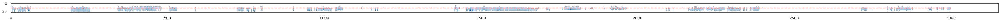

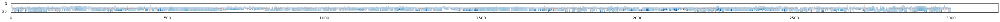

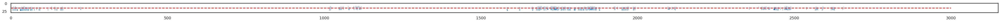

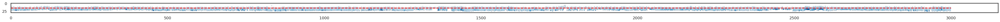

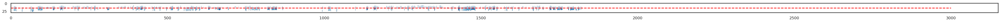

...

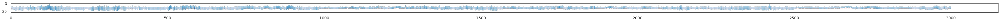

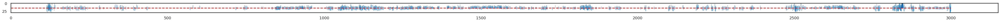

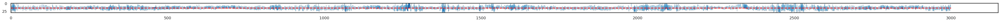

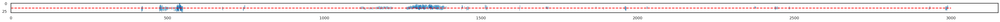

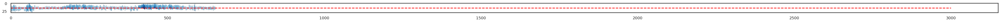

In [160]:
AB_end = pd.to_datetime('2025-05-08')
AC_start = pd.to_datetime('2025-05-09')
AC_end = pd.to_datetime('2025-06-11')
AD_start = pd.to_datetime('2025-06-13')
AD_end = pd.to_datetime('2025-07-07')
BA_start = pd.to_datetime('2025-07-09')
        
profile_cat_rain_normed_cbh = {}
profile_cat_rain_normed_cbh_raining_clouds = {}

for baseline in ['AC', 'AD', 'BA']:
    if baseline == 'AC':
        baseline_mask = (pd.to_datetime(dffil.time) >= AC_start) & (pd.to_datetime(dffil.time) <= AC_end)
    elif baseline == 'AD':
        baseline_mask = (pd.to_datetime(dffil.time) >= AD_start) & (pd.to_datetime(dffil.time) <= AD_end)
    else:
        baseline_mask = (pd.to_datetime(dffil.time) >= BA_start)
    profile_cat_rain_normed_cbh[baseline] = {}
    profile_cat_rain_normed_cbh_raining_clouds[baseline] = {}

    for cat in range(6):
        print(f'Processing category {cat}')
        dffil_valid_rain = dffil[(dffil.lwp > 0) & baseline_mask]
        dffil_cat = dffil_valid_rain[dffil_valid_rain.cats == cat]

        rr = dffil_cat.rain_rate_profile.values
        cbh = dffil_cat.cbh.values

        num_valid_scenes = 0
        # loop through rain profiles
        # add profile always normalized to the position of the CBH, s.t. rain below CBH has negative height_cbh values and rain inside cloud positive ones
        rr_2d_normed_cbh = np.zeros((len(rr), 30))
        rr_2d_normed_cbh_raining_clouds = np.zeros((len(rr), 30))

        for i in range(len(rr)):
            print(i)
            rr_i = np.nan_to_num(rr[i], nan=0)
            # if all values are nan or zero or a mixture, skip
            if (rr_i == 0).all():
                rr_2d_normed_cbh[i] = np.zeros(30)
                rr_2d_normed_cbh_raining_clouds[i] = np.empty(30)
                rr_2d_normed_cbh_raining_clouds[i][:] = np.nan

            else:
                cbh_ind = int(cbh[i] - 200 - 1)

                rr_i_normed_cbh = np.zeros(30)

                # Get the upper part (above CBH)
                start_upper = max(0, cbh_ind - 15)
                end_upper = cbh_ind
                upper_slice = rr_i[start_upper:end_upper]
                # Pad or trim to length 15
                if len(upper_slice) < 15:
                    upper_slice = np.pad(upper_slice, (15 - len(upper_slice), 0), 'constant')
                elif len(upper_slice) > 15:
                    upper_slice = upper_slice[-15:]
                rr_i_normed_cbh[:15] = upper_slice

                # Get the lower part (below CBH)
                start_lower = cbh_ind
                end_lower = min(len(rr_i), cbh_ind + 15)
                lower_slice = rr_i[start_lower:end_lower]
                # Pad or trim to length 15
                if len(lower_slice) < 15:
                    lower_slice = np.pad(lower_slice, (0, 15 - len(lower_slice)), 'constant')
                elif len(lower_slice) > 15:
                    lower_slice = lower_slice[:15]
                rr_i_normed_cbh[15:] = lower_slice

                rr_2d_normed_cbh[i] = rr_i_normed_cbh
                rr_2d_normed_cbh_raining_clouds[i] = rr_i_normed_cbh

        # remove all nan rows from rr_2d_normed_cbh_raining_clouds
        rr_2d_normed_cbh_raining_clouds = rr_2d_normed_cbh_raining_clouds[~np.isnan(rr_2d_normed_cbh_raining_clouds).any(axis=1)]

        plt.figure(figsize=(60,4))
        plt.imshow(np.transpose(rr_2d_normed_cbh[0:3000]), cmap="Blues", norm=LogNorm())
        plt.hlines(15, 0, 3000, colors='red', linestyles='dashed')
        plt.figure(figsize=(60,4))
        plt.imshow(np.transpose(rr_2d_normed_cbh_raining_clouds[0:3000]), cmap="Blues", norm=LogNorm())
        plt.hlines(15, 0, 3000, colors='red', linestyles='dashed')

        rr_2d_normed_cbh_mean = np.mean(rr_2d_normed_cbh, axis=0)
        profile_cat_rain_normed_cbh[baseline][cat] = rr_2d_normed_cbh_mean
        rr_2d_normed_cbh_raining_clouds_mean = np.mean(rr_2d_normed_cbh_raining_clouds, axis=0)
        profile_cat_rain_normed_cbh_raining_clouds[baseline][cat] = rr_2d_normed_cbh_raining_clouds_mean


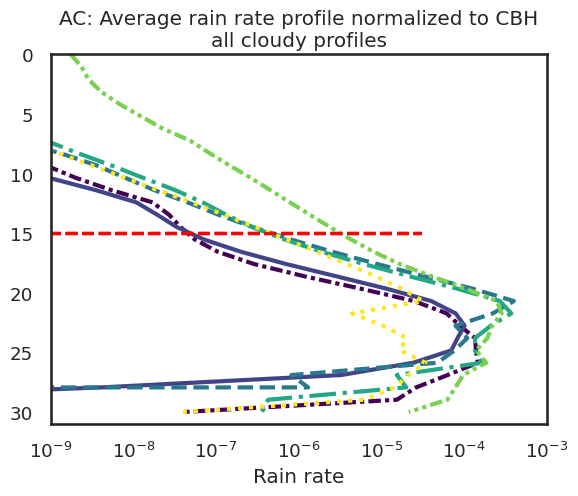

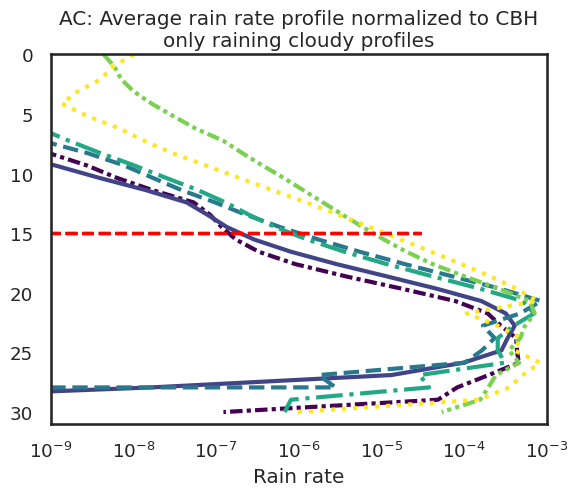

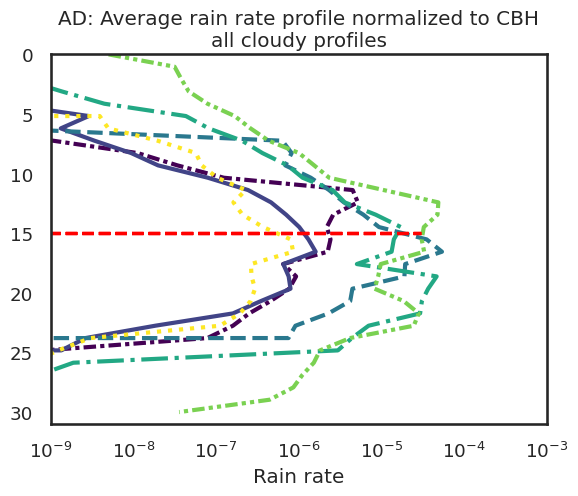

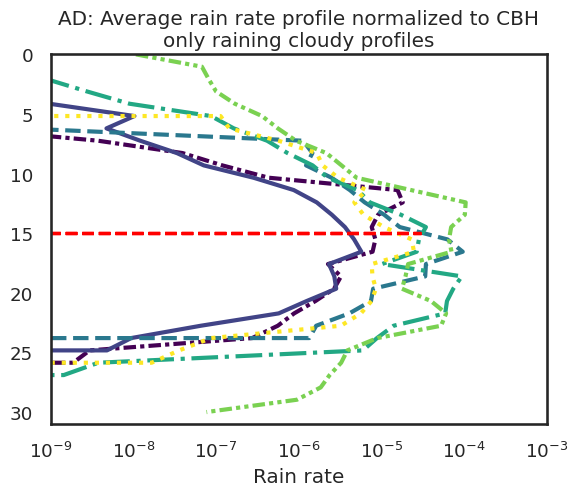

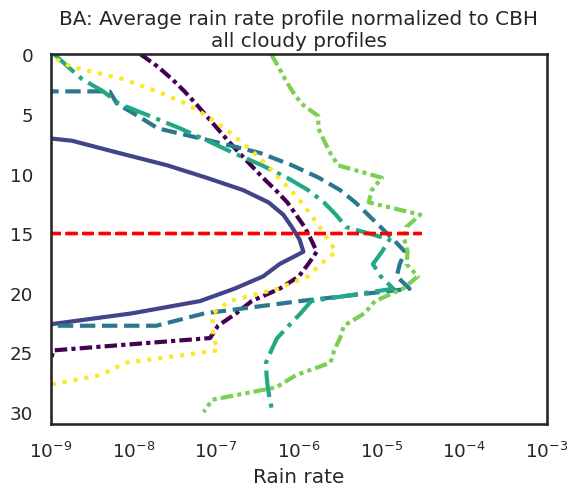

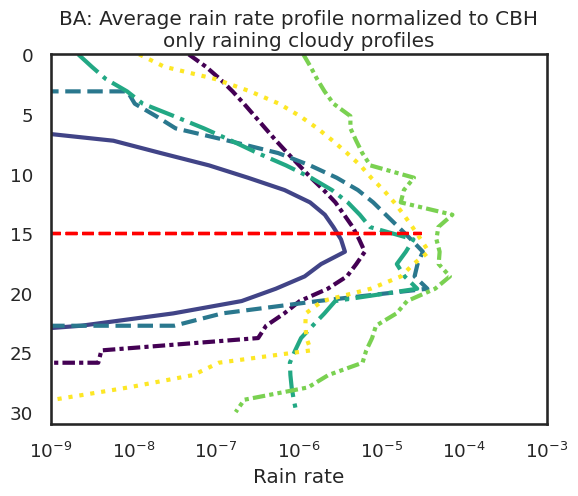

In [165]:
for baseline in ['AC', 'AD', 'BA']:
    for cat in range(6):
        rr_2d_normed_cbh_mean = profile_cat_rain_normed_cbh[baseline][cat]
        h=30
        plt.plot(rr_2d_normed_cbh_mean, np.linspace(0,h,h), color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
        plt.hlines(15, 0, 3e-5, colors='red', linestyles='dashed')
        plt.xscale('log')
        plt.xlim(1e-9,1e-3)
        plt.ylim(31,0)
        plt.title(f'{baseline}: Average rain rate profile normalized to CBH\nall cloudy profiles')
        plt.xlabel('Rain rate')
    plt.show()
    for cat in range(6):
        rr_2d_normed_cbh_mean = profile_cat_rain_normed_cbh_raining_clouds[baseline][cat]
        h=30
        plt.plot(rr_2d_normed_cbh_mean, np.linspace(0,h,h), color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
        plt.hlines(15, 0, 3e-5, colors='red', linestyles='dashed')
        plt.xscale('log')
        plt.xlim(1e-9,1e-3)
        plt.ylim(31,0)
        plt.title(f'{baseline}: Average rain rate profile normalized to CBH\nonly raining cloudy profiles')
        plt.xlabel('Rain rate')
    plt.show()

In [166]:
orbit = '06513E'
filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/*/*/*_{orbit}.h5')[0]
ds = ecio.load_ACMCAP(filename)

Selecting frame from 8 to 4876


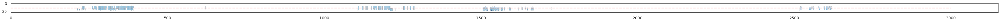

In [128]:
plt.figure(figsize=(60,4))
plt.imshow(np.transpose(rr_2d_normed_cbh[0:3000]), cmap="Blues", norm=LogNorm())
plt.hlines(15, 0, 3000, colors='red', linestyles='dashed')

In [ ]:
avg_rain_profiles_1d_normed_cbh = {}

dffil_valid_rain = dffil[dffil.lwp > 0]

for cat in range(6):
    dffil_cat = dffil_valid_rain[dffil_valid_rain.cats == cat]
    rr = dffil_cat.rain_rate_profile.values
    profile_cat = xr.DataArray(np.zeros(30), dims=['height_cbh'], coords={'height_cbh': np.linspace(-15,15,30)})

    num_valid_scenes = 0
    # loop through rain profiles
    # add profile always normalized to the position of the CBH, s.t. rain below CBH has negative height_cbh values and rain inside cloud positive ones
    for i in range(len(rr)):
        if np.isnan(rr.iloc[i]):
            continue
        thickness_i = int(thickness.iloc[i] // 100)
        profile_cat[max(0, 30 - thickness_i):30] += rr[i]
        num_valid_scenes += 1

plt.figure(figsize=(5,6))
for cat in range(6):
    profile_cat = avg_profiles_1d_normed_cth[cat]
    h = len(profile_cat)
    plt.plot(profile_cat, np.linspace(0,h,h) + 200, color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
plt.xlabel('LWC (g/m3)')
plt.ylabel('Height (JSG)')
plt.ylim(h + 200,200)
plt.legend()
plt.tight_layout()
plt.show()

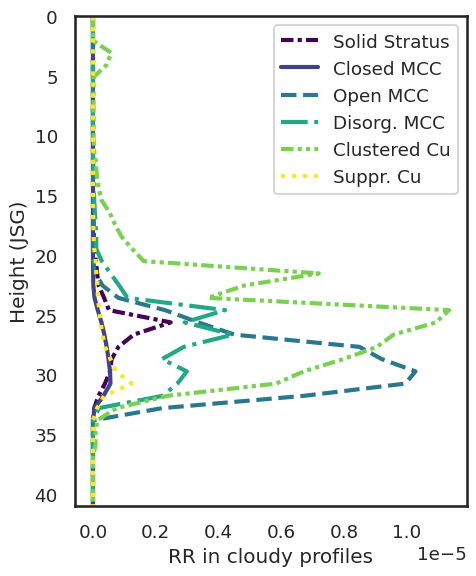

In [41]:
avg_profiles_1d = {}

dffil_valid_rain = dffil[dffil.lwp > 0]

for cat in range(6):
    dffil_cat = dffil_valid_rain[dffil_valid_rain.cats == cat]
    rr_2d = np.stack(dffil_cat.rain_rate_below_cloud_profile.values)
    rr_2d = np.nan_to_num(rr_2d, nan=0)

    avg_profiles_1d[cat] = np.mean(rr_2d, axis=0)

plt.figure(figsize=(5,6))
for cat in range(6):
    profile_cat = avg_profiles_1d[cat]
    h = len(profile_cat)
    plt.plot(profile_cat, np.linspace(0,h,h), color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
plt.xlabel('RR in cloudy profiles')
plt.ylabel('Height (JSG)')
plt.ylim(h,0)
plt.gca().ticklabel_format(axis='x', style='sci', scilimits=(0,0))
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#profiles_1d = {}
#avg_scale = 10
#
#for cat in range(6):
#    profile_cat = None
#    cbh = dffil[dffil.cats == cat].cbh_m
#    cth = dffil[dffil.cats == cat].cth_m
#
#    for i in range(len(cbh)//avg_scale):
#        profile_cat_i = np.zeros(30)
#        for ii in range(avg_scale):
#            idx = i*avg_scale + ii
#            if np.isnan(cbh.iloc[idx]) or np.isnan(cth.iloc[idx]):
#                continue
#            cbh_i = int(cbh.iloc[idx] // 100)
#            cth_i = int(cth.iloc[idx] // 100)
#
#            profile_cat_i[cbh_i:min(30, cth_i+1)] += 1
#        profile_cat_i = profile_cat_i / avg_scale
#        
#        if profile_cat is None:
#            profile_cat = profile_cat_i
#        else:
#            profile_cat = np.vstack((profile_cat, profile_cat_i))
#            
#    profiles_1d[cat] = profile_cat

In [ ]:
profiles_normed_cth_1d = {}

for cat in range(6):
    profile_cat = None
    cbh = dffil[dffil.cats == cat].cbh_m
    cth = dffil[dffil.cats == cat].cth_m
    thickness = cth - cbh + 100

    quantiles = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
    quantile_vals = thickness.quantile(quantiles).values

    for i in range(1, len(quantile_vals)):
        profile_cat_i = np.zeros(30)
        thickness_quant = thickness[(thickness >= quantile_vals[i-1]) & (thickness < quantile_vals[i])]
        for ii in range(len(thickness_quant)):
            if np.isnan(thickness_quant.iloc[ii]):
                continue
            thickness_ii = int(thickness_quant.iloc[ii] // 100)
            profile_cat_i[max(0, 30 - thickness_ii):30] += 1

        profile_cat_i = profile_cat_i / len(thickness_quant)

        if profile_cat is None:
            profile_cat = profile_cat_i
        else:
            profile_cat = np.vstack((profile_cat, profile_cat_i))
            
    profiles_normed_cth_1d[cat] = profile_cat

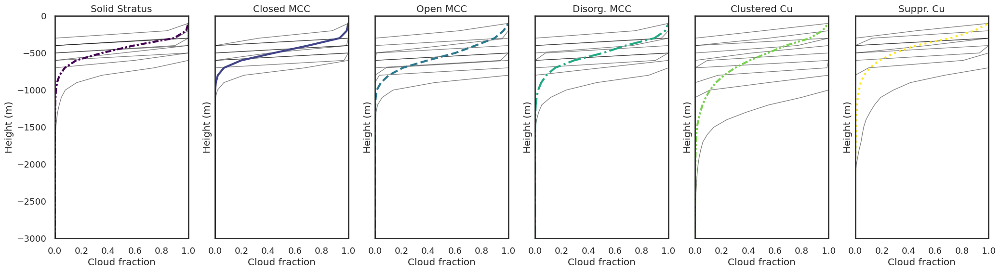

In [ ]:
fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(25,6), sharey=True)
quantiles = [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]
for cat in range(6):
    profile_cat = profiles_normed_cth_1d[cat]
    for i in range(profile_cat.shape[0]):
        axs[cat].plot(profile_cat[i], np.arange(30)*100 - 3000, color='black', alpha=0.5, lw=1)
    avg_profile_cat = avg_profiles_1d_normed_cth[cat]
    axs[cat].plot(avg_profile_cat.values, avg_profile_cat['height'].values - 3000, color=catcolors[cat], lw=3, label=cats_names[cat], linestyle=line_styles[cat])
    axs[cat].set_xlabel('Cloud fraction')
    axs[cat].set_ylabel('Height (m)')
    axs[cat].set_title(cats_names[cat])
    axs[cat].set_xlim(0,1)
    axs[cat].set_ylim(-3000,0)

## relationships: LWP, H, RWP, coupling

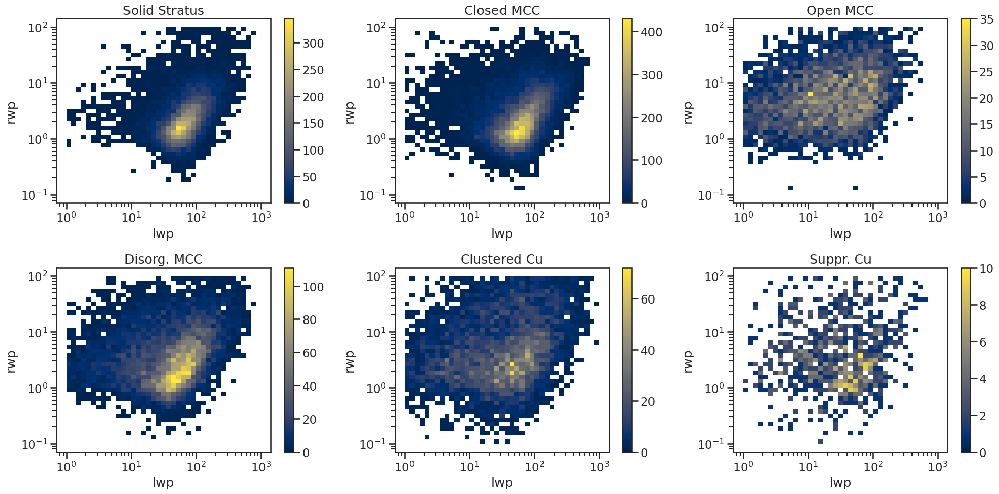

In [54]:
fig, axs = plt.subplots(2,3,figsize=(20,10))
for i in [0,1,2,3,4,5]:
    sns.histplot(ax=axs.flatten()[i], data=dffil[dffil.cats==i], x='lwp', y='rwp', bins=( np.logspace(0,3,40), np.logspace(-1,2,40)), cbar=True, cmap='cividis')
    xline = np.linspace(0,15,100)
    yline = (xline)**2 + 10
    #axs.flatten()[i].plot(xline, yline, color='black', lw=2)
    axs.flatten()[i].set_yscale('log')
    axs.flatten()[i].set_xscale('log')
    axs.flatten()[i].set_title(cats_names[i])
fig.tight_layout()

Text(0.5, 1.0, 'Mean RWP given LWP for different cloud categories')

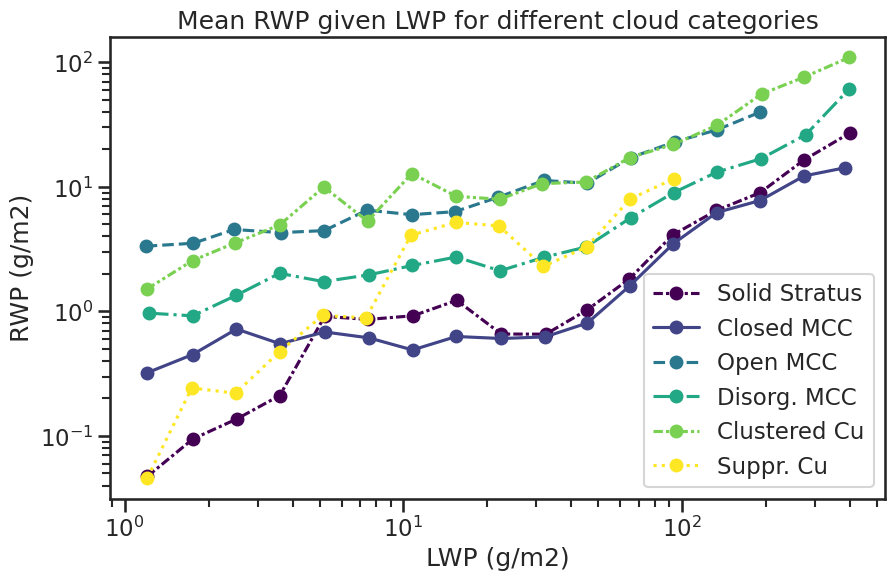

In [116]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for i in [0,1,2,3,4,5]:
    tmp = dffil[(dffil.cats==i)]
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 100, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP for different cloud categories')

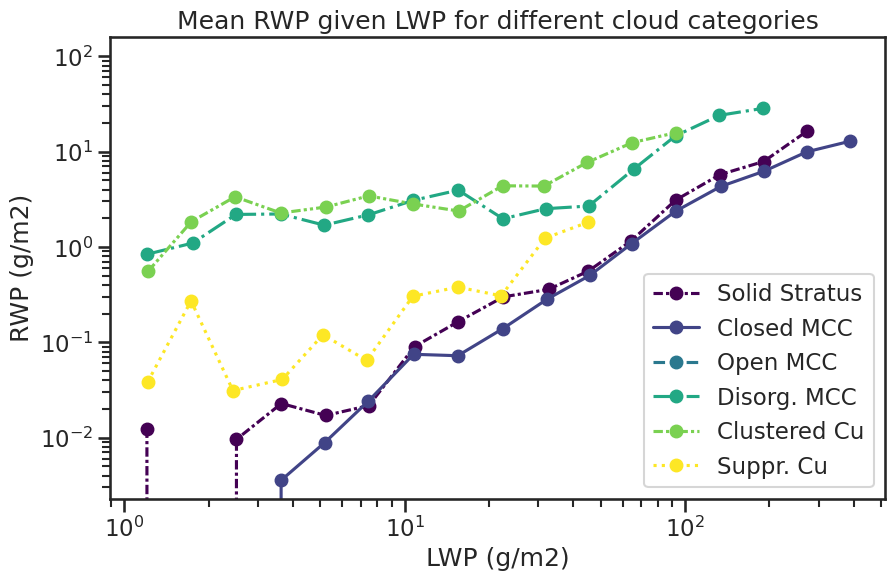

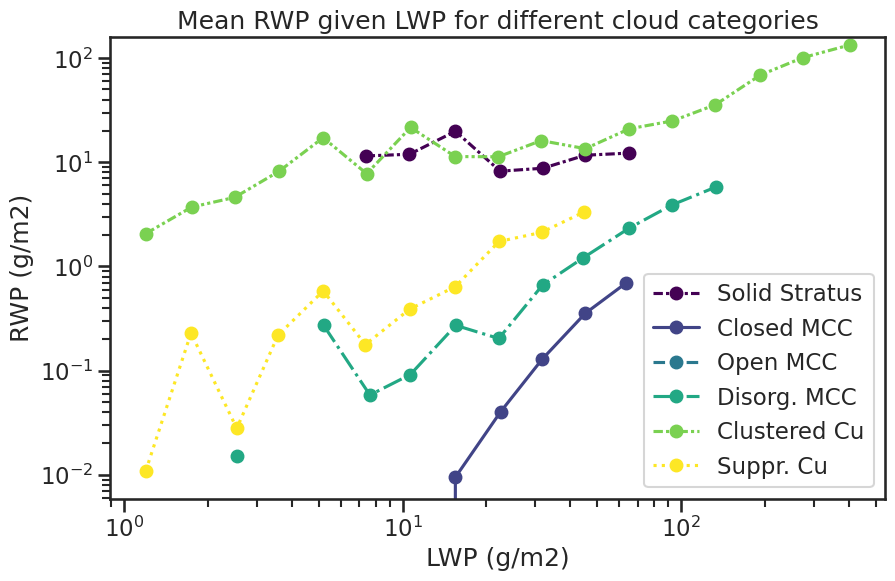

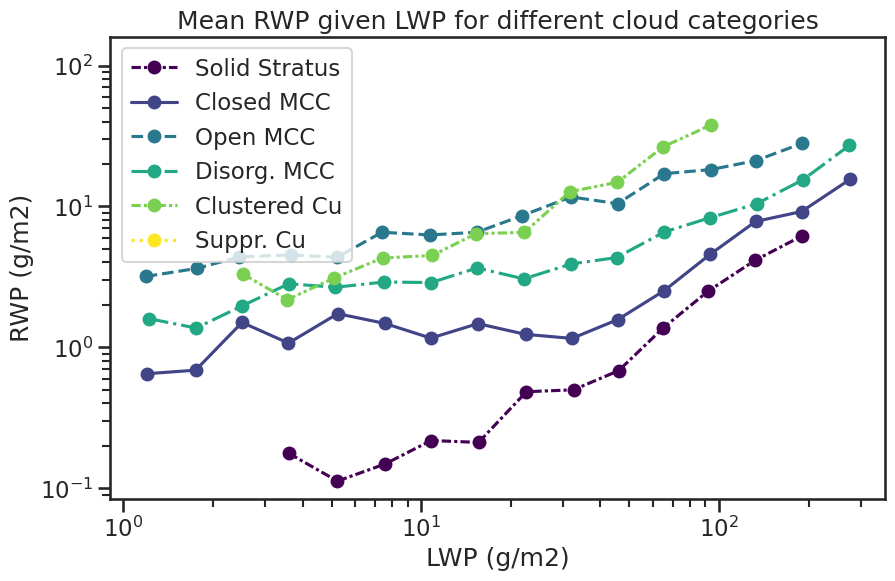

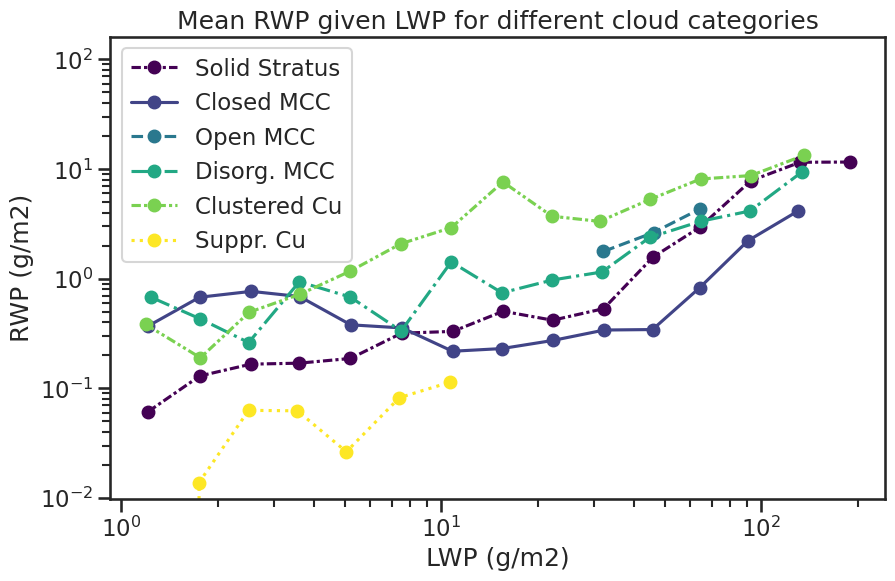

In [ ]:
for sr in [0,1,2,3]:
    fig, axs = plt.subplots(1,1,figsize=(10,6))
    for i in [0,1,2,3,4,5]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 100, np.nan)
        rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    plt.ylim(-10,160)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('RWP (g/m2)')
    plt.title('Mean RWP given LWP for different cloud categories')

Text(0.5, 1.0, 'Mean RWP given LWP for different regions')

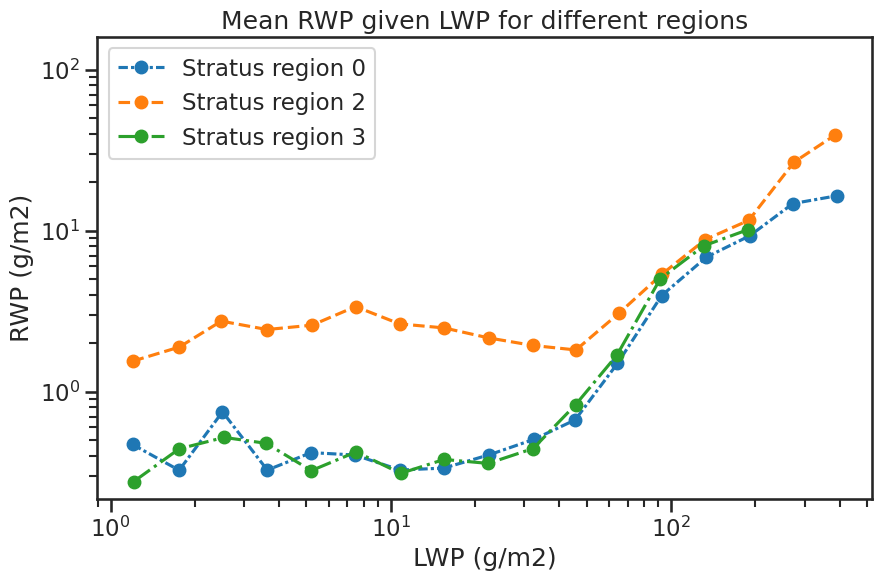

In [124]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,2,3]:
    tmp = dffil[(dffil.stratus_region_index == sr) & (dffil.cats.isin([0,1,2]))]
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 100, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=f'Stratus region {sr}', linestyle=line_styles[sr])
plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP for different regions')

Text(0.5, 1.0, 'Mean RWP given LWP for different cloud categories')

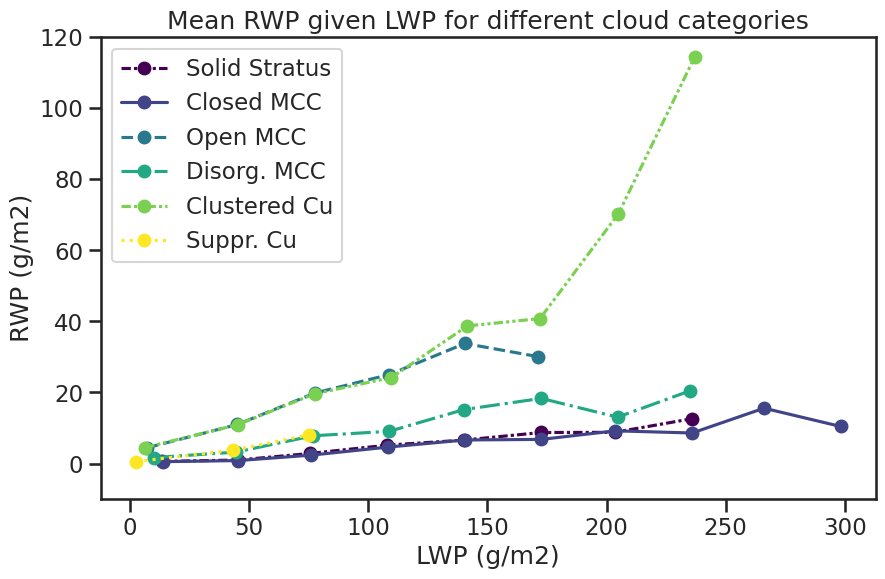

In [118]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for i in [0,1,2,3,4,5]:
    tmp = dffil[(dffil.cats==i)]
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.linspace(0,600,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.linspace(0,600,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 100, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=False, marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
plt.ylim(-10,120)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP for different cloud categories')

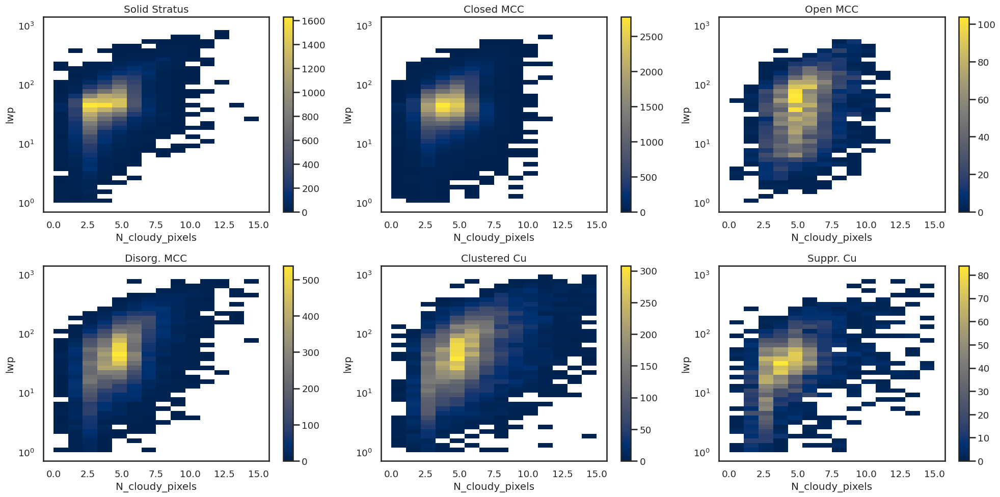

In [ ]:
fig, axs = plt.subplots(2,3,figsize=(20,10))
for i in [0,1,2,3,4,5]:
    sns.histplot(ax=axs.flatten()[i], data=dffil[dffil.cats==i], y='lwp', x='N_cloudy_pixels', bins=( np.linspace(0,15,15), np.logspace(0,3,40)), cbar=True, cmap='cividis')
    xline = np.linspace(0,15,100)
    yline = (xline)**2 + 10
    #axs.flatten()[i].plot(xline, yline, color='black', lw=2)
    axs.flatten()[i].set_yscale('log')
    axs.flatten()[i].set_title(cats_names[i])
fig.tight_layout()

In [24]:
def plot_prob_density(yvar, xvar, df, xmin=None, xmax=None, ymax=None, ymin=None, bins=51, yscale='linear'):
    if xmin is None:
        xmin = df[xvar].quantile(0.01)
    if xmax is None:
        xmax = df[xvar].quantile(0.99)
    if ymin is None:
        ymin = df[yvar].quantile(0.01)
    if ymax is None:
        ymax = df[yvar].quantile(0.99)

    if yscale == 'log':
        bins_y = np.logspace(np.log10(ymin), np.log10(ymax), bins)
    else:
        bins_y = np.linspace(ymin, ymax, bins)
        
    ds_result = uana.create_prob_density_dataset(df[[yvar,xvar]].to_xarray(), varx=xvar, vary=yvar, bins_x=np.linspace(xmin,xmax,bins), bins_y=bins_y)

    fig, axs = plt.subplots(2, 1, figsize=(9, 7), sharex=True, layout='constrained', gridspec_kw={'height_ratios': [4, 1]})

    pcm = ds_result.T.plot(ax=axs[0], cmap='inferno_r', vmax=0.2, add_colorbar=False, xlim=(xmin, xmax), ylim=(ymin, ymax))
    cbar = fig.colorbar(pcm, ax=axs[0], shrink=0.9, label=f'P({yvar} | {xvar})')
    axs[0].set_yscale(yscale)

    df[xvar].plot.hist(ax=axs[1], bins=np.linspace(xmin,xmax,bins), histtype='step')
    axs[1].set_ylabel('counts')
    axs[1].set_xlabel(xvar)

    #coeff, const = plot_regression_line(yvar, xvar, ax=axs[0], df=df)

    return fig, axs

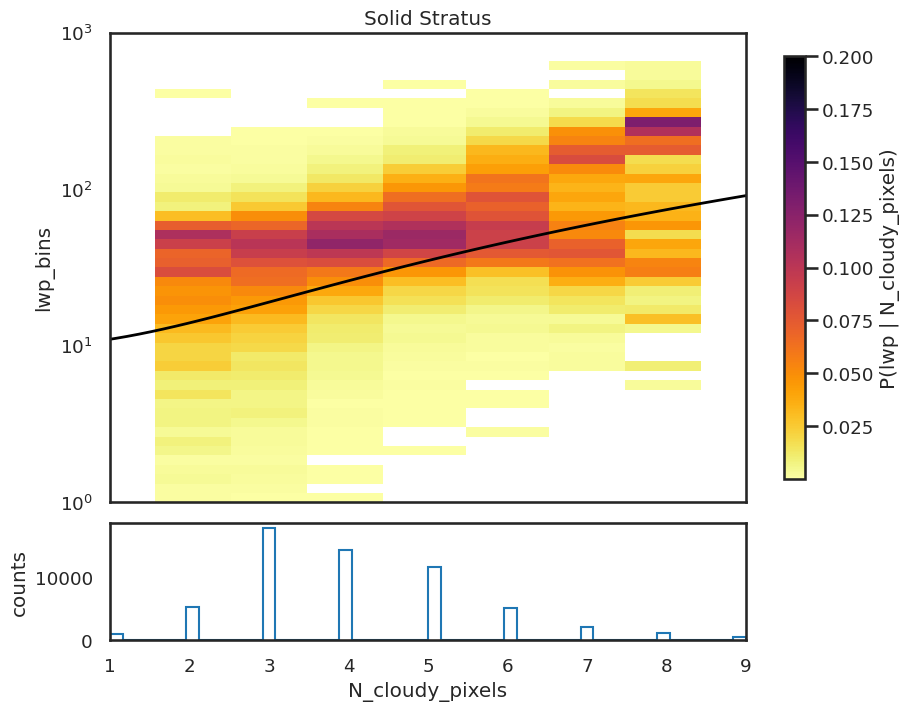

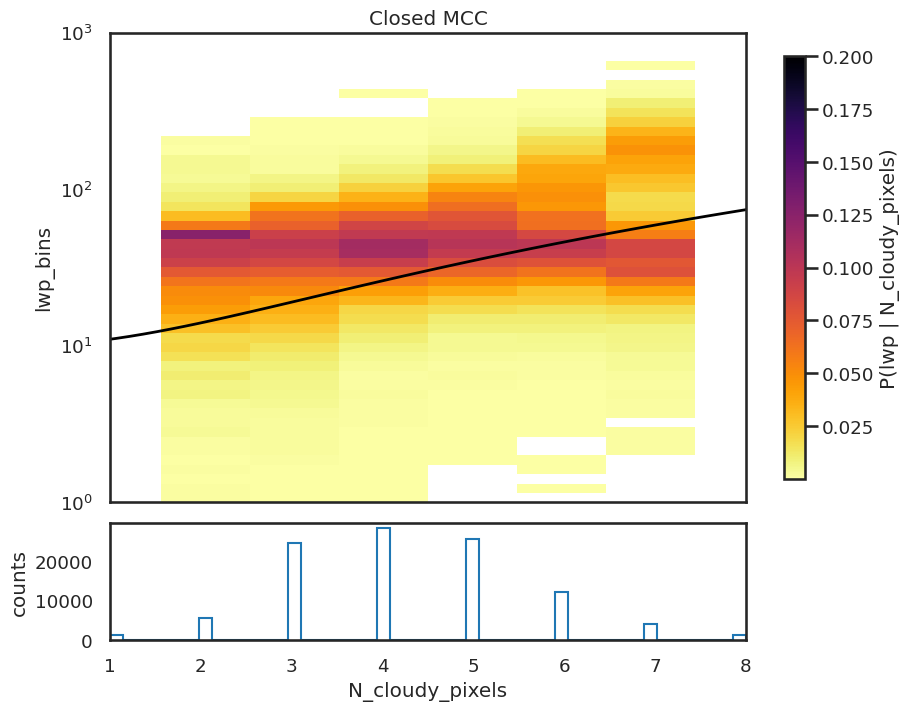

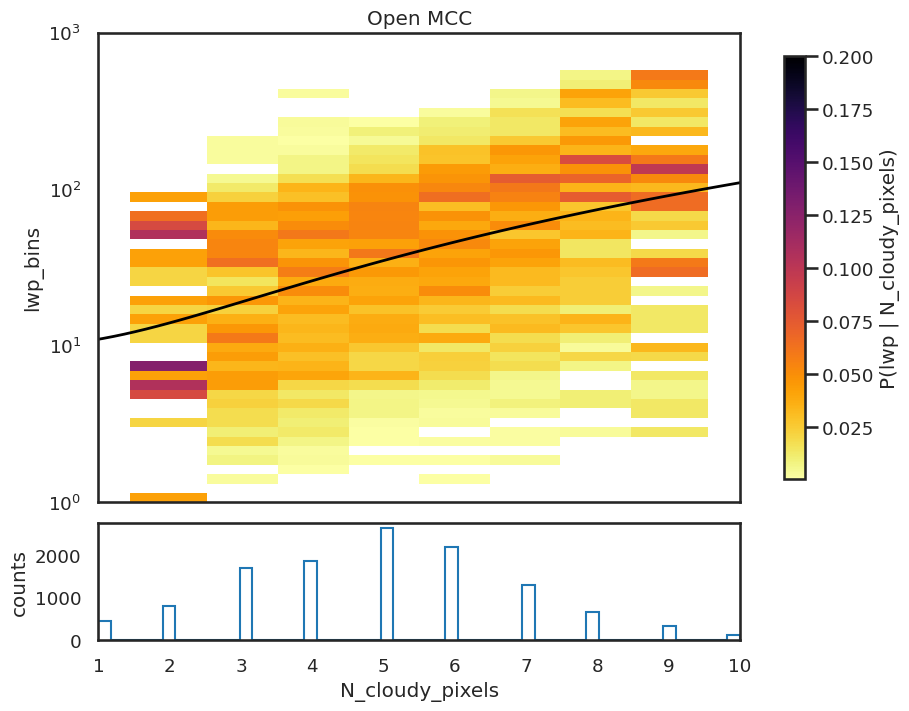

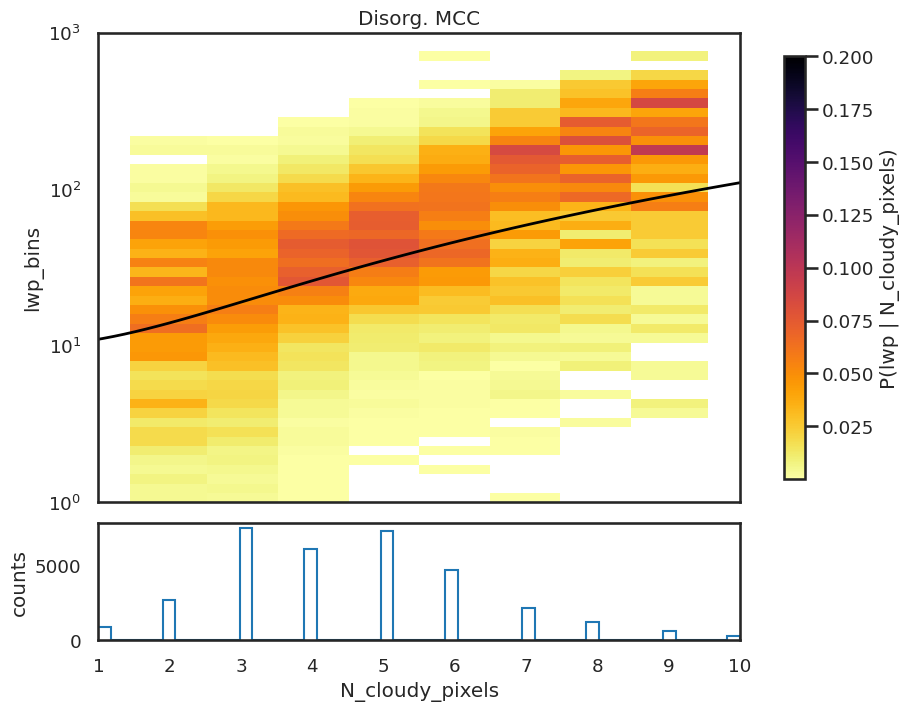

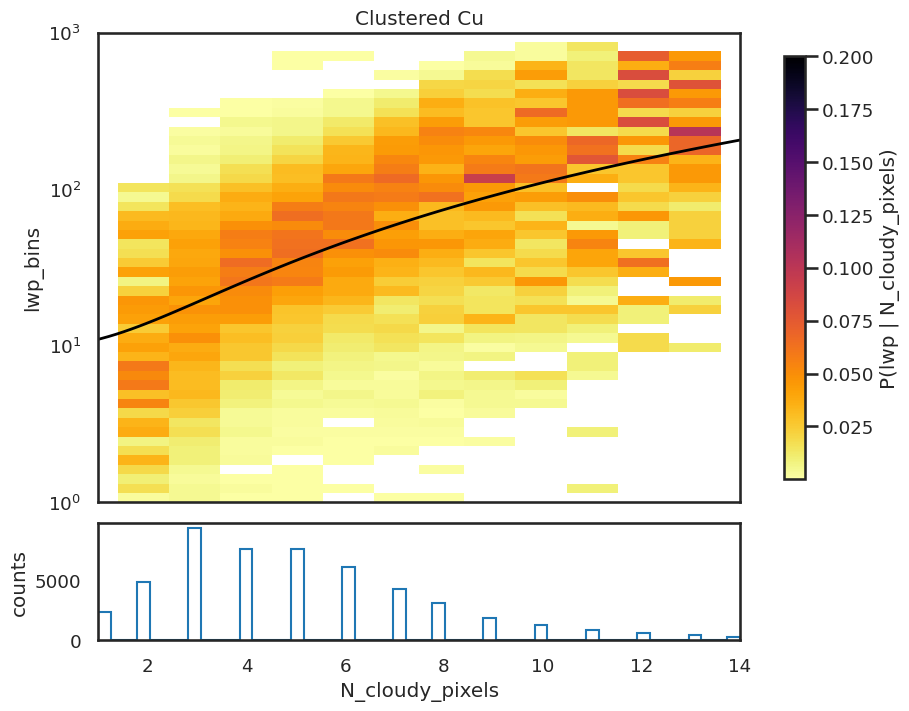

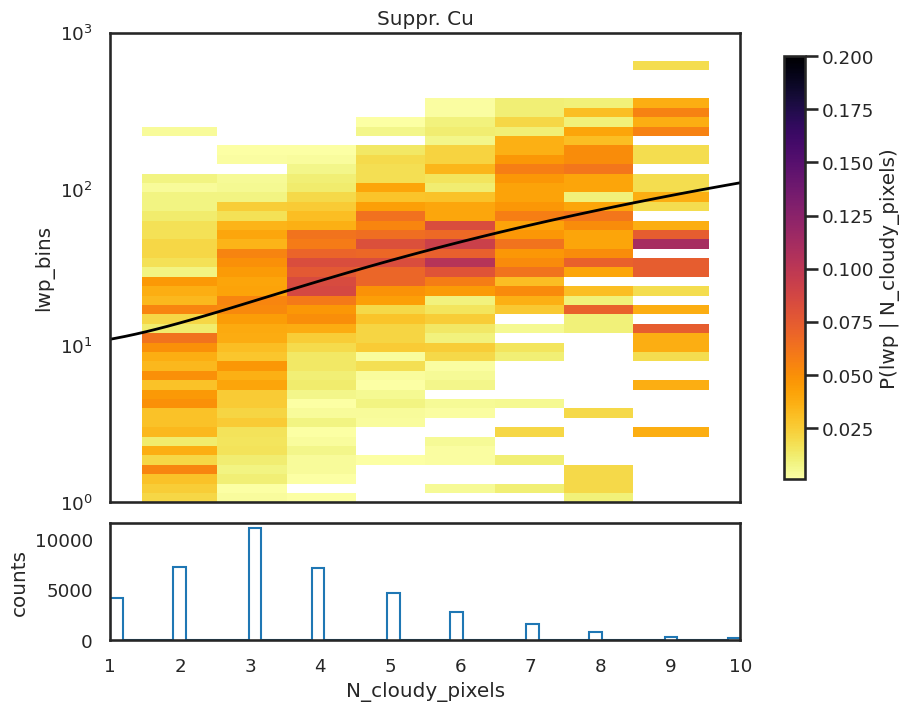

In [84]:
for i in [0,1,2,3,4,5]:
    fig, axs = plot_prob_density('lwp', 'N_cloudy_pixels', dffil[dffil.cats == i], ymin=1, ymax=1e3, yscale='log')
    xline = np.linspace(0,15,100)
    yline = (xline)**2 + 10
    axs[0].plot(xline, yline, color='black', lw=2)
    axs[0].set_title(cats_names[i])


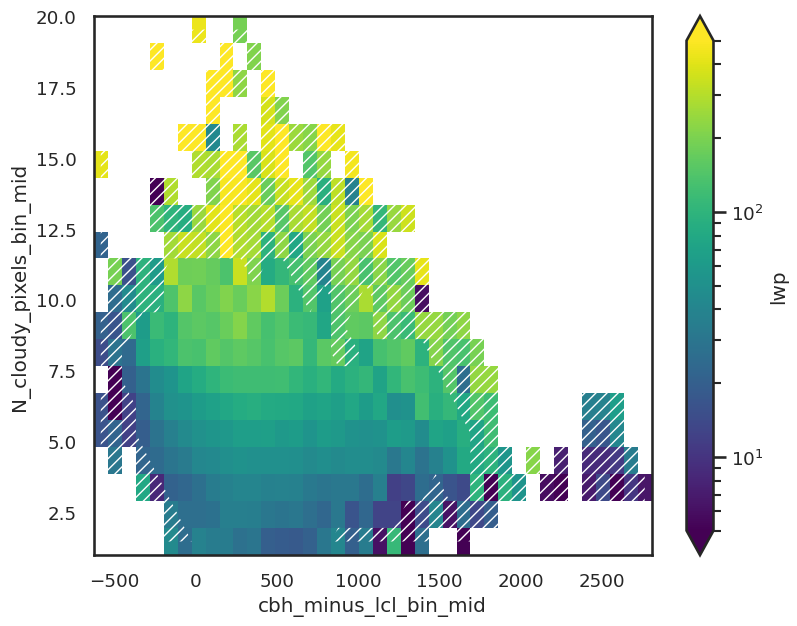

In [88]:
from matplotlib.colors import LogNorm

x = 'cbh_minus_lcl'
y = 'N_cloudy_pixels'
z = 'lwp'
tmp = dffil[[x, y, z]]
tmp = tmp[tmp[z] > 0]
tmp = tmp.dropna()

# Define bins for x and y (you can customize the bin edges)
x_bins = pd.cut(tmp[x], bins=40)
y_bins = pd.cut(tmp[y], bins=20)

# Add binned columns to the DataFrame
tmp[x+'_bin'] = x_bins
tmp[y+'_bin'] = y_bins
# save the midpoint of each bin interval in the tmp DataFrame
tmp[x+'_bin_mid'] = tmp[x+'_bin'].apply(lambda x: x.mid)
tmp[y+'_bin_mid'] = tmp[y+'_bin'].apply(lambda x: x.mid)

heatmap_data = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].mean().to_xarray()
heatmap_data.T.plot(figsize=(9,7), norm =LogNorm(), vmin=5e0, vmax=5e2) 

# set colorbar scale to log
# Overlay pattern "/" to indicate regions with low counts (<10)
heatmap_data_counts = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].count().to_xarray()
mask = (heatmap_data_counts.T < 20)
plt.contourf(
	mask.coords[x+'_bin_mid'],
	mask.coords[y+'_bin_mid'],
	mask.values,  # invert mask: True where you want hatching
	levels=[0.5, 1],
	hatches=['///'],
	colors='none'
)

ax = plt.gca()
#ax.set_xlabel('Nd [cm$^{-3}$]')
#ax.set_ylabel('LWP [g m$^{-2}$]')
plt.show()

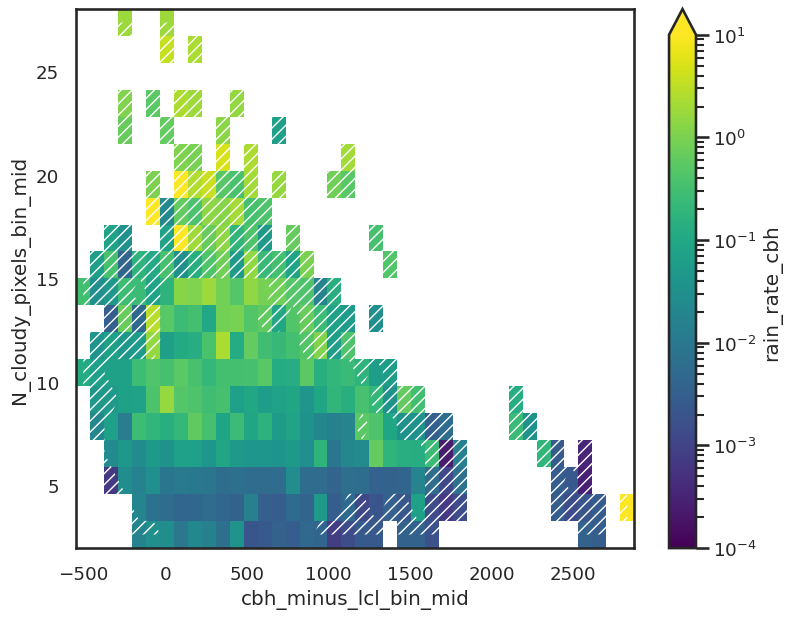

In [97]:
from matplotlib.colors import LogNorm

x = 'cbh_minus_lcl'
y = 'N_cloudy_pixels'
z = 'rain_rate_cbh'
tmp = dffil[[x, y, z]]
tmp[z] = tmp[z] * 3600 
tmp = tmp[tmp[z] > 0]
tmp = tmp.dropna()

# Define bins for x and y (you can customize the bin edges)
x_bins = pd.cut(tmp[x], bins=40)
y_bins = pd.cut(tmp[y], bins=20)

# Add binned columns to the DataFrame
tmp[x+'_bin'] = x_bins
tmp[y+'_bin'] = y_bins
# save the midpoint of each bin interval in the tmp DataFrame
tmp[x+'_bin_mid'] = tmp[x+'_bin'].apply(lambda x: x.mid)
tmp[y+'_bin_mid'] = tmp[y+'_bin'].apply(lambda x: x.mid)

heatmap_data = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].mean().to_xarray()
heatmap_data.T.plot(figsize=(9,7), norm =LogNorm(), vmin=1e-4, vmax=1e1) 

# set colorbar scale to log
# Overlay pattern "/" to indicate regions with low counts (<10)
heatmap_data_counts = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].count().to_xarray()
mask = (heatmap_data_counts.T < 20)
plt.contourf(
	mask.coords[x+'_bin_mid'],
	mask.coords[y+'_bin_mid'],
	mask.values,  # invert mask: True where you want hatching
	levels=[0.5, 1],
	hatches=['///'],
	colors='none'
)

ax = plt.gca()
#ax.set_xlabel('Nd [cm$^{-3}$]')
#ax.set_ylabel('LWP [g m$^{-2}$]')
plt.show()

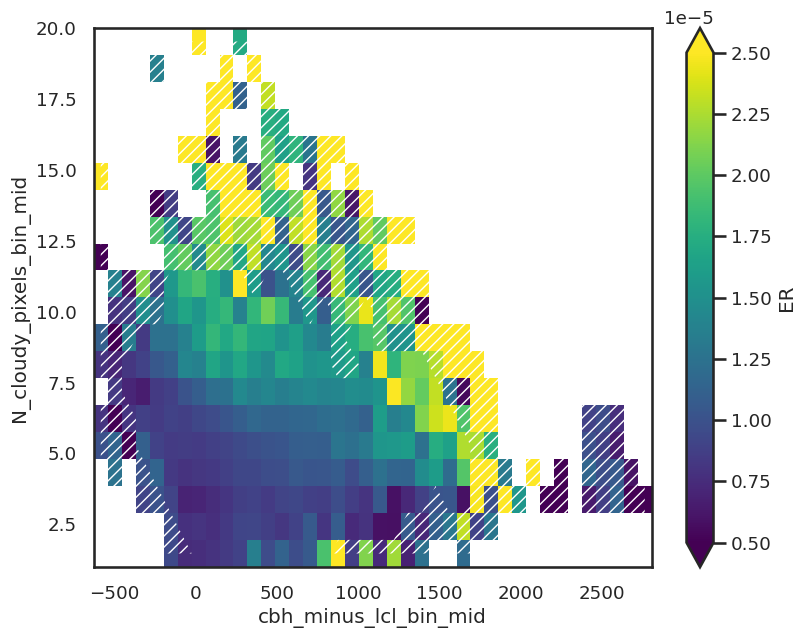

In [94]:
from matplotlib.colors import LogNorm

x = 'cbh_minus_lcl'
y = 'N_cloudy_pixels'
z = 'ER'
tmp = dffil[[x, y, z]]
tmp = tmp[tmp[z] > 0]
tmp = tmp.dropna()

# Define bins for x and y (you can customize the bin edges)
x_bins = pd.cut(tmp[x], bins=40)
y_bins = pd.cut(tmp[y], bins=20)

# Add binned columns to the DataFrame
tmp[x+'_bin'] = x_bins
tmp[y+'_bin'] = y_bins
# save the midpoint of each bin interval in the tmp DataFrame
tmp[x+'_bin_mid'] = tmp[x+'_bin'].apply(lambda x: x.mid)
tmp[y+'_bin_mid'] = tmp[y+'_bin'].apply(lambda x: x.mid)

heatmap_data = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].mean().to_xarray()
heatmap_data.T.plot(figsize=(9,7), vmin=5e-6, vmax=25e-6) 
#heatmap_data.T.plot(figsize=(9,7), norm =LogNorm(), vmin=5e-6, vmax=5e-5) 

# Overlay pattern "/" to indicate regions with low counts (<10)
heatmap_data_counts = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].count().to_xarray()
mask = (heatmap_data_counts.T < 20)
plt.contourf(
	mask.coords[x+'_bin_mid'],
	mask.coords[y+'_bin_mid'],
	mask.values,  # invert mask: True where you want hatching
	levels=[0.5, 1],
	hatches=['///'],
	colors='none'
)

ax = plt.gca()
#ax.set_xlabel('Nd [cm$^{-3}$]')
#ax.set_ylabel('LWP [g m$^{-2}$]')
plt.show()

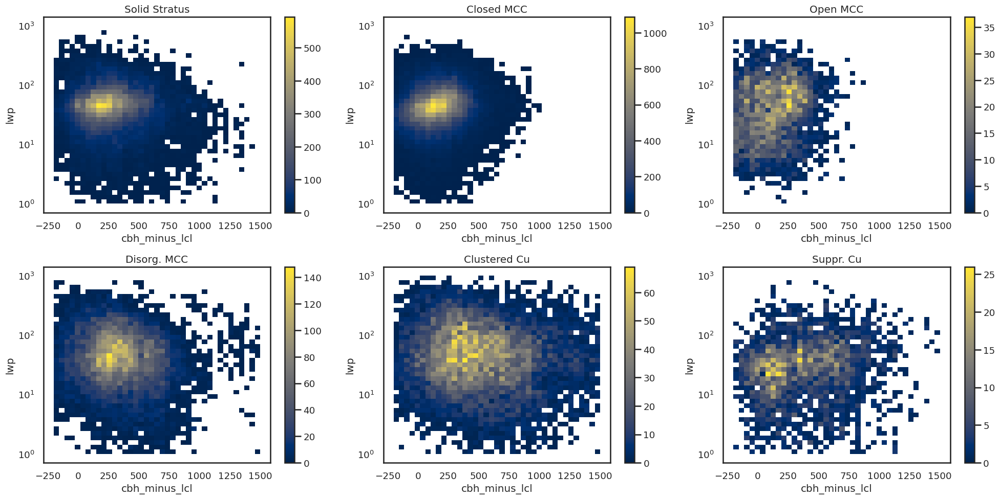

In [47]:
fig, axs = plt.subplots(2,3,figsize=(20,10))
for i in [0,1,2,3,4,5]:
    sns.histplot(ax=axs.flatten()[i], data=dffil[dffil.cats==i], y='lwp', x='cbh_minus_lcl', bins=( np.linspace(-200,1500,40), np.logspace(0,3,40)), cbar=True, cmap='cividis')
    axs.flatten()[i].set_yscale('log')
    axs.flatten()[i].set_title(cats_names[i])
fig.tight_layout()

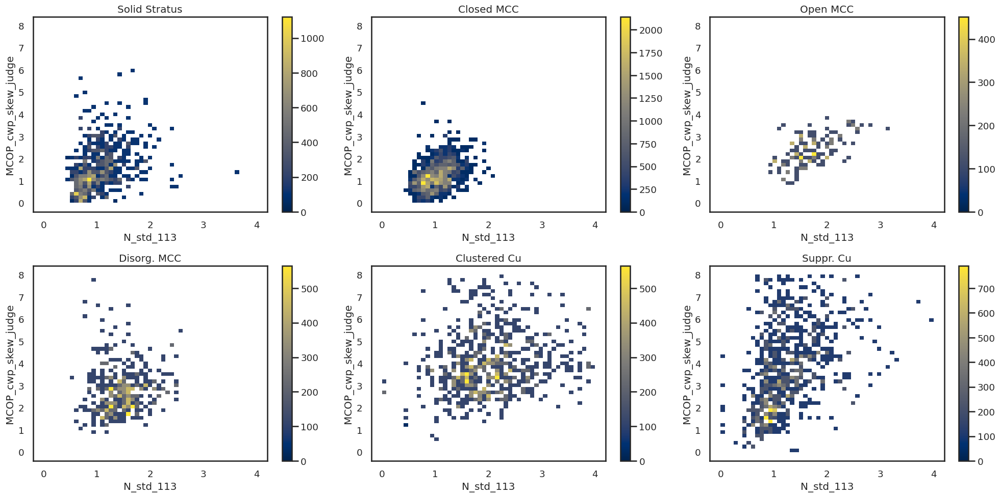

In [50]:
fig, axs = plt.subplots(2,3,figsize=(20,10))
for i in [0,1,2,3,4,5]:
    sns.histplot(ax=axs.flatten()[i], data=dffil[dffil.cats==i], y='MCOP_cwp_skew_judge', x='N_std_113', bins=(np.linspace(0,4,50), np.linspace(0,8,50)), cbar=True, cmap='cividis')
    axs.flatten()[i].set_title(cats_names[i])
fig.tight_layout()

<Axes: xlabel='MCOP_cwp_skew_judge', ylabel='N_std_113'>

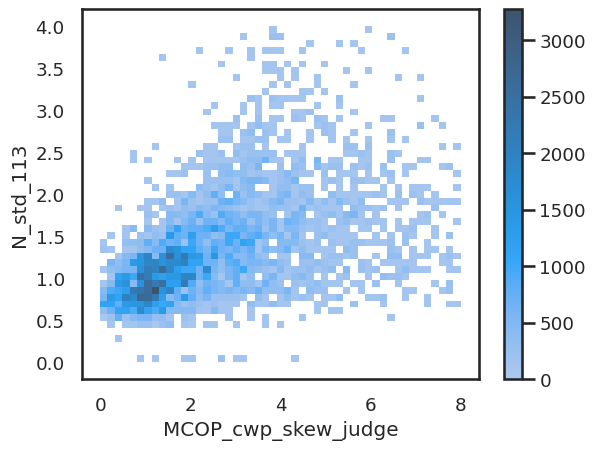

In [51]:
sns.histplot(data=dffil, y='N_std_113', x='MCOP_cwp_skew_judge', bins=(np.linspace(0,8,50), np.linspace(0,4,50)), cbar=True)

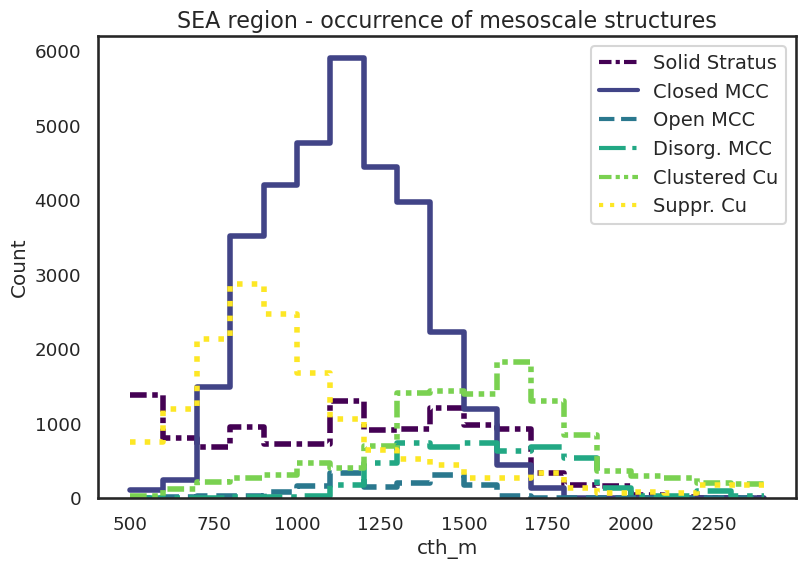

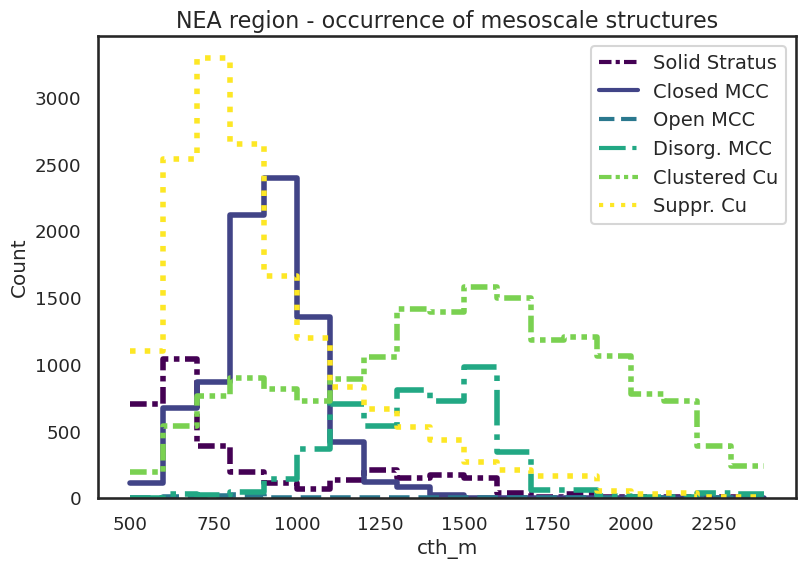

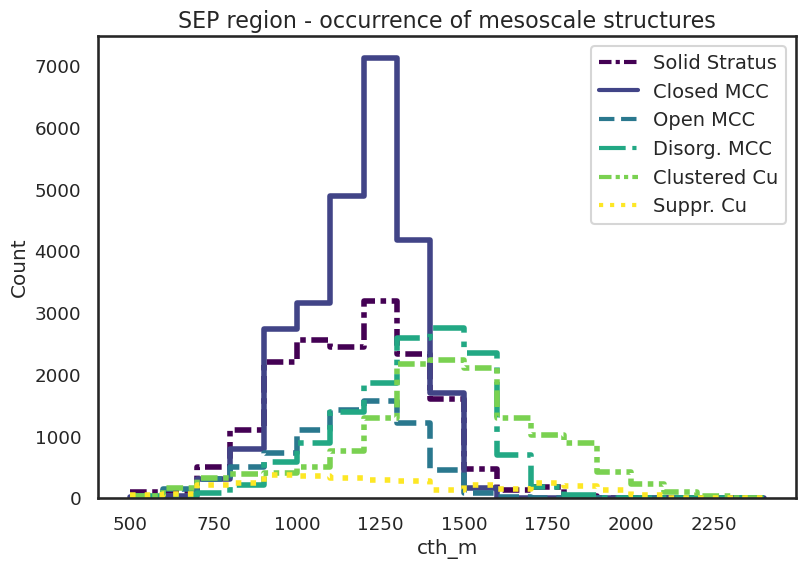

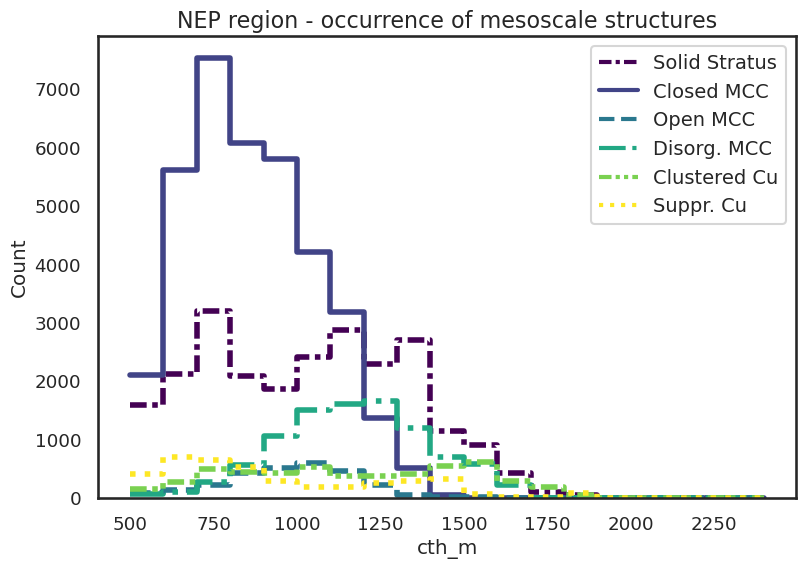

In [39]:
cth_bins = np.arange(500,2500,100)
for sr in [0,1,2,3]:
    plt.figure(figsize=(9,6))
    for i in np.unique(dffil['cats']):
        sns.histplot(data=dffil[(dffil['cats'] == i) & (dffil['stratus_region_index'] == sr)], x='cth_m', bins=cth_bins, element='step', fill=False, stat='count', label=f'cluster {i}', color=catcolors[i], ls = line_styles[i], lw=4)
    plt.title(f'{stratus_region_names[sr]} region - occurrence of mesoscale structures', fontsize=16)
    plt.legend(handles=legend_elements, fontsize=14)